# 07MIAR - Redes Neuronales y Deep Learning
# Proyecto de programación: "Deep Vision in classification tasks"

## Autor: Ángel González De La Vara

# 1. Introducción y descripción del problema

En este proyecto se selecciona un conjunto de datos de imágenes y se realiza el desarrollo de un modelo de clasificación basado en aprendizaje profundo, utilizando redes neuronales convolucionales (CNNs).
El objetivo principal del proyecto es evaluar y comparar experimentalmente dos estrategias diferentes para abordar el problema de clasificación de imágenes:


1.   Entrenar una CNN desde cero.
2.   Utilizar una arquitectura preentrenada mediante transfer learning y fine-tuning.

En concreto, el problema a resolver planteado en este proyecto es la clasificación de imágenes en dos clases: reales o generadas sintéticamente mediante inteligencia artificial. Se ha elegido este tema por su relevancia actual, ya que tanto las redes sociales como los medios de comunicación contienen cada vez más contenido audiovisual generado sintéticamente, como *deep fakes* o imágenes falsas, lo que favorece la desinformación y genera desconfianza en los usuarios, cada vez más expuestos a este tipo de contenido.

El conjunto de datos elegido para llevar a cabo este proyecto es *CIFAKE: Real and AI-Generated Synthetic Images*, obtenido de Kaggle a partir del siguiente enlace:

https://www.kaggle.com/datasets/birdy654/cifake-real-and-ai-generated-synthetic-images/data

De acuerdo a la información proporcionada en Kaggle, este conjunto de datos contiene un total de 120000 imágenes, siendo 60000 de ellas imágenes reales (obtenidas de CIFAR-10) y las otras 60000 imágenes generadas sintéticamente mediante Stable Diffusion versión 1.4. De estas 120000 imágenes, 100000 son imágenes de entrenamiento y 20000 de test, distribuidas por igual entre reales y sintéticas. Las imágenes muestran instancias de las siguientes 10 clases: airplane, automobile, bird, cat, deer, dog, frog, horse, ship y truck. Estas clases no son relevantes debido a la índole del problema a resolver (clasificar entre imagen real o generada sintéticamente), pero se mencionan para dar conocimiento del tipo de imágenes usadas.

Este conjunto de datos se ha elegido porque presenta una serie de características que lo hacen ideal para el problema académico planteado:

*   Contiene un número muy elevado de imágenes, necesario para entrenar de forma satisfactoria una CNN.
*   Presenta una distribución balanceada de las dos clases de interés (50% de imágenes de cada clase), estando ambas debidamente etiquetadas.
*   Las imágenes tienen una baja resolución (32x32), lo que reduce la memoria necesaria y acelera el proceso de entrenamiento de las CNNs.

El notebook se estructura de la siguiente forma:

2.   Carga y exploración del conjunto de datos
3.   Preparación del conjunto de datos
4.   Diseño, entrenamiento y evaluación de la CNN desde cero
5.   Adaptación de dos redes neuronales preentrenadas
6.   Análisis y comparación de resultados
7.   Conclusiones

# 2. Carga, exploración y limpieza del conjunto de datos

## 2.1. Carga y exploración

En primer lugar, se importan las librerías necesarias, se define una semilla y se activan el modo de operaciones deterministas de TensorFlow para asegurar la reproducibilidad de los experimentos.

In [1]:
import kagglehub
from pathlib import Path
from collections import Counter
import pandas as pd
import random
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import gc
import time
from sklearn.metrics import f1_score, confusion_matrix, classification_report

# Semilla
SEED = 42

# Inicialización de los generadores aleatorios
tf.keras.utils.set_random_seed(SEED)

# Activar operaciones deterministas de TensorFlow
tf.config.experimental.enable_op_determinism()

Se carga el dataset con las 120000 imágenes directamente desde Kaggle y se investiga la estructura y el contenido del directorio descargado (se muestran solo 5 ficheros de ejemplo para cada subdirectorio por razones de espacio).

In [2]:
# Se descarga la última versión del dataset
path = kagglehub.dataset_download("birdy654/cifake-real-and-ai-generated-synthetic-images")
DATA_ROOT = Path(path)
print("Ruta descargada:", DATA_ROOT)

files_by_split = {}
rows = []

# Descubrir los conjuntos a partir de las carpetas existentes
split_dirs = sorted(folder for folder in DATA_ROOT.iterdir() if folder.is_dir())

for split_dir in split_dirs:
    split = split_dir.name
    files_by_split[split] = {}

    # Descubrir las clases dentro de cada conjunto
    class_dirs = sorted(folder for folder in split_dir.iterdir() if folder.is_dir())
    class_counts = {}

    for class_dir in class_dirs:
        label = class_dir.name

        # Obtener los archivos de la carpeta
        files = sorted(file for file in class_dir.iterdir() if file.is_file())

        # Analizar las extensiones
        extensions = Counter(file.suffix.lower() if file.suffix else "[sin extensión]" for file in files)

        # Seleccionar los archivos JPG
        jpg_files = [file for file in files if file.suffix.lower() == ".jpg"]

        files_by_split[split][label] = jpg_files
        class_counts[label] = len(jpg_files)

        # Mostrar información de cada carpeta
        print(f"\n{split}/{label}")
        print(f"Número de archivos: {len(files)}")
        print(f"Extensiones encontradas: {dict(extensions)}")

        if files:
            only_jpg = all(file.suffix.lower() == ".jpg" for file in files)
            print(f"Todos los archivos son JPG: {only_jpg}")

        print("Ejemplos de archivos:")
        for file in files[:5]:
            print(f"  {file.name}")

    # Calcular los porcentajes dentro de cada conjunto
    total = sum(class_counts.values())

    for label, n in class_counts.items():
        rows.append({
            "Conjunto": split,
            "Clase": label,
            "Imágenes JPG": n,
            "Porcentaje (%)": round(100 * n / total, 2) if total else 0
        })

# Mostrar la tabla resumen
df_counts = pd.DataFrame(rows)

print("\nResumen de la distribución de imágenes:")
display(df_counts)

print("\nTotal de imágenes JPG:", df_counts["Imágenes JPG"].sum())

Ruta descargada: C:\Users\angel\.cache\kagglehub\datasets\birdy654\cifake-real-and-ai-generated-synthetic-images\versions\3

test/FAKE
Número de archivos: 10000
Extensiones encontradas: {'.jpg': 10000}
Todos los archivos son JPG: True
Ejemplos de archivos:
  0 (10).jpg
  0 (2).jpg
  0 (3).jpg
  0 (4).jpg
  0 (5).jpg

test/REAL
Número de archivos: 10000
Extensiones encontradas: {'.jpg': 10000}
Todos los archivos son JPG: True
Ejemplos de archivos:
  0000 (10).jpg
  0000 (2).jpg
  0000 (3).jpg
  0000 (4).jpg
  0000 (5).jpg

train/FAKE
Número de archivos: 50000
Extensiones encontradas: {'.jpg': 50000}
Todos los archivos son JPG: True
Ejemplos de archivos:
  1000 (10).jpg
  1000 (2).jpg
  1000 (3).jpg
  1000 (4).jpg
  1000 (5).jpg

train/REAL
Número de archivos: 50000
Extensiones encontradas: {'.jpg': 50000}
Todos los archivos son JPG: True
Ejemplos de archivos:
  0000 (10).jpg
  0000 (2).jpg
  0000 (3).jpg
  0000 (4).jpg
  0000 (5).jpg

Resumen de la distribución de imágenes:


,Conjunto,Clase,Imágenes JPG,Porcentaje (%)
0,test,FAKE,10000,50.0
1,test,REAL,10000,50.0
2,train,FAKE,50000,50.0
3,train,REAL,50000,50.0



Total de imágenes JPG: 120000


Se puede observar que el dataset está dividido en dos carpetas principales: train y test. Cada una de estas carpetas contiene a su vez dos subcarpetas en las que se incluyen las imágenes: FAKE y REAL. Todos los archivos contenidos en las carpetas son imágenes en formato .jpg.

Además, de esta forma **queda comprobado que la información proporcionada en la descripción del dataset en Kaggle es cierta**: el dataset contiene un total de 120000 imágenes, divididas en 100000 imágenes de entrenamiento y 20000 de test, siendo la distribución de las clases FAKE y REAL a partes iguales (50000 imágenes de cada clase en train y 10000 imágenes de cada clase en test).

A continuación se analizan las dimensiones de todas las imágenes del dataset.

In [3]:
rng = random.Random(SEED)
SAMPLE_SIZE = 5

print('------- Análisis de las dimensiones de las imágenes -----------')
for split, classes in files_by_split.items():
    for label, files in classes.items():

        sample = rng.sample(files, min(SAMPLE_SIZE, len(files)))

        shapes = set()
        n_files = 0

        for file in sample:
            n_files += 1
            image = tf.io.decode_jpeg(
                tf.io.read_file(str(file)),
                channels=0
            )

            shape = tuple(image.shape)
            shapes.add(shape)

        print(f"\n{split}/{label}: Tamaño de la muestra --> {n_files} imágenes")
        print(f"Forma de los arrays: {shapes}")



------- Análisis de las dimensiones de las imágenes -----------

test/FAKE: Tamaño de la muestra --> 5 imágenes
Forma de los arrays: {(32, 32, 3)}

test/REAL: Tamaño de la muestra --> 5 imágenes
Forma de los arrays: {(32, 32, 3)}

train/FAKE: Tamaño de la muestra --> 5 imágenes
Forma de los arrays: {(32, 32, 3)}

train/REAL: Tamaño de la muestra --> 5 imágenes
Forma de los arrays: {(32, 32, 3)}


Se observa que todas las imágenes del dataset tienen las mismas **dimensiones de 32x32 píxeles y 3 canales de color** correspondientes a la codificación RGB. A continuación se muestran algunas de las imágenes del conjunto de entrenamiento como ejemplo, tanto reales como sintéticas.

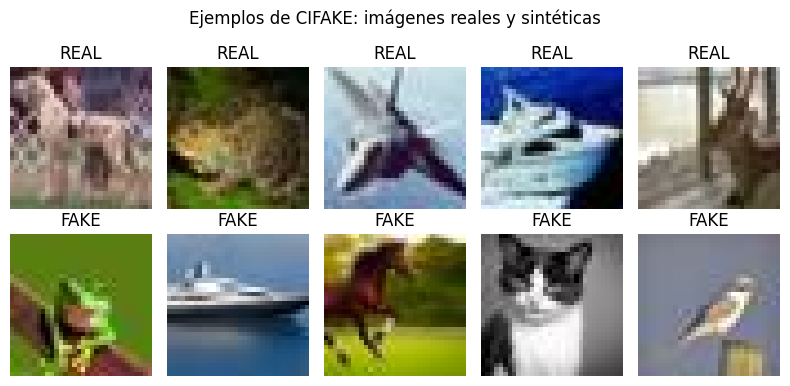

In [4]:
fig, axes = plt.subplots(2, 5, figsize=(8, 4))

for row, label in enumerate(["REAL", "FAKE"]):
    selected = random.Random(42 + row).sample(files_by_split["train"][label], 5)

    for col, file in enumerate(selected):
        # Leer y decodificar la imagen como RGB
        image = tf.io.decode_jpeg(tf.io.read_file(str(file)), channels=3)

        axes[row, col].imshow(image.numpy())
        axes[row, col].set_title(label)
        axes[row, col].axis("off")

plt.suptitle("Ejemplos de CIFAKE: imágenes reales y sintéticas")
plt.tight_layout()
plt.show()

Nótese que la baja resolución de las imágenes es coherente con sus dimensiones de 32 x 32 píxeles. La baja resolución presenta la ventaja de que las imágenes ocupan menos espacio en memoria y favorecerá una mayor velocidad de iteración en el proceso de diseño del modelo, ya que se necesitará un volúmen de cálculo menor. Sin embargo, la baja resolución también puede resultar en mayores dificultades a la hora de aplicar la técnica de *transfer learning* y *fine-tuning* si los modelos han sido preentrenados con imágenes con una mayor resolución. Esta problemática se estudiará en detalle en la sección correspondiente.

Ahora que las características del dataset son conocidas, se realiza un análisis sobre la presencia de imágenes duplicadas y la limpieza correspondiente de ser necesario.

## 2.2. Análisis de duplicados y limpieza del dataset

Se ha observado en el apartado de discusiones asociado al dataset utilizado en Kaggle que un usuario advierte sobre la presencia de imágenes duplicadas en el dataset, mencionando la presencia de 1336 duplicados. Por lo tanto, a continuación se procede a comprobar la presencia de imágenes duplicadas de primera mano con el fin de eliminarlas en caso de que efectivamente las haya y así mejorar la calidad del dataset de cara al posterior proceso de diseño, entrenamiento y evaluación de los modelos.

Para ello, se analiza la presencia de duplicados exactos, es decir, la presencia de archivos que contengan exactamente los mismos bytes. Este tipo de duplicados se pueden identificar de forma rápida mediante un hash, sin abrir ni decodificar las imágenes. El análisis se realiza sobre los duplicados que se encuentran en el mismo directorio (todas las imágenes duplicadas se encuentran en el mismo directorio, test o train) así como los que se encuentran en directorios distintos (una imagen se encuentra en train y su duplicado en test).

Imágenes analizadas: 120000
Grupos de duplicados exactos: 1336
Copias adicionales: 1336

Grupos duplicados por ubicación:
  Entre conjuntos: test, train: 378
  Solo test: 38
  Solo train: 920

Grupos presentes en varios conjuntos: 378
Grupos con etiquetas diferentes: 0
Archivos que no se pudieron leer: 0


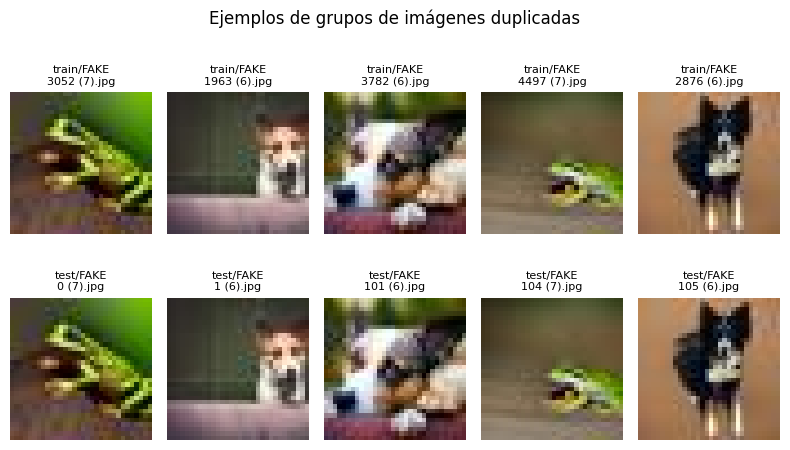

In [5]:
import hashlib
from collections import defaultdict, Counter
import tensorflow as tf
import matplotlib.pyplot as plt

# Asociar cada hash con los archivos que lo comparten
hash_to_files = defaultdict(list)
errors = []

for split, classes in files_by_split.items():
    for label, files in classes.items():
        for file in files:
            try:
                file_hash = hashlib.sha256(file.read_bytes()).hexdigest()
                hash_to_files[file_hash].append((split, label, file))
            except OSError as error:
                errors.append((file, str(error)))

# Conservar los grupos que contienen duplicados
duplicates = {file_hash: files for file_hash, files in hash_to_files.items() if len(files) > 1}

# Métricas globales
n_images = sum(len(files) for files in hash_to_files.values())
n_extra_copies = sum(len(files) - 1 for files in duplicates.values())

n_cross_split = 0
n_conflicting_labels = 0
groups_by_split = Counter()

for files in duplicates.values():
    splits = {split for split, label, file in files}
    labels = {label for split, label, file in files}

    if len(splits) == 1:
        location = f"Solo {next(iter(splits))}"
    else:
        location = "Entre conjuntos: " + ", ".join(sorted(splits))
        n_cross_split += 1

    groups_by_split[location] += 1

    if len(labels) > 1:
        n_conflicting_labels += 1

# Mostrar resumen
print("Imágenes analizadas:", n_images)
print("Grupos de duplicados exactos:", len(duplicates))
print("Copias adicionales:", n_extra_copies)

print("\nGrupos duplicados por ubicación:")
for location, count in sorted(groups_by_split.items()):
    print(f"  {location}: {count}")

print("\nGrupos presentes en varios conjuntos:", n_cross_split)
print("Grupos con etiquetas diferentes:", n_conflicting_labels)
print("Archivos que no se pudieron leer:", len(errors))

# Seleccionar los mismos grupos para imprimir y visualizar
example_groups = list(duplicates.items())[:5]

# Representar gráficamente los mismos grupos
if example_groups:
    fig, axes = plt.subplots(2, len(example_groups), figsize=(8, 5))

    for col, (file_hash, files) in enumerate(example_groups):

        # Ordenar los archivos para que la visualización sea reproducible
        files = sorted(files, key=lambda item: (item[0] != "train", item[0], item[1], item[2].name))

        # Mostrar dos archivos de cada grupo
        for row, (split, label, file) in enumerate(files[:2]):
            image = tf.io.decode_jpeg(tf.io.read_file(str(file)), channels=3)

            axes[row, col].imshow(image.numpy())
            axes[row, col].set_title(f"{split}/{label}\n{file.name}", fontsize=8)
            axes[row, col].axis("off")

    plt.suptitle("Ejemplos de grupos de imágenes duplicadas")
    plt.tight_layout()
    plt.show()

Los resultados confirman que **el dataset contiene 1336 duplicados exactos**. Dado que número de grupos y de copias adicionales es el mismo (1336), los duplicados se presentan en parejas, es decir, no hay ninguna imagen que esté repetida más de una vez y todos los grupos se corresponden con parejas de duplicados.

De las 1336, 378 son parejas en las que una imagen se encuentra en el directorio de test y la otra en train, 38 parejas de duplicados se encuentran íntegramente en la carpeta test y 920 parejas íntegramente en la carpeta train.

Por otro lado, no hay ninguna pareja de duplicados en la que una de las imágenes pertenezca a la carpeta FAKE y su duplicada a REAL: todas las parejas de duplicados son de la misma clase.

Finalmente, todas las imágenes del dataset han sido analizadas y no ha habido ningún caso en el que la lectura de la imagen haya sido imposible.

En vista de estos resultados, es necesario realizar la limpieza del dataset y eliminar las imágenes duplicadas. Para ello se siguen los siguientes criterios:
- Solo se conserva una copia de cada imagen idéntica.
- Si la imagen aparece tanto en test como en train, se conserva la copia de test y se elimina la de train.

La limpieza del dataset se realiza creando una nueva estructura con las rutas de las imágenes únicas, llamada clean_files_by_split. Nótese que no se borra ni modifica ninguno de los archivos originales de Kaggle.

In [6]:
# Crear una estructura nueva para almacenar las rutas limpias
clean_files_by_split = {split: {label: [] for label in classes} for split, classes in files_by_split.items()}

# Conservar una sola copia de cada imagen
for file_hash, group in hash_to_files.items():

    # Priorizar test cuando la imagen aparece en ambos conjuntos
    selected = min(group, key=lambda item: (item[0] != "test", item[0], item[1], str(item[2])))

    split, label, file = selected
    clean_files_by_split[split][label].append(file)

# Ordenar las rutas para garantizar reproducibilidad
for classes in clean_files_by_split.values():
    for files in classes.values():
        files.sort()

print("--------- RESUMEN DE LA LIMPIEZA ------------\n")

total_original = 0
total_clean = 0

for split, classes in files_by_split.items():
    for label, original_files in classes.items():

        n_original = len(original_files)
        n_clean = len(clean_files_by_split[split][label])
        n_removed = n_original - n_clean

        total_original += n_original
        total_clean += n_clean

        print(f"{split}/{label}: {n_original} originales, {n_clean} conservadas, {n_removed} excluidas")

print("\nTOTAL")
print("Imágenes originales:", total_original)
print("Imágenes conservadas:", total_clean)
print("Copias excluidas:", total_original - total_clean)

--------- RESUMEN DE LA LIMPIEZA ------------

test/FAKE: 10000 originales, 9962 conservadas, 38 excluidas
test/REAL: 10000 originales, 10000 conservadas, 0 excluidas
train/FAKE: 50000 originales, 48702 conservadas, 1298 excluidas
train/REAL: 50000 originales, 50000 conservadas, 0 excluidas

TOTAL
Imágenes originales: 120000
Imágenes conservadas: 118664
Copias excluidas: 1336


Finalmente se observa que se han excluido de la lista de rutas las 1336 imágenes duplicadas. Es interesante ver que todos los duplicados pertenecían a la clase FAKE y que se han excluido 38 imágenes del repertorio test y 1298 de train. Esto introduce un ligero desbalance en la cantidad de imágenes que pertenecen a ambas clases FAKE o REAL. Sin embargo, el número de imágenes excluidas se puede considerar despreciable respecto al número total de imágenes disponibles, por lo que este ligero desbalance se acepta sin tomar más medidas.

# 3. Preparación del conjunto de datos

Ahora que se ha comprendido el contenido del dataset y se ha realizado su limpieza, se procede a su tratamiento y preparación para usarlos en las fases de entrenamiento y evaluación de las CNNs. Esta fase de preparación del dataset se organiza en las siguientes tareas:

- División de las imágenes en subconjuntos de entrenamiento, validación y test.
- Codificación de las etiquetas, convirtiendo las clases REAL y FAKE a valores numéricos.
- Decodificación de las imágenes, transformando los ficheros JPG en tensores RGB.
- Preparación y creación de los conjuntos de datos de TensorFlow.

Nótese que la normalización de los datos se pospone para una fase posterior del proceso de forma deliberada. La razón es que en este proyecto se tratarán diversas arquitecturas de CNNs y cada una de ellas requiere un preprocesamiento diferente.

## 3.1. División en entrenamiento, validación y test y codificación de etiquetas

El dataset original ya se encuentra dividido en entrenamiento y test. Sin embargo, se decide crear un tercer conjunto de validación a partir del subconjunto de datos de entrenamiento para evaluar el rendimiento durante el entrenamiento y seleccionar los hiperparámetros del modelo.

Nótese que **se propone crear un único subconjunto de validación fijo, ya que posteriormente se seguirá un procedimiento de validación hold-out** y no una validación cruzada. La razón principal por la que se ha decidido seguir una validación hold-out en lugar de **la validación cruzada es el elevado coste computacional de esta última**. Aunque la validación cruzada ofrece una mayor robustez estadística de los resultados, una menor dependencia de la forma en la que se dividen los conjuntos de entrenamiento y validación y un mejor aprovechamiento de los datos, hay que considerar que en este proyecto se van a entrenar 3 CNNs diferentes (una desde cero y dos preentrenadas), y además se van a realizar diferentes experimentos sobre la elección de arquitectura, regularización, transfer learning y fine-tuning. Esto multiplica considerablemente el número de entrenamientos del modelo si se siguiese una estrategia de validación cruzada.

Por otro lado, el conjunto de datos de entrenamiento disponible contiene una cantidad muy elevada de imágenes (cerca de 100000). Esta muestra se considera suficientemente amplia para estimar el rendimiento del modelo con validación hold-out sin necesidad de usar validación cruzada.

Se propone crear el conjunto de validación a partir del conjunto de entrenamiento con una división del 80/20%, es decir, se toman el 20% de las imágenes del conjunto de entrenamiento para crear el de validación. La elección de esta proporción se debe a 3 motivos:

- Se dispondrá de aproximadamente 20000 imágenes de validación, una muestra bastante amplia para comparar arquitecturas y ajustar hiperparámetros.
- Se conservan alrededor de 80000 imágenes para entrenamiento, en principio también suficientes para entrenar una CNN desde cero y adaptar los modelos preentrenados.
- Esta división proporciona tamaños similares para los subconjuntos de validación y de test, lo que facilita comparar las métricas obtenidas.

Cabe destacar que la creación de los conjuntos de entrenamiento y validación se realiza manteniendo aproximadamente la proporción entre las clases REAL y FAKE.

Para terminar, las clases FAKE y REAL se codifican con las etiquetas numéricas 0 y 1 respectivamente.

In [ ]:
# Se define el porcentaje de imagenes para el conjunto de validación
VALIDATION_SPLIT = 0.20

# Se identifican las clases automáticamente
CLASS_NAMES = sorted(clean_files_by_split["train"].keys())

# Se codifican de etiquetas
class_to_label = {name: index for index, name in enumerate(CLASS_NAMES)}

print("Codificación de etiquetas:", class_to_label)

# Se preparan las listas de entrenamiento y validación
rng = random.Random(SEED)

train_records = []
val_records = []

for label in CLASS_NAMES:

    # Se obtienen y barajan las imágenes de cada clase
    files = clean_files_by_split["train"][label].copy()
    rng.shuffle(files)

    # Se dividen las imágenes de la clase en validación y entrenamiento de acuerdo al porcentaje especificado
    n_val = int(len(files) * VALIDATION_SPLIT)

    val_files = files[:n_val]
    train_files = files[n_val:]

    # Se añaden las rutas y etiquetas numéricas
    train_records.extend((str(file), class_to_label[label]) for file in train_files)

    val_records.extend((str(file), class_to_label[label]) for file in val_files)

# Se prepara el conjunto de test depurado,
# manteniendo su separación de entrenamiento y validación.
test_records = [(str(file), class_to_label[label]) for label in CLASS_NAMES for file in clean_files_by_split["test"][label]]

# Se comprueba la distribución de imágenes en cada conjunto
for name, records in [("Train", train_records), ("Validation", val_records), ("Test", test_records)]:
    counts = Counter(label for _, label in records)

    print(f"\n{name}: {len(records)} imágenes")

    for class_name, label_id in class_to_label.items():
        print(f"  {class_name}: {counts[label_id]}")

Codificación de etiquetas: {'FAKE': 0, 'REAL': 1}

Train: 78962 imágenes
  FAKE: 38962
  REAL: 40000

Validation: 19740 imágenes
  FAKE: 9740
  REAL: 10000

Test: 19962 imágenes
  FAKE: 9962
  REAL: 10000


Se observa que los conjuntos de entrenamiento, validación y test obtenidos cumplen los objetivos especificados anteriormente: distribución equilibrada entre las clases REAL y FAKE, repartición del 80/20% entre entrenamiento y validación así como una cantidad similar de imágenes entre los subconjuntos de validación y test.

## 3.2. Decodificación de las imágenes y preparación de los datasets

El siguiente paso es transformar los archivos JPG en tensores con formato RGB de forma que puedan ser usados por las CNNs.

Dado el tamaño del conjunto de datos, se evitará cargar simultáneamente todas las imágenes en memoria. En su lugar, los datasets de TensorFlow se construyen a partir de las rutas de los archivos y sus correspondientes etiquetas. La lectura y decodificación de las imágenes se realizará progresivamente durante la iteración sobre los datasets, permitiendo procesarlas bajo demanda.

Para ello, se definen funciones específicas para la carga y preparación de las imágenes y la construcción de los datasets. La agrupación de las imágenes en lotes (batches) se realizará posteriormente, durante la configuración del proceso de entrenamiento.

In [8]:
IMG_SIZE = (32, 32)

AUTOTUNE = tf.data.AUTOTUNE

# Función para cargar y preparar una imagen
def load_image(file_path, label):

    image = tf.io.read_file(file_path)
    image = tf.io.decode_jpeg(image, channels=3)

    # Comprobar las dimensiones esperadas
    image = tf.ensure_shape(image, (IMG_SIZE[0], IMG_SIZE[1], 3))

    # Convertir a float32 sin normalizar
    image = tf.cast(image, tf.float32)

    # Preparar la etiqueta para clasificación binaria
    label = tf.cast(label, tf.float32)
    label = tf.expand_dims(label, axis=-1)

    return image, label

In [9]:
def create_dataset(records, shuffle=False, seed = None):

    paths = [record[0] for record in records]
    labels = [record[1] for record in records]

    dataset = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    # Barajar las rutas antes de leer las imágenes
    if shuffle:

        if seed is None:
            raise ValueError("Debe proporcionarse una semilla para shuffle.")

        dataset = dataset.shuffle(
            buffer_size=len(records),
            seed=seed,
            reshuffle_each_iteration=True
        )

    # Leer y preparar imágenes
    dataset = dataset.map(
        load_image,
        num_parallel_calls=AUTOTUNE,
        deterministic=True
    )

    options = tf.data.Options()
    options.experimental_deterministic = True
    dataset = dataset.with_options(options)

    return dataset

In [10]:
def prepare_batched_dataset(dataset, batch_size, prefetch_buffer):
    dataset = dataset.batch(batch_size)
    dataset = dataset.prefetch(prefetch_buffer)

    return dataset

A continuación se crean los datasets de entrenamiento, validación y test y se muestran como ejemplo las características de una imagen de entrenamiento.

In [11]:
# Crear los tres datasets
train_ds = create_dataset(train_records)
val_ds = create_dataset(val_records)
test_ds = create_dataset(test_records)

# Obtener una muestra del conjunto de entrenamiento
image, label = next(iter(train_ds))

print("Forma de la imagen:", image.shape)
print("Forma de la etiqueta:", label.shape)
print("Tipo de datos:", image.dtype)

print("Valor mínimo de los píxeles:", tf.reduce_min(image).numpy())

print("Valor máximo de los píxeles:", tf.reduce_max(image).numpy())

print("Etiqueta:", label.numpy())

Forma de la imagen: (32, 32, 3)
Forma de la etiqueta: (1,)
Tipo de datos: <dtype: 'float32'>
Valor mínimo de los píxeles: 0.0
Valor máximo de los píxeles: 255.0
Etiqueta: [0.]


Se observa que la imagen tiene una forma de 32x32x3, correspondiente a los 32x32 píxeles y los 3 canales RGB. En este caso, la etiqueta de la imagen es 1, correspondiente a la clase REAL.

Finalmente, se muestra un ejemplo de uso de la función prepare_batched_dataset, que agrupa las imágenes en lotes del tamaño deseado.

In [12]:
# Definir el tamaño del batch para este experimento
BATCH_SIZE_EXP = 64

# Preparar el dataset de entrenamiento
train_ds_batched = prepare_batched_dataset(train_ds, batch_size=BATCH_SIZE_EXP, prefetch_buffer=AUTOTUNE)

# Obtener un batch de entrenamiento
images, labels = next(iter(train_ds_batched))

# Comprobar sus dimensiones
print("Forma del batch de imágenes:", images.shape)
print("Forma del batch de etiquetas:", labels.shape)
print("Tipo de datos:", images.dtype)

Forma del batch de imágenes: (64, 32, 32, 3)
Forma del batch de etiquetas: (64, 1)
Tipo de datos: <dtype: 'float32'>


Se puede ver que el dataset tiene una dimensión adicional con 64 elementos correspondiente a las 64 imágenes incluidas en el lote. Asimismo, las etiquetas también tienen una dimensión adicional con 64 elementos correspondiente al número de imágenes.

# 4. Diseño, entrenamiento y evaluación de una CNN desde cero

En esta sección se desarrolla la fase principal del proyecto, consistente en diseñar y entrenar una CNN desde cero, sin utilizar pesos procedentes de modelos preentrenados. El objetivo es desarrollar una arquitectura capaz de distinguir entre imágenes reales e imágenes generadas sintéticamente, utilizando para ello las características aprendidas directamente a partir del conjunto de imágenes de entrenamiento.

El desarrollo de esta estrategia seguirá un **enfoque experimental y progresivo**. En lugar de definir directamente una arquitectura definitiva, se partirá de una configuración inicial y se realizarán diferentes experimentos para estudiar cómo afectan las decisiones relativas a la arquitectura, los hiperparámetros y las técnicas de regularización al rendimiento y a la capacidad de generalización del modelo.

Para llevar a cabo este análisis, se utilizarán las particiones de entrenamiento, validación y test definidas durante la fase de preprocesamiento. El conjunto de entrenamiento se empleará para optimizar los pesos de la red, mientras que el conjunto de validación permitirá monitorizar el aprendizaje, comparar las distintas configuraciones y seleccionar los modelos más adecuados. El conjunto de test permanecerá reservado para la evaluación final, una vez completado el proceso de diseño y selección.

La estrategia experimental se organizará en varias etapas:

1. **Definición de la arquitectura y configuración de referencia.** Se implementará una CNN configurable mediante funciones reutilizables, estableciendo una arquitectura inicial y un conjunto de hiperparámetros comunes que servirán como referencia para los experimentos posteriores.

2. **Exploración de la arquitectura.** Se analizará el efecto del número de capas convolucionales y de capas densas mediante diferentes combinaciones. También se estudiará la influencia de la operación de reducción espacial, comparando *Global Average Pooling* y *Flatten*. Durante esta etapa se prestará especial atención al equilibrio entre rendimiento, complejidad del modelo y capacidad de generalización.

3. **Optimización de los hiperparámetros.** Una vez identificadas las arquitecturas más prometedoras, se estudiará el efecto de diferentes optimizadores, tasas de aprendizaje, tamaños de batch y funciones de activación. Se modificarán estos parámetros de forma progresiva, manteniendo constantes el resto de las condiciones siempre que sea posible, con el objetivo de identificar configuraciones que favorezcan el proceso de aprendizaje.

4. **Evaluación de técnicas de regularización y data augmentation.** Se estudiará la aplicación de técnicas como *Dropout*, regularización L2, *Batch Normalization* y aumento de datos. Su utilización estará motivada por el comportamiento observado durante el entrenamiento y, especialmente, por la posible aparición de sobreajuste. Se analizará si estas técnicas permiten mejorar la generalización sin comprometer excesivamente la capacidad de aprendizaje de la red.

5. **Selección y evaluación final del modelo.** A partir de los resultados obtenidos se seleccionará la configuración más adecuada y se realizará su evaluación sobre el conjunto de test, que no habrá intervenido en las decisiones anteriores.

A lo largo de las distintas etapas se monitorizará la evolución de las métricas de entrenamiento y validación, prestando especial atención a la accuracy, la pérdida, la precision, el recall y la puntuación F1. Asimismo, se representarán las curvas de aprendizaje para identificar posibles problemas de sobreajuste o subajuste y analizar el comportamiento de las diferentes arquitecturas.

## 4.1. Configuración del entorno experimental

Antes de comenzar con el diseño y entrenamiento de las diferentes arquitecturas, se establece un entorno experimental común que permita realizar las comparaciones de forma sistemática y reproducible. Para ello, se implementan una serie de funciones reutilizables destinadas a configurar los modelos, definir las métricas de evaluación, ejecutar los entrenamientos y almacenar los resultados obtenidos.

Con el objetivo de facilitar la comparación entre experimentos, se mantendrán constantes las condiciones generales de entrenamiento siempre que no sean objeto de estudio. Asimismo, se fijará una semilla aleatoria para favorecer la reproducibilidad de los experimentos y se establecerá una configuración inicial común de hiperparámetros.

El código se organizará mediante funciones parametrizables. De esta forma, será posible modificar elementos como el número de bloques convolucionales, las capas densas, las funciones de activación o el optimizador sin necesidad de reescribir el proceso de construcción y entrenamiento para cada modelo.

### 4.1.1. Configuración general y reproducibilidad

En primer lugar, se definen los parámetros generales que se utilizarán durante los experimentos, incluyendo la semilla aleatoria, el número máximo de épocas y el tamaño inicial de batch.

Se establece inicialmente un tamaño de batch de 64 imágenes y un máximo de 20 épocas por entrenamiento. Estos valores servirán como configuración de referencia durante la exploración de la arquitectura y podrán modificarse posteriormente en los experimentos dedicados al análisis de hiperparámetros.

Se utilizará una semilla aleatoria fija para favorecer que las ejecuciones sean comparables, reduciendo la variabilidad asociada a la inicialización de los pesos y a otros procesos aleatorios.

In [13]:
# Parámetros generales
EPOCHS = 20
DEFAULT_BATCH_SIZE = 64
AUTOTUNE = tf.data.AUTOTUNE

### 4.1.2. Definición de las métricas de evaluación

Para monitorizar el aprendizaje y comparar las diferentes configuraciones se utilizarán varias métricas de clasificación: accuracy, precision, recall y F1-score.

Dado que se trata de un problema de clasificación binaria, se utilizará una única neurona de salida con función de activación sigmoide. La salida del modelo representará la probabilidad estimada de que una imagen pertenezca a la clase REAL. Se establecerá un umbral de 0.5 para transformar las probabilidades en predicciones de clase.

Además de las métricas anteriores, se calculará el F1-score macro (Macro F1), que corresponde a la media aritmética de los F1-score obtenidos para cada una de las dos clases. Esta métrica permitirá evaluar el equilibrio del rendimiento entre imágenes reales y generadas artificialmente.

In [14]:
@tf.keras.utils.register_keras_serializable()
class BinaryF1Score(tf.keras.metrics.Metric):

    def __init__(self, threshold=0.5, name="f1_real", **kwargs):
        super().__init__(name=name, **kwargs)

        self.threshold = threshold
        self.tp = self.add_weight(name="true_positives", initializer="zeros")
        self.fp = self.add_weight(name="false_positives", initializer="zeros")
        self.fn = self.add_weight(name="false_negatives", initializer="zeros")

    def update_state(self, y_true, y_pred, sample_weight=None):

        y_true = tf.cast(tf.reshape(y_true, [-1]), tf.float32)

        y_pred = tf.cast(tf.reshape(y_pred, [-1]) >= self.threshold, tf.float32)

        tp = tf.reduce_sum(y_true * y_pred)
        fp = tf.reduce_sum((1.0 - y_true) * y_pred)
        fn = tf.reduce_sum(y_true * (1.0 - y_pred))

        self.tp.assign_add(tp)
        self.fp.assign_add(fp)
        self.fn.assign_add(fn)

    def result(self):

        precision = self.tp / (self.tp + self.fp + tf.keras.backend.epsilon())
        recall = self.tp / (self.tp + self.fn + tf.keras.backend.epsilon())

        return (2.0 * precision * recall / (precision + recall + tf.keras.backend.epsilon()))

    def reset_state(self):

        self.tp.assign(0.0)
        self.fp.assign(0.0)
        self.fn.assign(0.0)

    def get_config(self):

        config = super().get_config()
        config.update({"threshold": self.threshold})

        return config

### 4.1.3. Construcción parametrizable de la arquitectura CNN

Se implementa una función general para construir las CNNs mediante la especificación de sus principales características. Esta función permite modificar el número de bloques convolucionales, el número de capas densas, la operación de reducción espacial, la función de activación y los parámetros del optimizador.

Cada bloque convolucional estará formado inicialmente por una capa Conv2D, con filtros de tamaño 3x3 y activación ReLU, seguida de una operación MaxPooling2D para reducir las dimensiones espaciales de los mapas de características. El número de filtros aumentará progresivamente con la profundidad de la red, siguiendo la secuencia 32, 64, 128 y 256.

Tras los bloques convolucionales se incorporará una etapa de clasificación formada por una operación de reducción espacial y una o varias capas densas. En esta primera configuración se utilizarán capas densas de 128 y 64 neuronas, según el experimento. La capa de salida estará compuesta por una única neurona con activación sigmoide, adecuada para la clasificación binaria.

Las imágenes se normalizarán mediante una capa Rescaling, que transforma los valores originales de los píxeles, comprendidos entre 0 y 255, al intervalo [0, 1]. Esta operación se incorpora directamente a la arquitectura, de modo que el preprocesamiento quede integrado en el propio modelo.

La función también contempla parámetros opcionales para incorporar posteriormente técnicas de regularización, como Dropout, regularización L2 y Batch Normalization. Inicialmente estas técnicas permanecerán desactivadas, con el objetivo de estudiar primero el comportamiento de las arquitecturas sin mecanismos adicionales de regularización.

Una vez construida la red, se compilará utilizando Binary Crossentropy como función de pérdida, dado que el problema planteado consiste en una clasificación binaria, y Adam como optimizador inicial, con una tasa de aprendizaje de 0.001. Las métricas definidas anteriormente se incorporarán al proceso de compilación para monitorizar su evolución durante el entrenamiento y la validación.

In [15]:
def apply_activation(x, activation):

    if activation == "leaky_relu":

        return tf.keras.layers.LeakyReLU(negative_slope=0.1)(x)

    elif activation in ["relu", "elu", "tanh", "sigmoid"]:

        return tf.keras.layers.Activation(activation)(x)

    else:

        raise ValueError(f"Activación no soportada: {activation}")

def get_optimizer(optimizer_name, learning_rate, momentum=0.9):

    if optimizer_name == "adam":
        return tf.keras.optimizers.Adam(learning_rate=learning_rate)

    elif optimizer_name == "rmsprop":
        return tf.keras.optimizers.RMSprop(learning_rate=learning_rate)

    elif optimizer_name == "sgd":
        return tf.keras.optimizers.SGD(learning_rate=learning_rate, momentum=momentum)

    else:
        raise ValueError(f"Optimizador no soportado: {optimizer_name}")

def create_augmentation_layers(data_augmentation):

    if data_augmentation is None:
        return None

    elif data_augmentation == "horizontal_flip":

        layers = [
            tf.keras.layers.RandomFlip(
                mode="horizontal",
                seed=SEED
            )
        ]

    elif data_augmentation == "mild_geometric":

        layers = [
            tf.keras.layers.RandomFlip(
                mode="horizontal",
                seed=SEED
            ),

            tf.keras.layers.RandomRotation(
                factor=0.025,
                fill_mode="reflect",
                interpolation="bilinear",
                seed=SEED + 1
            ),

            tf.keras.layers.RandomTranslation(
                height_factor=0.05,
                width_factor=0.05,
                fill_mode="reflect",
                interpolation="bilinear",
                seed=SEED + 2
            ),

            tf.keras.layers.RandomZoom(
                height_factor=0.05,
                width_factor=None,
                fill_mode="reflect",
                interpolation="bilinear",
                seed=SEED + 3
            )
        ]

    else:
        raise ValueError(
            f"Estrategia de Data Augmentation no soportada: "
            f"{data_augmentation}"
        )

    return tf.keras.Sequential(
        layers,
        name="data_augmentation"
    )

def build_cnn(num_conv_blocks=3,
    num_dense_layers=1,
    spatial_reduction="gap",
    activation="relu",
    optimizer_name="adam",
    learning_rate=0.001,
    momentum=0.9,
    dropout_rate=0.0,
    l2_strength=0.0,
    batch_normalization=False,
    data_augmentation=None
):

    inputs = tf.keras.layers.Input(shape=(IMG_SIZE[0], IMG_SIZE[1], 3))

    # Data Augmentation, si está activado
    x = inputs

    if data_augmentation is not None:

        augmentation_layers = create_augmentation_layers(data_augmentation)

        x = augmentation_layers(x)

    # Normalización de las imágenes: [0,255] -> [0,1]
    x = tf.keras.layers.Rescaling(1.0 / 255)(x)

    # Configuración de los bloques convolucionales
    filters = [32, 64, 128, 256]

    regularizer = (tf.keras.regularizers.l2(l2_strength) if l2_strength > 0 else None)

    # Bloques convolucionales
    for i in range(num_conv_blocks):

        x = tf.keras.layers.Conv2D(
            filters=filters[i],
            kernel_size=(3, 3),
            padding="same",
            use_bias=not batch_normalization,
            kernel_regularizer=regularizer,
            name=f"conv_{i+1}"
        )(x)

        if batch_normalization:
            x = tf.keras.layers.BatchNormalization()(x)

        x = apply_activation(x, activation)

        x = tf.keras.layers.MaxPooling2D(pool_size=(2, 2), name=f"maxpool_{i+1}")(x)

    # Reducción espacial
    if spatial_reduction == "gap":
        x = tf.keras.layers.GlobalAveragePooling2D()(x)

    elif spatial_reduction == "flatten":
        x = tf.keras.layers.Flatten()(x)

    else:
        raise ValueError("Usar 'gap' o 'flatten'.")

    # Capas densas
    dense_units = [128, 64]

    for i in range(num_dense_layers):

        x = tf.keras.layers.Dense(dense_units[i], use_bias=not batch_normalization, kernel_regularizer=regularizer)(x)

        if batch_normalization:
            x = tf.keras.layers.BatchNormalization()(x)

        x = apply_activation(x, activation)

        if dropout_rate > 0:
            x = tf.keras.layers.Dropout(dropout_rate)(x)

    # Capa de salida para clasificación binaria
    outputs = tf.keras.layers.Dense(1, activation="sigmoid", name="output")(x)

    model = tf.keras.Model(inputs=inputs, outputs=outputs)

    # Compilación
    optimizer = get_optimizer(optimizer_name, learning_rate, momentum)

    model.compile(optimizer=optimizer, loss="binary_crossentropy",
        metrics=[
            tf.keras.metrics.BinaryAccuracy(name="accuracy"),
            tf.keras.metrics.Precision(name="precision"),
            tf.keras.metrics.Recall(name="recall"),
            BinaryF1Score(name="f1_real")
        ]
    )

    return model

### 4.1.4. Configuración del entrenamiento y monitorización

Para evitar duplicar código y garantizar que todos los experimentos sigan el mismo procedimiento, se implementa una función general encargada de ejecutar el entrenamiento y recopilar sus resultados.

Los conjuntos de datos se agruparán en batches utilizando el tamaño especificado para cada experimento. Se empleará también la operación prefetch de TensorFlow para preparar los siguientes lotes mientras se procesa el lote actual, favoreciendo un uso más eficiente de los recursos disponibles.

Durante la primera fase experimental se utilizará un número fijo de 20 épocas para todas las arquitecturas. De esta manera, se mantiene un proceso de entrenamiento común que permite comparar la evolución de los diferentes modelos a lo largo del mismo número de épocas.

Durante el entrenamiento se utiliza una función para conservar en memoria los pesos correspondientes a la época que proporciona el menor valor de pérdida sobre el conjunto de validación (val_loss). Al finalizar el entrenamiento, se recuperan automáticamente estos pesos, de manera que las métricas finales se calculan utilizando el mejor modelo obtenido durante el proceso.

Al finalizar cada experimento se recopilarán las métricas obtenidas, el número de parámetros entrenables, el tiempo de entrenamiento y la época en la que se alcanzó el mínimo val_loss. También se conservará el historial completo de las métricas de entrenamiento y validación, que se utilizará posteriormente para analizar las curvas de aprendizaje y detectar posibles problemas de sobreajuste o subajuste.

De este modo, todas las arquitecturas se entrenarán bajo un procedimiento común y sus resultados podrán compararse de forma consistente.

In [16]:
# Diccionarios para almacenar los resultados de los experimentos
experiment_metrics = {}
experiment_histories = {}
experiment_configs = {}
experiment_best_weights = {}
experiment_epoch_offsets = {}


class BestWeightsInMemory(tf.keras.callbacks.Callback):

    def __init__(self):
        super().__init__()

        self.best_val_loss = np.inf
        self.best_epoch = None
        self.best_weights = None

    def on_epoch_end(self, epoch, logs=None):

        current_val_loss = logs.get("val_loss")

        if (
            current_val_loss is not None
            and current_val_loss < self.best_val_loss
        ):

            self.best_val_loss = float(current_val_loss)

            # Época global, incluyendo las continuaciones
            self.best_epoch = epoch + 1

            self.best_weights = [
                np.array(weight, copy=True)
                for weight in self.model.get_weights()
            ]

    def on_train_end(self, logs=None):

        if self.best_weights is None:
            raise RuntimeError(
                "No se ha encontrado ningún checkpoint válido."
            )

        self.model.set_weights(self.best_weights)

def run_experiment(
    experiment_name,
    model_config,
    batch_size=DEFAULT_BATCH_SIZE,
    epochs=EPOCHS,
    initial_weights=None,
    initial_epoch=0
):

    print("\n" + "=" * 70)
    print("EXPERIMENTO:", experiment_name)
    print("CONFIGURACIÓN:", model_config)
    print("BATCH SIZE:", batch_size)
    print("=" * 70)

    # --------------------------------------------------
    # 1. Reiniciar sesión y semillas
    # --------------------------------------------------

    tf.keras.backend.clear_session()

    # Reiniciar Python, NumPy y TensorFlow
    tf.keras.utils.set_random_seed(SEED)

    # --------------------------------------------------
    # 2. Preparación de los datasets
    # --------------------------------------------------

    # Barajado reproducible de las mismas imágenes de entrenamiento
    train_shuffled = create_dataset(
        train_records,
        shuffle=True,
        seed=SEED
    )

    train_batched = prepare_batched_dataset(
        train_shuffled,
        batch_size,
        AUTOTUNE
    )

    val_batched = prepare_batched_dataset(
        val_ds,
        batch_size,
        AUTOTUNE
    )

    # --------------------------------------------------
    # 3. Construcción del modelo
    # --------------------------------------------------

    model = build_cnn(**model_config)

    initial_validation_loss = None

    # Recuperar pesos previos si se continúa un entrenamiento
    if initial_weights is not None:

        initial_weights = [
            np.array(weight, copy=True)
            for weight in initial_weights
        ]

        model.set_weights(initial_weights)

        initial_evaluation = model.evaluate(
            val_batched,
            return_dict=True,
            verbose=0
        )

        initial_validation_loss = float(
            initial_evaluation["loss"]
        )

    # --------------------------------------------------
    # 4. Callback de mejores pesos en memoria
    # --------------------------------------------------

    best_weights_callback = BestWeightsInMemory()

    # --------------------------------------------------
    # 5. Entrenamiento
    # --------------------------------------------------

    start_time = time.perf_counter()

    history = model.fit(
        train_batched,
        validation_data=val_batched,
        initial_epoch=initial_epoch,
        epochs=epochs,
        callbacks=[best_weights_callback],
        verbose=2
    )

    training_time = time.perf_counter() - start_time

    # Los mejores pesos de la fase actual ya están cargados
    best_epoch = best_weights_callback.best_epoch

    # --------------------------------------------------
    # 6. Comparar con los pesos iniciales, si existen
    # --------------------------------------------------

    if initial_weights is not None:

        if initial_validation_loss <= best_weights_callback.best_val_loss:

            # La continuación no ha mejorado el modelo inicial
            model.set_weights(initial_weights)

            best_epoch = initial_epoch

            print(
                "\nLa continuación no mejora el checkpoint inicial."
            )

        else:

            print(
                "\nLa continuación mejora el checkpoint inicial."
            )

    # --------------------------------------------------
    # 7. Evaluación del mejor modelo
    # --------------------------------------------------

    evaluation = model.evaluate(
        val_batched,
        return_dict=True,
        verbose=0
    )

    probabilities = model.predict(
        val_batched,
        verbose=0
    ).reshape(-1)

    # Las etiquetas corresponden al mismo orden de val_records
    y_true = np.array(
        [label for _, label in val_records],
        dtype=np.int32
    )

    y_pred = (probabilities >= 0.5).astype(np.int32)

    macro_f1 = f1_score(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    )

    # --------------------------------------------------
    # 8. Resultados
    # --------------------------------------------------

    result = {
        "experiment": experiment_name,
        "val_loss": float(evaluation["loss"]),
        "val_accuracy": float(evaluation["accuracy"]),
        "val_precision": float(evaluation["precision"]),
        "val_recall": float(evaluation["recall"]),
        "val_f1_real": float(evaluation["f1_real"]),
        "val_macro_f1": float(macro_f1),
        "best_epoch": int(best_epoch),
        "parameters": int(model.count_params()),
        "training_seconds": float(training_time),
        "batch_size": int(batch_size)
    }

    # --------------------------------------------------
    # 9. Almacenamiento en memoria
    # --------------------------------------------------

    experiment_metrics[experiment_name] = result

    experiment_histories[experiment_name] = {
        key: [float(value) for value in values]
        for key, values in history.history.items()
    }

    experiment_configs[experiment_name] = model_config.copy()

    experiment_best_weights[experiment_name] = [
        np.array(weight, copy=True)
        for weight in model.get_weights()
    ]

    experiment_epoch_offsets[experiment_name] = initial_epoch

    # --------------------------------------------------
    # 10. Mostrar resultados y liberar memoria
    # --------------------------------------------------

    print("\nResultados de validación:")
    print(pd.Series(result))

    del model
    gc.collect()

    return result

In [17]:
def plot_training_history(experiment_names):

    # Admitir tanto un nombre como una lista de experimentos
    if isinstance(experiment_names, str):
        experiment_names = [experiment_names]

    n = len(experiment_names)

    if n == 0:
        raise ValueError("No se han proporcionado experimentos.")

    # Crear matriz de subplots: 2 filas x N columnas
    fig, axes = plt.subplots(
        2,
        n,
        figsize=(3.8 * n, 6),
        sharex=True,
        sharey="row",
        squeeze=False
    )

    for col, experiment_name in enumerate(experiment_names):

        history = experiment_histories[experiment_name]

        best_epoch = experiment_metrics[
            experiment_name
        ]["best_epoch"]

        epoch_offset = experiment_epoch_offsets.get(experiment_name, 0)

        epochs = range(epoch_offset + 1, epoch_offset + len(history["loss"]) + 1)

        # --------------------------------------------------
        # Primera fila: Accuracy
        # --------------------------------------------------

        ax_accuracy = axes[0, col]

        ax_accuracy.plot(
            epochs,
            history["accuracy"],
            label="Training accuracy"
        )

        ax_accuracy.plot(
            epochs,
            history["val_accuracy"],
            label="Validation accuracy"
        )

        ax_accuracy.axvline(
            best_epoch,
            color="gray",
            linestyle="--",
            label="Best epoch"
        )

        ax_accuracy.set_title(experiment_name, fontsize=10)
        ax_accuracy.grid(alpha=0.3)

        # --------------------------------------------------
        # Segunda fila: Loss
        # --------------------------------------------------

        ax_loss = axes[1, col]

        ax_loss.plot(
            epochs,
            history["loss"],
            label="Training loss"
        )

        ax_loss.plot(
            epochs,
            history["val_loss"],
            label="Validation loss"
        )

        ax_loss.axvline(
            best_epoch,
            color="gray",
            linestyle="--",
            label="Best epoch"
        )

        ax_loss.set_xlabel("Epoch")
        ax_loss.grid(alpha=0.3)

    # Etiquetas de los ejes Y
    axes[0, 0].set_ylabel("Accuracy")
    axes[1, 0].set_ylabel("Loss")

    # Leyendas globales para evitar repetirlas en cada subplot
    handles, labels = axes[0, 0].get_legend_handles_labels()

    fig.legend(
        handles,
        labels,
        loc="upper center",
        bbox_to_anchor=(0.5, 1.00),
        ncol=3
    )

    fig.suptitle(
        "Training history comparison",
        fontsize=14,
        y=1.06
    )

    plt.tight_layout(rect=[0, 0, 1, 0.92])

    plt.show()

    # return fig, axes


def plot_validation_comparison(experiment_names, metric):

    plt.figure(figsize=(10, 5))

    for name in experiment_names:

        values = experiment_histories[name][metric]
        epoch_offset = experiment_epoch_offsets.get(name, 0)

        epochs = range(epoch_offset + 1, epoch_offset + len(values) + 1)

        plt.plot(
            epochs,
            values,
            label=name
        )

    plt.xlabel("Epoch")
    plt.ylabel(metric)
    plt.title(f"Comparison of {metric}")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()


def get_results_table(experiment_names):

    results = [
        experiment_metrics[name]
        for name in experiment_names
    ]

    df = pd.DataFrame(results)

    # Criterio de ordenación:
    # 1. Menor validation loss
    # 2. Mayor Macro F1
    # 3. Menor número de parámetros
    df = df.sort_values(
        by=["val_loss", "val_macro_f1", "parameters"],
        ascending=[True, False, True]
    ).reset_index(drop=True)

    return df

## 4.2. Exploración de la arquitectura de la CNN

El primer objetivo de la experimentación consiste en estudiar cómo influye la arquitectura de la red neuronal en su capacidad para resolver el problema de clasificación planteado. Para ello, se analizará el efecto del número de bloques convolucionales y de capas densas, manteniendo constantes el resto de las condiciones de entrenamiento.

La etapa convolucional constituye el extractor de características de la red, permitiendo identificar progresivamente patrones presentes en las imágenes. Por su parte, las capas densas se encargan de procesar las características extraídas y generar la clasificación final. Por tanto, modificar la profundidad de ambas partes permite estudiar cómo afecta la capacidad representacional de la arquitectura al rendimiento del modelo.

Con este propósito, se diseñan diferentes configuraciones combinando dos, tres y cuatro bloques convolucionales con una o dos capas densas. En todos los casos se mantienen las mismas características para los bloques convolucionales: filtros de tamaño 3x3, función de activación ReLU y un número creciente de filtros a medida que aumenta la profundidad de la red (32, 64, 128 y 256). Cada bloque incorpora una operación MaxPooling2D para reducir progresivamente las dimensiones espaciales de los mapas de características.

Tras la parte convolucional se utiliza inicialmente GlobalAveragePooling2D como operación de reducción espacial. Esta capa calcula la media espacial de cada mapa de características, generando un vector compacto que se utiliza como entrada del clasificador denso. Su elección permite limitar el número de parámetros de las capas finales y facilita la comparación de las diferentes arquitecturas.

La parte densa estará formada por una capa de 128 neuronas o por dos capas de 128 y 64 neuronas, respectivamente. Finalmente, todos los modelos incorporan una única neurona de salida con activación sigmoide, adecuada para la clasificación binaria entre imágenes reales y generadas artificialmente.

Para aislar el efecto de las modificaciones arquitectónicas, se mantienen constantes los principales hiperparámetros: optimizador Adam, tasa de aprendizaje de 0.001, tamaño de batch de 64 imágenes y función de pérdida *Binary Crossentropy*. Cada modelo se entrena durante un máximo de 20 épocas, sin incorporar inicialmente técnicas adicionales de regularización ni estrategias de *data augmentation*.

La comparación se realizará utilizando las métricas obtenidas sobre el conjunto de validación y el análisis de las curvas de aprendizaje. De esta manera, no solo se estudiará el rendimiento alcanzado por cada arquitectura, sino también su comportamiento durante el entrenamiento y su capacidad de generalización.

### 4.2.1 Diseño de los experimentos

Para estudiar el efecto de la profundidad de la red, se plantean seis configuraciones diferentes:

| Experimento | Nombre | Capas convolucionales | Capas densas |
|---|---:|---:|---:|
| CNN-1 | arch_conv2_dense1 | 2 | 1 |
| CNN-2 | arch_conv2_dense2 | 2 | 2 |
| CNN-3 | arch_conv3_dense1 | 3 | 1 |
| CNN-4 | arch_conv3_dense2 | 3 | 2 |
| CNN-5 | arch_conv4_dense1 | 4 | 1 |
| CNN-6 | arch_conv4_dense2 | 4 | 2 |

La secuencia de filtros de cada arquitectura se adapta al número de capas convolucionales: la primera capa convolucional usa 32 filtros, la segunda 64, la tercera 128 y la cuarta 256.

Para facilitar la comparación y la interpretación de los resultados, se mantienen constantes las siguientes condiciones:

- Tamaño del kernel: 3x3
- Padding: Same
- Función de activación convolucional: ReLU
- Función de activación densa: ReLU
- Pooling convolucional: MaxPooling2D (2x2)
- Reducción espacial: GlobalAveragePooling2D
- Optimizador: Adam
- Learning rate: 0.001
- Batch size: 64
- Épocas: 20
- Función de pérdida: Binary Cross-entropy
- Regularización: Ninguna

Todas las arquitecturas utilizarán los mismos conjuntos de imágenes de entrenamiento y validación. Además, se emplea una semilla aleatoria fija para que los resultados sean reproducibles.
Se ha decidido no aplicar EarlyStopping de modo que todos los modelos completen las 20 épocas previstas para entrenamiento y se pueda comparar su evolución a igualdad de condiciones.

La selección de los modelos más prometedores se realizará atendiendo principalmente a la pérdida y las métricas de clasificación obtenidas sobre validación, considerando también la complejidad de los modelos y las posibles diferencias entre las curvas de entrenamiento y validación.

In [18]:
architecture_experiments = []

for num_conv_blocks in [2, 3, 4]:

    for num_dense_layers in [1, 2]:

        experiment_name = (
            f"arch_conv{num_conv_blocks}_dense{num_dense_layers}"
        )

        config = {
            "num_conv_blocks": num_conv_blocks,
            "num_dense_layers": num_dense_layers,
            "spatial_reduction": "gap",
            "activation": "relu",
            "optimizer_name": "adam",
            "learning_rate": 0.001
        }

        run_experiment(
            experiment_name=experiment_name,
            model_config=config,
            batch_size=64,
            epochs=20
        )

        architecture_experiments.append(experiment_name)


EXPERIMENTO: arch_conv2_dense1
CONFIGURACIÓN: {'num_conv_blocks': 2, 'num_dense_layers': 1, 'spatial_reduction': 'gap', 'activation': 'relu', 'optimizer_name': 'adam', 'learning_rate': 0.001}
BATCH SIZE: 64

Epoch 1/20


c:\Users\angel\AppData\Local\Programs\Python\Python314\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


1234/1234 - 30s - 24ms/step - accuracy: 0.7973 - f1_real: 0.8064 - loss: 0.4301 - precision: 0.7812 - recall: 0.8332 - val_accuracy: 0.8306 - val_f1_real: 0.8502 - val_loss: 0.3792 - val_precision: 0.7703 - val_recall: 0.9486
Epoch 2/20
1234/1234 - 25s - 20ms/step - accuracy: 0.8732 - f1_real: 0.8746 - loss: 0.3041 - precision: 0.8765 - recall: 0.8728 - val_accuracy: 0.8850 - val_f1_real: 0.8903 - val_loss: 0.2720 - val_precision: 0.8612 - val_recall: 0.9215
Epoch 3/20
1234/1234 - 32s - 26ms/step - accuracy: 0.8935 - f1_real: 0.8945 - loss: 0.2599 - precision: 0.8977 - recall: 0.8913 - val_accuracy: 0.9057 - val_f1_real: 0.9045 - val_loss: 0.2305 - val_precision: 0.9288 - val_recall: 0.8815
Epoch 4/20
1234/1234 - 26s - 21ms/step - accuracy: 0.9040 - f1_real: 0.9050 - loss: 0.2356 - precision: 0.9070 - recall: 0.9030 - val_accuracy: 0.8946 - val_f1_real: 0.9019 - val_loss: 0.2520 - val_precision: 0.8534 - val_recall: 0.9563
Epoch 5/20
1234/1234 - 25s - 20ms/step - accuracy: 0.9125 - f1_

c:\Users\angel\AppData\Local\Programs\Python\Python314\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


1234/1234 - 29s - 24ms/step - accuracy: 0.8042 - f1_real: 0.8115 - loss: 0.4169 - precision: 0.7920 - recall: 0.8319 - val_accuracy: 0.8319 - val_f1_real: 0.8534 - val_loss: 0.3735 - val_precision: 0.7645 - val_recall: 0.9656
Epoch 2/20
1234/1234 - 28s - 22ms/step - accuracy: 0.8908 - f1_real: 0.8922 - loss: 0.2650 - precision: 0.8923 - recall: 0.8921 - val_accuracy: 0.9035 - val_f1_real: 0.9067 - val_loss: 0.2301 - val_precision: 0.8886 - val_recall: 0.9255
Epoch 3/20
1234/1234 - 28s - 22ms/step - accuracy: 0.9080 - f1_real: 0.9091 - loss: 0.2254 - precision: 0.9093 - recall: 0.9089 - val_accuracy: 0.9193 - val_f1_real: 0.9177 - val_loss: 0.2024 - val_precision: 0.9489 - val_recall: 0.8885
Epoch 4/20
1234/1234 - 29s - 23ms/step - accuracy: 0.9190 - f1_real: 0.9199 - loss: 0.2035 - precision: 0.9211 - recall: 0.9188 - val_accuracy: 0.9273 - val_f1_real: 0.9289 - val_loss: 0.1801 - val_precision: 0.9199 - val_recall: 0.9381
Epoch 5/20
1234/1234 - 30s - 25ms/step - accuracy: 0.9251 - f1_

c:\Users\angel\AppData\Local\Programs\Python\Python314\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


... (3 outputs left out)

c:\Users\angel\AppData\Local\Programs\Python\Python314\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


1234/1234 - 52s - 42ms/step - accuracy: 0.8735 - f1_real: 0.8761 - loss: 0.2942 - precision: 0.8691 - recall: 0.8833 - val_accuracy: 0.9167 - val_f1_real: 0.9165 - val_loss: 0.2085 - val_precision: 0.9312 - val_recall: 0.9022
Epoch 2/20
1234/1234 - 49s - 39ms/step - accuracy: 0.9230 - f1_real: 0.9240 - loss: 0.1943 - precision: 0.9243 - recall: 0.9236 - val_accuracy: 0.9268 - val_f1_real: 0.9297 - val_loss: 0.1855 - val_precision: 0.9056 - val_recall: 0.9550
Epoch 3/20
1234/1234 - 50s - 40ms/step - accuracy: 0.9351 - f1_real: 0.9359 - loss: 0.1658 - precision: 0.9362 - recall: 0.9357 - val_accuracy: 0.9287 - val_f1_real: 0.9270 - val_loss: 0.1795 - val_precision: 0.9634 - val_recall: 0.8932
Epoch 4/20
1234/1234 - 50s - 40ms/step - accuracy: 0.9422 - f1_real: 0.9430 - loss: 0.1476 - precision: 0.9431 - recall: 0.9428 - val_accuracy: 0.9427 - val_f1_real: 0.9430 - val_loss: 0.1499 - val_precision: 0.9491 - val_recall: 0.9371
Epoch 5/20
1234/1234 - 50s - 40ms/step - accuracy: 0.9505 - f1_

c:\Users\angel\AppData\Local\Programs\Python\Python314\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


1234/1234 - 54s - 43ms/step - accuracy: 0.8686 - f1_real: 0.8714 - loss: 0.3008 - precision: 0.8638 - recall: 0.8792 - val_accuracy: 0.9197 - val_f1_real: 0.9190 - val_loss: 0.2075 - val_precision: 0.9393 - val_recall: 0.8996
Epoch 2/20
1234/1234 - 56s - 45ms/step - accuracy: 0.9245 - f1_real: 0.9254 - loss: 0.1919 - precision: 0.9260 - recall: 0.9248 - val_accuracy: 0.9271 - val_f1_real: 0.9284 - val_loss: 0.1834 - val_precision: 0.9238 - val_recall: 0.9329
Epoch 3/20
1234/1234 - 60s - 49ms/step - accuracy: 0.9355 - f1_real: 0.9363 - loss: 0.1658 - precision: 0.9360 - recall: 0.9366 - val_accuracy: 0.9193 - val_f1_real: 0.9161 - val_loss: 0.2041 - val_precision: 0.9672 - val_recall: 0.8702
Epoch 4/20
1234/1234 - 59s - 48ms/step - accuracy: 0.9429 - f1_real: 0.9437 - loss: 0.1469 - precision: 0.9430 - recall: 0.9445 - val_accuracy: 0.9382 - val_f1_real: 0.9381 - val_loss: 0.1557 - val_precision: 0.9516 - val_recall: 0.9251
Epoch 5/20
1234/1234 - 58s - 47ms/step - accuracy: 0.9501 - f1_

### 4.2.2. Resultados y análisis de los experimentos

En primer lugar se representa la evolución de la accuracy y la pérdida durante las 20 épocas de entrenamiento para cada arquitectura. En cada caso se muestran conjuntamente las curvas de entrenamiento y validación, indicando mediante una línea vertical discontinua la época en la que se alcanza el menor valor de pérdida en validación. Esta representación permite observar diferencias en la velocidad de convergencia y en la capacidad de generalización de las arquitecturas.

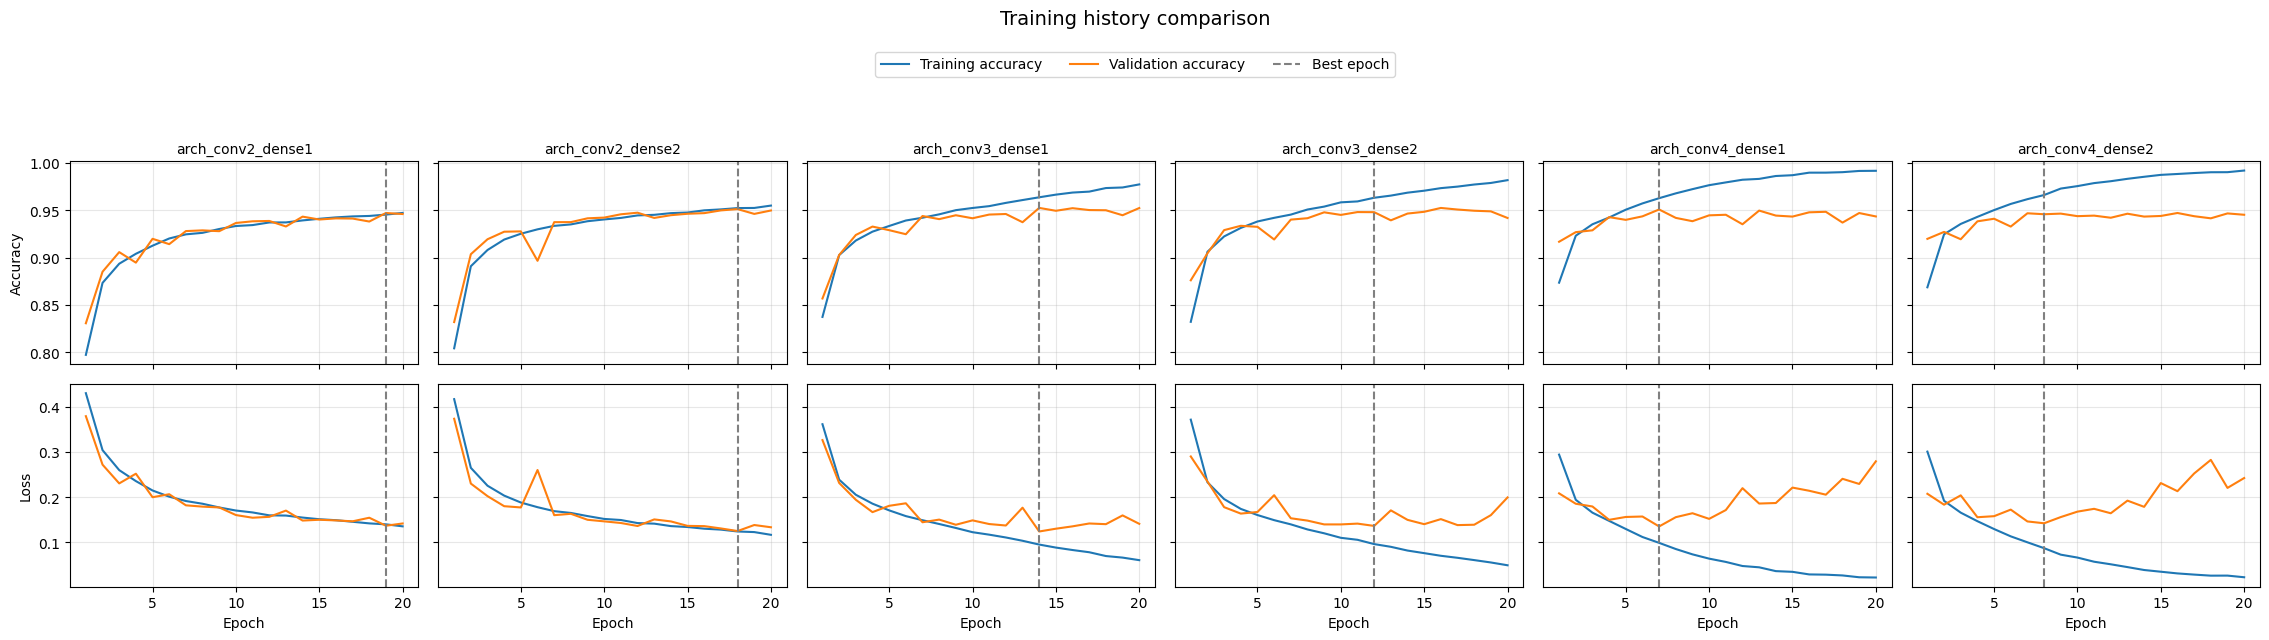

In [19]:
plot_training_history(architecture_experiments)

En términos generales, se observa que las configuraciones de cuatro bloques convolucionales presentan una separación más pronunciada entre las curvas de entrenamiento y validación. Mientras que la accuracy de entrenamiento continúa aumentando y la pérdida disminuye, el comportamiento de validación deja de mejorar, lo que constituye un indicio de sobreajuste.

Las arquitecturas de dos bloques convolucionales presentan un comportamiento más equilibrado, con diferencias menos pronunciadas entre entrenamiento y validación. Por su parte, las configuraciones de tres bloques alcanzan un mayor rendimiento de validación, aunque también muestran un deterioro de la capacidad de generalización durante las últimas épocas.

En particular, los modelos de tres bloques convolucionales alcanzan su mejor resultado de validación en la época 12, mientras que las configuraciones de cuatro bloques lo hacen en las épocas 5 y 8, respectivamente. Este comportamiento sugiere que el incremento de profundidad puede favorecer inicialmente el aprendizaje, pero también acelerar la aparición de sobreajuste.

A continuación, se recopilan las métricas obtenidas utilizando los pesos correspondientes a la mejor época de validación de cada modelo.

In [20]:
architecture_results = get_results_table(architecture_experiments)

display(
    architecture_results[
        [
            "experiment",
            "val_loss",
            "val_accuracy",
            "val_precision",
            "val_recall",
            "val_f1_real",
            "val_macro_f1",
            "best_epoch",
            "parameters",
            "training_seconds"
        ]
    ]
)

,experiment,val_loss,val_accuracy,val_precision,val_recall,val_f1_real,val_macro_f1,best_epoch,parameters,training_seconds
0,arch_conv3_dense1,0.124138,0.952381,0.957299,0.9483,0.952778,0.952378,14,109889,786.526903
1,arch_conv2_dense2,0.125157,0.951114,0.958025,0.9449,0.951417,0.951113,18,36033,565.558389
2,arch_conv4_dense1,0.135298,0.950709,0.962496,0.9393,0.950757,0.950709,7,421441,1008.941401
3,arch_conv3_dense2,0.136464,0.947872,0.945123,0.9524,0.948747,0.947857,12,118081,807.636879
4,arch_conv2_dense1,0.136907,0.947011,0.962309,0.9319,0.946860,0.947011,19,27841,539.615495
5,arch_conv4_dense2,0.142323,0.945694,0.939457,0.9543,0.946820,0.945670,8,429633,1173.706700


La métrica Precision, Recall y F1 REAL se calcula considerando REAL como clase positiva. El Macro F1 representa la media de los F1-score de las dos clases.

Se observa que la arquitectura formada por tres bloques convolucionales y una capa densa obtiene los mejores resultados globales, alcanzando una accuracy del 95.24 % y un Macro F1 de 0.9524. También presenta la menor pérdida de validación, con un valor de 0.1241.

Resulta también interesante la configuración de dos bloques convolucionales y dos capas densas, que alcanza una accuracy del 95.11 % y un Macro F1 de 0.9511 utilizando solamente 36033 parámetros. Esta alternativa ofrece un compromiso entre complejidad y rendimiento que también podría ser interesante si se priorizase la simplicidad del modelo o si hubiese restricciones de memoria y cálculo.

Los resultados obtenidos permiten extraer varias conclusiones sobre la influencia de la arquitectura en el rendimiento de la CNN.

En primer lugar, el incremento del número de bloques convolucionales de dos a tres permite mejorar los resultados de validación. La arquitectura de tres bloques convolucionales y una capa densa obtiene las mejores métricas globales, lo que sugiere que una mayor profundidad en el extractor de características permite identificar patrones más discriminativos para distinguir entre imágenes reales y generadas artificialmente. Sin embargo, este incremento de capacidad también se traduce en un mayor número de parámetros y en una mayor diferencia entre el rendimiento de entrenamiento y validación durante las últimas épocas. Por tanto, la mejora de rendimiento debe valorarse conjuntamente con el posible incremento del sobreajuste.

En segundo lugar, aumentar el número de bloques convolucionales hasta cuatro no proporciona mejoras adicionales. Ambas configuraciones presentan peores métricas de validación que las arquitecturas de dos y tres bloques, a pesar de disponer de un número considerablemente mayor de parámetros. Además, sus curvas de aprendizaje muestran una aparición más temprana y pronunciada del sobreajuste. Estos resultados indican que incrementar la profundidad de la red más allá de tres bloques no resulta beneficioso bajo las condiciones experimentales consideradas.

En cuanto al número de capas densas, su efecto depende de la profundidad del extractor convolucional. Para las arquitecturas de dos bloques, incorporar una segunda capa densa mejora el rendimiento de validación respecto a utilizar una única capa. Sin embargo, este comportamiento no se mantiene al utilizar tres o cuatro bloques convolucionales, donde la segunda capa densa no proporciona mejoras globales relevantes. Por tanto, no se observa una relación directa entre el incremento del número de capas densas y la capacidad de generalización.

Por estos motivos, se selecciona arch_conv3_dense1 como arquitectura de referencia para las siguientes etapas de experimentación. Su mayor capacidad representacional respecto a las configuraciones más sencillas, junto con el sobreajuste observado durante las últimas épocas, permitirá estudiar si el ajuste de los hiperparámetros y la incorporación de técnicas de regularización pueden mejorar aún más su capacidad de generalización.

### 4.2.3. Comparación de las operaciones de reducción espacial

Una vez seleccionada la arquitectura de referencia, se estudia la influencia de la operación utilizada para transformar los mapas de características generados por los bloques convolucionales en un vector de entrada para las capas densas. Hasta este punto se ha utilizado GlobalAveragePooling2D (GAP), que calcula la media espacial de cada mapa de características y genera un único valor por canal. Esta operación permite reducir considerablemente la dimensionalidad de la representación y, en consecuencia, el número de parámetros de las capas densas.

Como alternativa, se propone utilizar Flatten, que transforma directamente el conjunto de mapas de características en un vector unidimensional, conservando la información correspondiente a las diferentes posiciones espaciales. A diferencia de GAP, esta operación no realiza ninguna agregación espacial, por lo que las capas densas reciben una representación de mayor dimensión y pueden aprender relaciones entre las características detectadas y sus respectivas posiciones dentro de la imagen. La utilización de Flatten incrementa considerablemente el número de parámetros entrenables, lo que puede proporcionar una mayor capacidad de representación, pero también aumentar el riesgo de sobreajuste y el coste computacional.

Para estudiar experimentalmente el efecto de ambas alternativas, se utilizará la arquitectura seleccionada en el apartado anterior, formada por tres bloques convolucionales y una capa densa. Se mantendrán constantes todos sus componentes y los hiperparámetros de entrenamiento, modificando únicamente la operación de reducción espacial. La comparación permitirá determinar si conservar la información espacial mediante Flatten proporciona una mejora suficiente en el rendimiento de clasificación que justifique el incremento de complejidad respecto a GlobalAveragePooling2D.

In [21]:
# Recuperar la configuración del modelo Conv3 + Dense1
flatten_config = experiment_configs["arch_conv3_dense1"].copy()

# Modificar únicamente la operación de reducción espacial
flatten_config["spatial_reduction"] = "flatten"

# Ejecutar el experimento
flatten_experiment_name = "arch_conv3_dense1_flatten"

run_experiment(
    experiment_name=flatten_experiment_name,
    model_config=flatten_config,
    batch_size=64,
    epochs=20
)


EXPERIMENTO: arch_conv3_dense1_flatten
CONFIGURACIÓN: {'num_conv_blocks': 3, 'num_dense_layers': 1, 'spatial_reduction': 'flatten', 'activation': 'relu', 'optimizer_name': 'adam', 'learning_rate': 0.001}
BATCH SIZE: 64
Epoch 1/20


c:\Users\angel\AppData\Local\Programs\Python\Python314\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


1234/1234 - 53s - 43ms/step - accuracy: 0.8787 - f1_real: 0.8812 - loss: 0.2845 - precision: 0.8742 - recall: 0.8883 - val_accuracy: 0.9142 - val_f1_real: 0.9145 - val_loss: 0.2137 - val_precision: 0.9227 - val_recall: 0.9065
Epoch 2/20
1234/1234 - 57s - 46ms/step - accuracy: 0.9269 - f1_real: 0.9279 - loss: 0.1873 - precision: 0.9272 - recall: 0.9286 - val_accuracy: 0.9334 - val_f1_real: 0.9355 - val_loss: 0.1714 - val_precision: 0.9193 - val_recall: 0.9522
Epoch 3/20
1234/1234 - 48s - 39ms/step - accuracy: 0.9365 - f1_real: 0.9374 - loss: 0.1618 - precision: 0.9365 - recall: 0.9383 - val_accuracy: 0.9330 - val_f1_real: 0.9323 - val_loss: 0.1689 - val_precision: 0.9546 - val_recall: 0.9110
Epoch 4/20
1234/1234 - 48s - 39ms/step - accuracy: 0.9453 - f1_real: 0.9460 - loss: 0.1402 - precision: 0.9456 - recall: 0.9464 - val_accuracy: 0.9401 - val_f1_real: 0.9412 - val_loss: 0.1505 - val_precision: 0.9368 - val_recall: 0.9456
Epoch 5/20
1234/1234 - 49s - 40ms/step - accuracy: 0.9513 - f1_

{'experiment': 'arch_conv3_dense1_flatten',
 'val_loss': 0.14742551743984222,
 'val_accuracy': 0.9429584741592407,
 'val_precision': 0.9342337250709534,
 'val_recall': 0.9545999765396118,
 'val_f1_real': 0.9443069696426392,
 'val_macro_f1': 0.9429249936978595,
 'best_epoch': 5,
 'parameters': 355649,
 'training_seconds': 1013.1100470000019,
 'batch_size': 64}

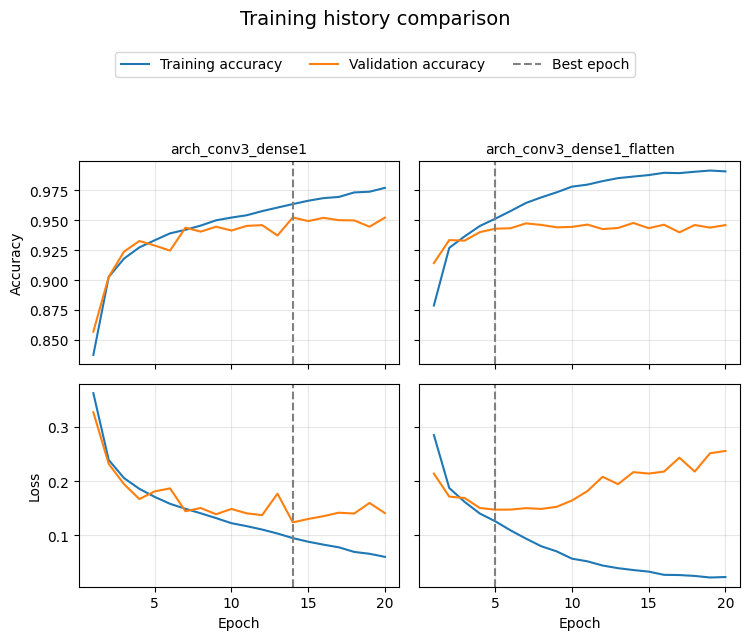

In [22]:
reduction_experiments = ["arch_conv3_dense1", "arch_conv3_dense1_flatten"]

plot_training_history(reduction_experiments)

In [23]:
# Tabla comparativa
reduction_results = get_results_table(reduction_experiments)

display(
    reduction_results[
        [
            "experiment",
            "val_loss",
            "val_accuracy",
            "val_precision",
            "val_recall",
            "val_f1_real",
            "val_macro_f1",
            "best_epoch",
            "parameters",
            "training_seconds"
        ]
    ]
)

,experiment,val_loss,val_accuracy,val_precision,val_recall,val_f1_real,val_macro_f1,best_epoch,parameters,training_seconds
0,arch_conv3_dense1,0.124138,0.952381,0.957299,0.9483,0.952778,0.952378,14,109889,786.526903
1,arch_conv3_dense1_flatten,0.147426,0.942958,0.934234,0.9546,0.944307,0.942925,5,355649,1013.110047


Los resultados obtenidos muestran que GlobalAveragePooling2D proporciona un mejor rendimiento de validación que Flatten para la arquitectura estudiada. En concreto, el modelo que utiliza GAP alcanza una accuracy del 95.24 % y un Macro F1 de 0.9524, frente al 94.30 % y 0.9429 obtenidos con Flatten. Asimismo, presenta una menor pérdida de validación (0.1241 frente a 0.1474), lo que indica una mejor capacidad de generalización.

En cuanto a la complejidad, la utilización de Flatten incrementa el número de parámetros entrenables de 109889 a 355649, aproximadamente 3 veces más que la configuración con GAP. Este incremento se debe principalmente al mayor número de entradas que recibe la primera capa densa, consecuencia de conservar las dimensiones espaciales de los mapas de características.

Las curvas de aprendizaje permiten identificar diferencias importantes en el comportamiento de ambos modelos. Mientras que la arquitectura con GAP presenta una evolución relativamente equilibrada entre las métricas de entrenamiento y validación, la variante con Flatten muestra una separación mucho más pronunciada. En particular, su pérdida de entrenamiento continúa disminuyendo durante las épocas, mientras que la pérdida de validación aumenta progresivamente a partir de la quinta época. Este comportamiento constituye una evidencia clara de sobreajuste, indicando que la mayor capacidad del clasificador permite ajustar mejor los datos de entrenamiento, pero no se traduce en una mejora de la generalización.

Por tanto, los resultados experimentales indican que conservar toda la información espacial mediante Flatten no aporta ventajas para la arquitectura y el conjunto de datos considerados. Por el contrario, la reducción dimensional proporcionada por Global Average Pooling permite limitar la complejidad del clasificador y obtener una mejor capacidad de generalización.

En consecuencia, se selecciona GlobalAveragePooling2D como operación de reducción espacial para los siguientes experimentos.

### 4.2.4. Selección de la arquitectura de referencia

A partir de los experimentos realizados, se selecciona la arquitectura formada por tres bloques convolucionales, una capa densa y una operación GlobalAveragePooling2D como configuración de referencia para las siguientes etapas del proyecto.

La elección se fundamenta, en primer lugar, en los resultados obtenidos durante la exploración arquitectónica. La configuración arch_conv3_dense1 ha proporcionado el mejor rendimiento global sobre el conjunto de validación. Aunque otras configuraciones presentan resultados próximos en determinadas métricas, esta arquitectura ofrece el mejor equilibrio global entre precision, recall y capacidad de clasificación.

En segundo lugar, la comparación entre las operaciones de reducción espacial ha mostrado que GlobalAveragePooling2D proporciona mejores resultados que Flatten para la arquitectura seleccionada. En concreto, GAP alcanza una mayor accuracy y Macro F1, además de una menor pérdida de validación. Asimismo, reduce considerablemente el número de parámetros entrenables, pasando de 355649 con Flatten a 109889 con GAP. Las curvas de aprendizaje también muestran un comportamiento más favorable y una menor tendencia al sobreajuste.

Por otra parte, aunque la arquitectura seleccionada presenta un mayor número de parámetros que algunas de las alternativas más sencillas, esta complejidad se considera asumible para el problema abordado. Por tanto, se prioriza el rendimiento predictivo y la capacidad de representación frente a una reducción adicional del número de parámetros que no resulta necesaria dadas las condiciones de aplicación consideradas.

En consecuencia, la arquitectura seleccionada se utilizará como base para la optimización de los hiperparámetros y el estudio posterior de las técnicas de regularización y data augmentation. Se mantendrá inicialmente la configuración de entrenamiento utilizada en los experimentos anteriores y se modificarán progresivamente los parámetros objeto de estudio, analizando su efecto sobre el rendimiento y la capacidad de generalización.

Es importante señalar que esta selección constituye una configuración de referencia y no necesariamente el modelo definitivo del proyecto. Las siguientes etapas permitirán determinar si los ajustes introducidos mejoran su rendimiento y reducen el sobreajuste observado durante las últimas épocas de entrenamiento.

In [24]:
# Arquitectura de referencia seleccionada
REFERENCE_EXPERIMENT = "arch_conv3_dense1"

REFERENCE_CONFIG = experiment_configs[REFERENCE_EXPERIMENT].copy()

REFERENCE_BATCH_SIZE = 64
REFERENCE_EPOCHS = 20

# Mostrar configuración
print("Arquitectura de referencia:")
print(REFERENCE_CONFIG)

print("\nBatch size:", REFERENCE_BATCH_SIZE)
print("Épocas:", REFERENCE_EPOCHS)

# Construir el modelo para comprobar su arquitectura
reference_model = build_cnn(**REFERENCE_CONFIG)

reference_model.summary()

print("\nNúmero total de parámetros:", reference_model.count_params())

Arquitectura de referencia:
{'num_conv_blocks': 3, 'num_dense_layers': 1, 'spatial_reduction': 'gap', 'activation': 'relu', 'optimizer_name': 'adam', 'learning_rate': 0.001}

Batch size: 64
Épocas: 20


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_1 (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ maxpool_1 (MaxPooling2D)        │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_2 (Conv2D)                 │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_5 (Activation)       │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ maxpool_2 (MaxPooling2D)        │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_3 (Conv2D)                 │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_6 (Activation)       │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ maxpool_3 (MaxPooling2D)        │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_7 (Activation)       │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,889 (429.25 KB)

 Trainable params: 109,889 (429.25 KB)

 Non-trainable params: 0 (0.00 B)


Número total de parámetros: 109889


Una vez definida la arquitectura de referencia, el siguiente paso consiste en estudiar cómo afectan las condiciones de entrenamiento al rendimiento del modelo. Para ello, se analizará la influencia del optimizador, la tasa de aprendizaje, el tamaño de batch y la función de activación, manteniendo inicialmente fija la arquitectura seleccionada. El objetivo será identificar una configuración de hiperparámetros que permita mejorar el proceso de aprendizaje y establecer una base adecuada para la posterior incorporación de técnicas de regularización.

## 4.3. Optimización de hiperparámetros

Una vez seleccionada la arquitectura de referencia, se procede a estudiar la influencia de los principales hiperparámetros que controlan el proceso de entrenamiento de la red neuronal. A diferencia de la etapa anterior, en la que se modificaron diferentes componentes de la arquitectura, en esta fase se mantendrá fija la estructura de la CNN y se analizará cómo afectan las condiciones de entrenamiento al rendimiento y a la capacidad de generalización del modelo.

La experimentación se organizará en torno a cuatro aspectos: el optimizador y la tasa de aprendizaje, el tamaño de batch, la función de activación y, finalmente, la selección de la configuración conjunta más adecuada.

En cada experimento se modificará el parámetro o conjunto de parámetros objeto de estudio, manteniendo constantes los restantes elementos de la configuración siempre que sea posible. De esta manera, se pretende identificar qué alternativas favorecen la convergencia del modelo y permiten obtener mejores resultados sobre el conjunto de validación.

La arquitectura utilizada será la seleccionada en el apartado anterior, formada por tres bloques convolucionales, una operación GlobalAveragePooling2D y una capa densa de 128 neuronas. Se utilizará inicialmente la configuración de entrenamiento definida como referencia, modificando progresivamente los hiperparámetros objeto de estudio.

Los resultados se analizarán mediante las métricas de clasificación y las curvas de entrenamiento y validación, prestando especial atención a posibles mejoras de rendimiento, estabilidad del aprendizaje y comportamiento frente al sobreajuste.

### 4.3.1. Optimizador y tasa de aprendizaje

El optimizador determina cómo se actualizan los pesos de la red neuronal durante el entrenamiento con el objetivo de minimizar la función de pérdida. Su elección influye en la velocidad de convergencia, la estabilidad de las actualizaciones y, potencialmente, en la capacidad de generalización del modelo. Por su parte, la tasa de aprendizaje controla la magnitud de las actualizaciones de los pesos. Una tasa demasiado elevada puede provocar oscilaciones o dificultar la convergencia, mientras que una tasa excesivamente reducida puede ralentizar el aprendizaje y requerir un mayor número de épocas para alcanzar una solución adecuada.

Con el objetivo de estudiar la influencia de estos parámetros, se compararán tres optimizadores: Adam, RMSprop y Stochastic Gradient Descent (SGD) con momentum. Estos algoritmos presentan mecanismos de actualización diferentes y permiten analizar distintas estrategias de optimización. Para cada optimizador se evalúan inicialmente diferentes valores de tasa de aprendizaje, manteniendo constantes el resto de las condiciones experimentales. Esta primera batería permitirá identificar las combinaciones más prometedoras y analizar su comportamiento durante el entrenamiento.

Se plantean ocho configuraciones experimentales, combinando los tres optimizadores seleccionados con diferentes valores de tasa de aprendizaje. Para SGD se utiliza un valor de momentum de 0.9.

| Optimizador | Learning rate |
|---|---:|
| Adam | 0.0001 |
| Adam | 0.0003 |
| Adam | 0.001 |
| RMSprop | 0.0001 |
| RMSprop | 0.0003 |
| RMSprop | 0.001 |
| SGD + Momentum | 0.001 |
| SGD + Momentum | 0.01 |

En esta primera fase, todos los modelos se entrenan durante un máximo de 20 épocas, utilizando la arquitectura de referencia definida en el apartado anterior y un tamaño de batch de 64 imágenes.

Los resultados obtenidos permitirán identificar diferencias tanto en el rendimiento de validación como en la evolución de las curvas de aprendizaje.


In [25]:
optimizer_candidates = [
    ("adam", 0.0001),
    ("adam", 0.0003),
    ("adam", 0.001),

    ("rmsprop", 0.0001),
    ("rmsprop", 0.0003),
    ("rmsprop", 0.001),

    ("sgd", 0.001),
    ("sgd", 0.01)
]

optimizer_experiments = []

for optimizer_name, learning_rate in optimizer_candidates:

    experiment_name = (
        f"optimizer_{optimizer_name}_lr_{learning_rate}"
    )

    # Copiar la arquitectura de referencia
    config = REFERENCE_CONFIG.copy()

    # Modificar los parámetros objeto de estudio
    config["optimizer_name"] = optimizer_name
    config["learning_rate"] = learning_rate
    config["momentum"] = 0.9

    # Ejecutar entrenamiento
    run_experiment(
        experiment_name=experiment_name,
        model_config=config,
        batch_size=REFERENCE_BATCH_SIZE,
        epochs=REFERENCE_EPOCHS
    )

    optimizer_experiments.append(experiment_name)


EXPERIMENTO: optimizer_adam_lr_0.0001
CONFIGURACIÓN: {'num_conv_blocks': 3, 'num_dense_layers': 1, 'spatial_reduction': 'gap', 'activation': 'relu', 'optimizer_name': 'adam', 'learning_rate': 0.0001, 'momentum': 0.9}
BATCH SIZE: 64
Epoch 1/20


c:\Users\angel\AppData\Local\Programs\Python\Python314\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


1234/1234 - 50s - 40ms/step - accuracy: 0.7509 - f1_real: 0.7672 - loss: 0.4983 - precision: 0.7286 - recall: 0.8102 - val_accuracy: 0.8282 - val_f1_real: 0.8232 - val_loss: 0.4069 - val_precision: 0.8598 - val_recall: 0.7896
Epoch 2/20
1234/1234 - 50s - 41ms/step - accuracy: 0.8422 - f1_real: 0.8474 - loss: 0.3673 - precision: 0.8306 - recall: 0.8648 - val_accuracy: 0.8241 - val_f1_real: 0.8429 - val_loss: 0.3731 - val_precision: 0.7695 - val_recall: 0.9318
Epoch 3/20
1234/1234 - 49s - 40ms/step - accuracy: 0.8664 - f1_real: 0.8691 - loss: 0.3243 - precision: 0.8627 - recall: 0.8756 - val_accuracy: 0.8450 - val_f1_real: 0.8267 - val_loss: 0.3774 - val_precision: 0.9534 - val_recall: 0.7297
Epoch 4/20
1234/1234 - 48s - 39ms/step - accuracy: 0.8783 - f1_real: 0.8800 - loss: 0.2992 - precision: 0.8788 - recall: 0.8813 - val_accuracy: 0.8849 - val_f1_real: 0.8869 - val_loss: 0.2813 - val_precision: 0.8827 - val_recall: 0.8912
Epoch 5/20
1234/1234 - 46s - 38ms/step - accuracy: 0.8858 - f1_

c:\Users\angel\AppData\Local\Programs\Python\Python314\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


1234/1234 - 45s - 37ms/step - accuracy: 0.7982 - f1_real: 0.8069 - loss: 0.4296 - precision: 0.7832 - recall: 0.8320 - val_accuracy: 0.8700 - val_f1_real: 0.8706 - val_loss: 0.3173 - val_precision: 0.8782 - val_recall: 0.8631
Epoch 2/20
1234/1234 - 35s - 29ms/step - accuracy: 0.8751 - f1_real: 0.8767 - loss: 0.3025 - precision: 0.8763 - recall: 0.8772 - val_accuracy: 0.8680 - val_f1_real: 0.8789 - val_loss: 0.3080 - val_precision: 0.8212 - val_recall: 0.9453
Epoch 3/20
1234/1234 - 35s - 28ms/step - accuracy: 0.8918 - f1_real: 0.8930 - loss: 0.2651 - precision: 0.8950 - recall: 0.8909 - val_accuracy: 0.8887 - val_f1_real: 0.8818 - val_loss: 0.2658 - val_precision: 0.9545 - val_recall: 0.8194
Epoch 4/20
1234/1234 - 35s - 28ms/step - accuracy: 0.9045 - f1_real: 0.9055 - loss: 0.2346 - precision: 0.9081 - recall: 0.9029 - val_accuracy: 0.9131 - val_f1_real: 0.9157 - val_loss: 0.2147 - val_precision: 0.9001 - val_recall: 0.9318
Epoch 5/20
1234/1234 - 39s - 31ms/step - accuracy: 0.9118 - f1_

c:\Users\angel\AppData\Local\Programs\Python\Python314\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


... (7 outputs left out)

c:\Users\angel\AppData\Local\Programs\Python\Python314\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


1234/1234 - 38s - 31ms/step - accuracy: 0.5463 - f1_real: 0.6767 - loss: 0.6901 - precision: 0.5295 - recall: 0.9374 - val_accuracy: 0.5908 - val_f1_real: 0.6806 - val_loss: 0.6850 - val_precision: 0.5629 - val_recall: 0.8605
Epoch 2/20
1234/1234 - 35s - 28ms/step - accuracy: 0.6104 - f1_real: 0.6604 - loss: 0.6683 - precision: 0.5913 - recall: 0.7479 - val_accuracy: 0.6456 - val_f1_real: 0.6248 - val_loss: 0.6394 - val_precision: 0.6738 - val_recall: 0.5824
Epoch 3/20
1234/1234 - 35s - 28ms/step - accuracy: 0.6960 - f1_real: 0.7116 - loss: 0.5788 - precision: 0.6850 - recall: 0.7404 - val_accuracy: 0.7158 - val_f1_real: 0.6652 - val_loss: 0.5607 - val_precision: 0.8250 - val_recall: 0.5572
Epoch 4/20
1234/1234 - 35s - 28ms/step - accuracy: 0.7625 - f1_real: 0.7753 - loss: 0.4900 - precision: 0.7445 - recall: 0.8088 - val_accuracy: 0.7894 - val_f1_real: 0.8088 - val_loss: 0.4418 - val_precision: 0.7488 - val_recall: 0.8792
Epoch 5/20
1234/1234 - 35s - 28ms/step - accuracy: 0.8122 - f1_

c:\Users\angel\AppData\Local\Programs\Python\Python314\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


1234/1234 - 40s - 32ms/step - accuracy: 0.7051 - f1_real: 0.7350 - loss: 0.5441 - precision: 0.6746 - recall: 0.8073 - val_accuracy: 0.7951 - val_f1_real: 0.8219 - val_loss: 0.4241 - val_precision: 0.7343 - val_recall: 0.9331
Epoch 2/20
1234/1234 - 35s - 28ms/step - accuracy: 0.8421 - f1_real: 0.8444 - loss: 0.3622 - precision: 0.8431 - recall: 0.8458 - val_accuracy: 0.8718 - val_f1_real: 0.8726 - val_loss: 0.2961 - val_precision: 0.8788 - val_recall: 0.8665
Epoch 3/20
1234/1234 - 35s - 28ms/step - accuracy: 0.8802 - f1_real: 0.8816 - loss: 0.2853 - precision: 0.8827 - recall: 0.8804 - val_accuracy: 0.9048 - val_f1_real: 0.9035 - val_loss: 0.2346 - val_precision: 0.9287 - val_recall: 0.8796
Epoch 4/20
1234/1234 - 35s - 28ms/step - accuracy: 0.9016 - f1_real: 0.9029 - loss: 0.2410 - precision: 0.9031 - recall: 0.9027 - val_accuracy: 0.8911 - val_f1_real: 0.8993 - val_loss: 0.2608 - val_precision: 0.8458 - val_recall: 0.9601
Epoch 5/20
1234/1234 - 35s - 28ms/step - accuracy: 0.9128 - f1_

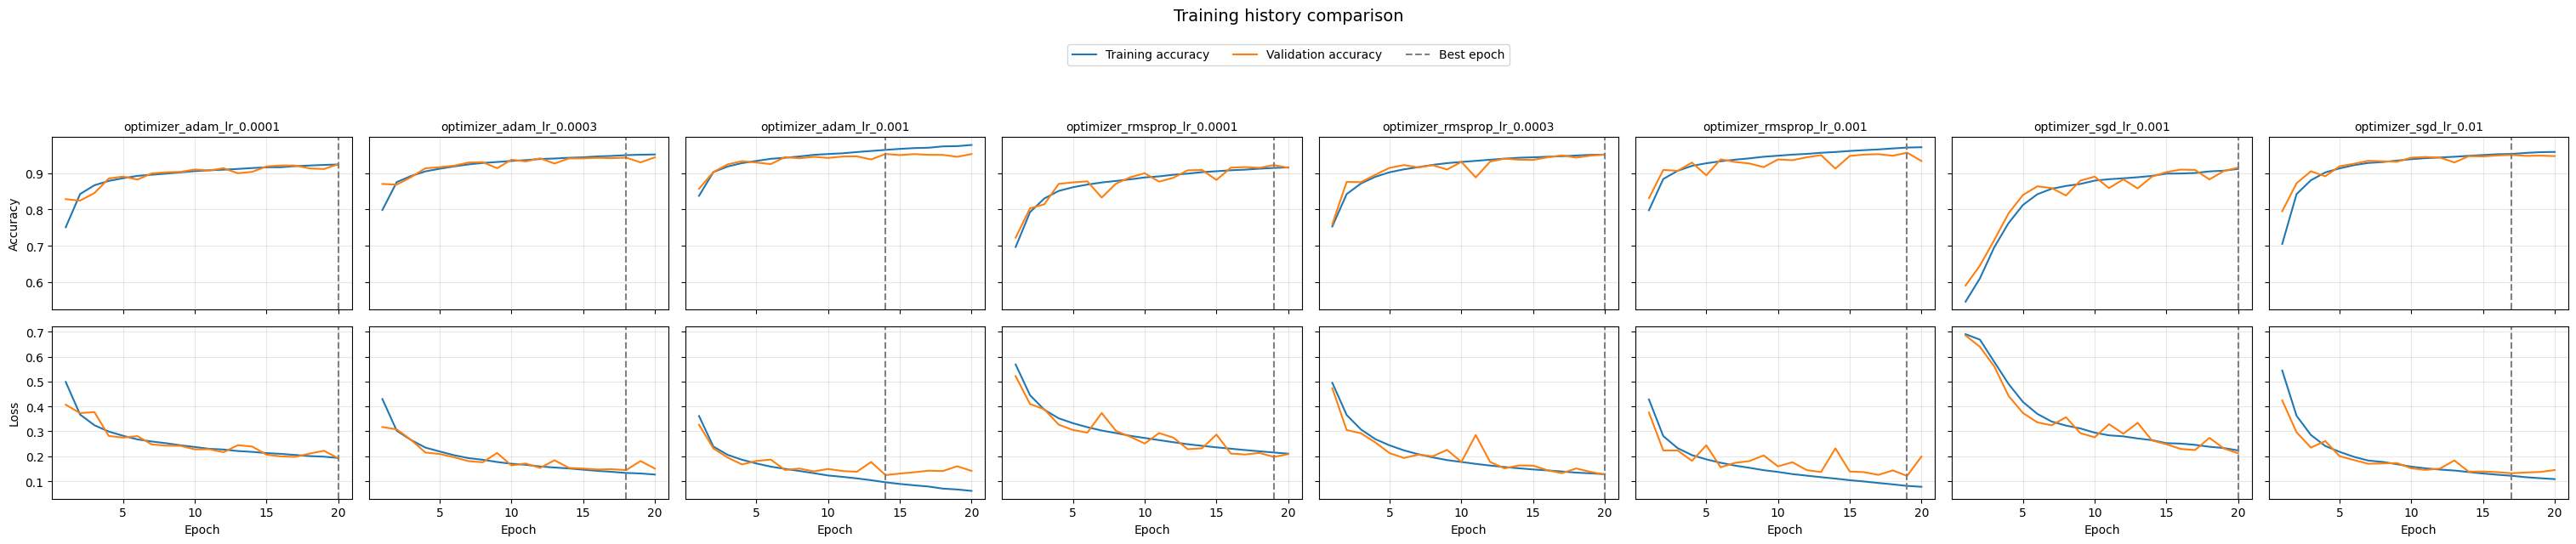

In [26]:
plot_training_history(optimizer_experiments)

In [27]:
optimizer_results = get_results_table(
    optimizer_experiments
)

display(
    optimizer_results[
        [
            "experiment",
            "val_loss",
            "val_accuracy",
            "val_precision",
            "val_recall",
            "val_f1_real",
            "val_macro_f1",
            "best_epoch",
            "parameters",
            "training_seconds"
        ]
    ]
)

,experiment,val_loss,val_accuracy,val_precision,val_recall,val_f1_real,val_macro_f1,best_epoch,parameters,training_seconds
0,optimizer_rmsprop_lr_0.001,0.120787,0.955927,0.961951,0.9506,0.956242,0.955925,19,109889,701.787476
1,optimizer_adam_lr_0.001,0.124138,0.952381,0.957299,0.9483,0.952778,0.952378,14,109889,706.898709
2,optimizer_rmsprop_lr_0.0003,0.125621,0.950912,0.947212,0.9564,0.951784,0.950896,20,109889,704.379012
3,optimizer_sgd_lr_0.01,0.131606,0.949797,0.941401,0.9607,0.950953,0.949769,17,109889,699.432493
4,optimizer_adam_lr_0.0003,0.144261,0.942351,0.929277,0.9592,0.944001,0.942300,18,109889,728.682359
5,optimizer_adam_lr_0.0001,0.191781,0.924316,0.949577,0.8983,0.923227,0.924301,20,109889,805.612413
6,optimizer_rmsprop_lr_0.0001,0.197073,0.921986,0.933579,0.9108,0.922049,0.921986,19,109889,707.866955
7,optimizer_sgd_lr_0.001,0.211570,0.914792,0.907745,0.9259,0.916733,0.914746,20,109889,699.119676


Los resultados muestran que la elección del optimizador y de la tasa de aprendizaje tiene una influencia significativa sobre el rendimiento del modelo. Entre las ocho configuraciones evaluadas, **RMSprop con una tasa de aprendizaje de 0.001 obtiene los mejores resultados globales**, alcanzando una pérdida de validación de 0.1208, una accuracy del 95.59 % y una puntuación Macro F1 del 95.59 %. También consigue la mayor precisión (96.20 %) y el mayor F1-REAL (95.62 %). Su recall es del 95.06 %, ligeramente inferior al obtenido con SGD y una tasa de aprendizaje de 0.01 (96.07 %).

Adam con una tasa de aprendizaje de 0.001 proporciona resultados competitivos, con una accuracy del 95.24 % y un Macro F1 del 95.24 %, situándose por detrás de RMSprop con 0.001. Por su parte, RMSprop con 0.0003 y SGD con 0.01 también alcanzan resultados razonables, aunque sus métricas globales son inferiores.

En general, se observa que las tasas de aprendizaje más elevadas dentro de los rangos evaluados permiten alcanzar mejores resultados durante las 20 épocas de entrenamiento, mientras que las configuraciones con tasas más reducidas presentan una convergencia más lenta y un rendimiento inferior. El análisis de las curvas también revela diferencias en la evolución del aprendizaje: Adam con 0.001 alcanza su mejor resultado en la época 14 y SGD con 0.01 en la época 17, mientras que RMSprop con 0.001 lo consigue en la época 19. Esto indica que algunas configuraciones alcanzan su mejor rendimiento antes de finalizar el entrenamiento, mientras que otras mantienen una evolución favorable hasta las últimas épocas.

A partir de estos resultados se selecciona **RMSprop con una tasa de aprendizaje de 0.001** como optimizador de referencia para los siguientes experimentos. Esta configuración proporciona el mejor equilibrio entre las métricas de validación y alcanza un rendimiento elevado dentro del presupuesto de 20 épocas establecido. Aunque su mejor resultado se obtiene en la época 19, se considera suficiente para avanzar a las siguientes fases experimentales sin realizar una segunda batería de entrenamientos más prolongados. De este modo, se mantiene un coste computacional razonable y se concentra la experimentación posterior en el análisis de otros factores que pueden influir en la capacidad de generalización del modelo.

Finalmente, se define este modelo como la configuración de referencia para los siguientes experimentos.

In [28]:
# Actualizar la configuración de referencia
# con los resultados del experimento de optimización

REFERENCE_CONFIG.update({
    "optimizer_name": "rmsprop",
    "learning_rate": 0.001,
    "momentum": 0.9
})

# Parámetros de entrenamiento de referencia
REFERENCE_BATCH_SIZE = 64
REFERENCE_EPOCHS = 20

print("Nueva configuración de referencia:")
print(REFERENCE_CONFIG)

print("\nBatch size:", REFERENCE_BATCH_SIZE)
print("Épocas:", REFERENCE_EPOCHS)

Nueva configuración de referencia:
{'num_conv_blocks': 3, 'num_dense_layers': 1, 'spatial_reduction': 'gap', 'activation': 'relu', 'optimizer_name': 'rmsprop', 'learning_rate': 0.001, 'momentum': 0.9}

Batch size: 64
Épocas: 20


### 4.3.2. Tamaño de batch

El tamaño de batch determina el número de imágenes que se procesan antes de realizar una actualización de los pesos de la red neuronal. Este parámetro influye tanto en la dinámica del proceso de optimización como en el coste computacional del entrenamiento. Utilizar tamaños de batch reducidos implica realizar actualizaciones de los pesos más frecuentes, utilizando gradientes calculados a partir de un menor número de muestras. Esto puede introducir una mayor variabilidad en las actualizaciones, pero también favorecer determinadas propiedades de generalización. Por el contrario, los tamaños de batch elevados permiten estimar los gradientes utilizando un mayor número de imágenes, lo que suele producir actualizaciones más estables, aunque reduce su frecuencia para un mismo número de épocas.

Con el objetivo de estudiar experimentalmente esta influencia, se compararán tres tamaños de batch: 32, 64 y 128 imágenes. El experimento con un tamaño de batch de 64 imágenes no se vuelve a ejecutar, ya que sus resultados se han obtenido en la batería anterior de optimización, utilizando RMSprop con una tasa de aprendizaje de 0.001. Se mantienen constantes el resto de las condiciones experimentales, utilizando la arquitectura de referencia formada por tres bloques convolucionales, una operación Global Average Pooling y una capa densa de 128 neuronas, junto con la función de activación ReLU. Se establece un máximo de 20 épocas para todas las configuraciones y se conservan los pesos correspondientes al mínimo valor de pérdida de validación.

La comparación se realizará mediante las métricas de clasificación obtenidas sobre el conjunto de validación y las curvas de aprendizaje. También se registrará el tiempo de entrenamiento para estudiar cómo afecta el tamaño de batch al coste computacional.

Es importante tener en cuenta que, aunque todas las configuraciones procesan el mismo conjunto de entrenamiento durante 20 épocas, el número de actualizaciones de los pesos será diferente. Un tamaño de batch de 32 implica aproximadamente el doble de actualizaciones por época que un tamaño de 64, mientras que un tamaño de 128 implica aproximadamente la mitad. Esta diferencia forma parte del efecto que se pretende estudiar.


In [29]:
# Experimento de batch size

# Reutilizamos el resultado de batch 64 obtenido
# en la batería de optimizadores con RMSprop y lr=0.001

BATCH_REFERENCE_EXPERIMENT = "optimizer_rmsprop_lr_0.001"

batch_experiments = [BATCH_REFERENCE_EXPERIMENT]

# Configuración de referencia
batch_base_config = REFERENCE_CONFIG.copy()

# Entrenar únicamente batch 32 y batch 128
for batch_size in [32, 128]:

    experiment_name = (f"batch_{batch_size}_rmsprop_lr_0.001")

    run_experiment(
        experiment_name=experiment_name,
        model_config=batch_base_config,
        batch_size=batch_size,
        epochs=REFERENCE_EPOCHS
    )

    batch_experiments.append(experiment_name)



EXPERIMENTO: batch_32_rmsprop_lr_0.001
CONFIGURACIÓN: {'num_conv_blocks': 3, 'num_dense_layers': 1, 'spatial_reduction': 'gap', 'activation': 'relu', 'optimizer_name': 'rmsprop', 'learning_rate': 0.001, 'momentum': 0.9}
BATCH SIZE: 32
Epoch 1/20


c:\Users\angel\AppData\Local\Programs\Python\Python314\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


2468/2468 - 47s - 19ms/step - accuracy: 0.8291 - f1_real: 0.8331 - loss: 0.3770 - precision: 0.8242 - recall: 0.8422 - val_accuracy: 0.8248 - val_f1_real: 0.8507 - val_loss: 0.3856 - val_precision: 0.7487 - val_recall: 0.9848
Epoch 2/20
2468/2468 - 39s - 16ms/step - accuracy: 0.8990 - f1_real: 0.9007 - loss: 0.2484 - precision: 0.8977 - recall: 0.9036 - val_accuracy: 0.9117 - val_f1_real: 0.9137 - val_loss: 0.2166 - val_precision: 0.9040 - val_recall: 0.9237
Epoch 3/20
2468/2468 - 39s - 16ms/step - accuracy: 0.9164 - f1_real: 0.9176 - loss: 0.2111 - precision: 0.9169 - recall: 0.9183 - val_accuracy: 0.9231 - val_f1_real: 0.9265 - val_loss: 0.1931 - val_precision: 0.8978 - val_recall: 0.9571
Epoch 4/20
2468/2468 - 39s - 16ms/step - accuracy: 0.9257 - f1_real: 0.9267 - loss: 0.1884 - precision: 0.9272 - recall: 0.9261 - val_accuracy: 0.9234 - val_f1_real: 0.9278 - val_loss: 0.1944 - val_precision: 0.8871 - val_recall: 0.9724
Epoch 5/20
2468/2468 - 40s - 16ms/step - accuracy: 0.9336 - f1_

c:\Users\angel\AppData\Local\Programs\Python\Python314\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


617/617 - 35s - 57ms/step - accuracy: 0.7594 - f1_real: 0.7717 - loss: 0.4847 - precision: 0.7431 - recall: 0.8025 - val_accuracy: 0.7504 - val_f1_real: 0.7987 - val_loss: 0.5319 - val_precision: 0.6751 - val_recall: 0.9778
Epoch 2/20
617/617 - 32s - 52ms/step - accuracy: 0.8541 - f1_real: 0.8559 - loss: 0.3406 - precision: 0.8562 - recall: 0.8557 - val_accuracy: 0.8197 - val_f1_real: 0.8463 - val_loss: 0.4258 - val_precision: 0.7446 - val_recall: 0.9802
Epoch 3/20
617/617 - 32s - 52ms/step - accuracy: 0.8860 - f1_real: 0.8874 - loss: 0.2741 - precision: 0.8878 - recall: 0.8871 - val_accuracy: 0.8950 - val_f1_real: 0.9012 - val_loss: 0.2518 - val_precision: 0.8615 - val_recall: 0.9446
Epoch 4/20
617/617 - 32s - 51ms/step - accuracy: 0.9018 - f1_real: 0.9031 - loss: 0.2407 - precision: 0.9028 - recall: 0.9034 - val_accuracy: 0.9181 - val_f1_real: 0.9192 - val_loss: 0.1994 - val_precision: 0.9195 - val_recall: 0.9188
Epoch 5/20
617/617 - 32s - 51ms/step - accuracy: 0.9120 - f1_real: 0.91

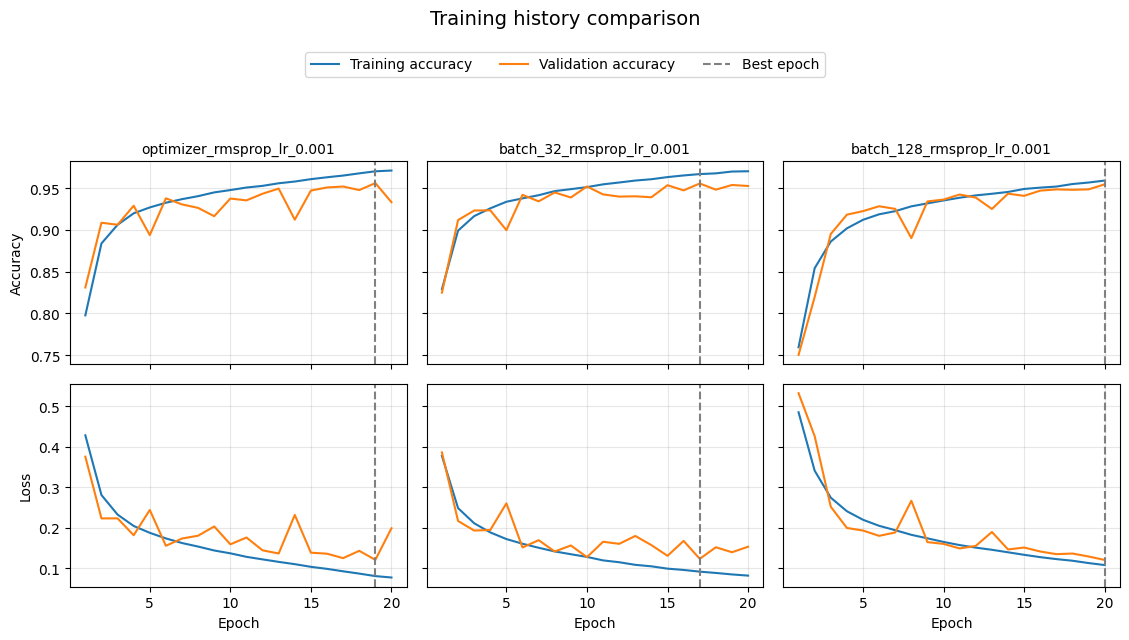

In [30]:
plot_training_history(batch_experiments)

In [31]:
batch_results = get_results_table(batch_experiments)

display(
    batch_results[
        [
            "experiment",
            "batch_size",
            "val_loss",
            "val_accuracy",
            "val_precision",
            "val_recall",
            "val_f1_real",
            "val_macro_f1",
            "best_epoch",
            "parameters",
            "training_seconds"
        ]
    ]
)

,experiment,batch_size,val_loss,val_accuracy,val_precision,val_recall,val_f1_real,val_macro_f1,best_epoch,parameters,training_seconds
0,batch_128_rmsprop_lr_0.001,128,0.120510,0.954458,0.947224,0.9638,0.955440,0.954436,20,109889,636.740377
1,optimizer_rmsprop_lr_0.001,64,0.120787,0.955927,0.961951,0.9506,0.956242,0.955925,19,109889,701.787476
2,batch_32_rmsprop_lr_0.001,32,0.123255,0.955471,0.953646,0.9587,0.956166,0.955460,17,109889,792.989832


Los resultados obtenidos muestran que los tres tamaños de batch proporcionan un rendimiento de validación bastante similar, aunque presentan diferencias en el equilibrio entre las métricas de clasificación. Batch size 64 obtiene la mayor accuracy (95.59 %), la mayor precisión (96.20 %) y la mejor puntuación Macro F1 (95.59 %). Sin embargo, batch size 128 consigue la menor pérdida de validación (0.1205) y el mayor recall (96.38 %). Por su parte, batch size 32 presenta resultados próximos a los de batch size 64, con una accuracy del 95.55 % y un Macro F1 del 95.55 %. Estas diferencias reflejan distintos compromisos entre precisión y recall según el tamaño de batch utilizado.

El análisis de las curvas de aprendizaje permite identificar diferencias adicionales en el comportamiento de los modelos. La configuración con batch size 32 alcanza su mejor resultado de validación en la época 17. Durante las últimas épocas, la pérdida de entrenamiento continúa disminuyendo, mientras que la pérdida de validación presenta ciertas fluctuaciones y deja de mostrar una mejora clara. Esto sugiere la aparición de una cierta separación entre entrenamiento y validación, aunque no se observa un sobreajuste especialmente pronunciado durante las 20 épocas.

Por su parte, batch size 64 alcanza su mejor resultado en la época 19. Las curvas muestran una evolución favorable durante buena parte del entrenamiento, aunque las métricas de validación presentan algunas oscilaciones, especialmente en las últimas épocas. En conjunto, el modelo mantiene un comportamiento relativamente estable y obtiene los mejores resultados globales en las métricas de clasificación.

Finalmente, batch size 128 presenta las curvas más suaves y próximas entre entrenamiento y validación. La pérdida de validación continúa disminuyendo durante el entrenamiento y la accuracy mantiene una tendencia de mejora hasta la última época. No se observa una divergencia pronunciada entre ambas curvas que indique un sobreajuste significativo. El hecho de que el mejor resultado se alcance precisamente en la última época (época 20) sugiere que el modelo podría beneficiarse de un entrenamiento más prolongado. Una posible explicación es que el mayor tamaño de batch implica un menor número de actualizaciones de los pesos por época, lo que puede ralentizar la convergencia bajo el presupuesto de entrenamiento establecido.

En cuanto al coste computacional, batch size 128 proporciona el menor tiempo de entrenamiento, aproximadamente 636 segundos, un 10 % inferior al de batch size 64. En cambio, batch size 32 requiere aproximadamente 793 segundos. Por tanto, el mayor tamaño de batch presenta una ventaja en términos de tiempo de ejecución, mientras que el tamaño de 32 imágenes resulta menos eficiente computacionalmente en esta configuración experimental.

En conjunto, batch size 64 ofrece los mejores resultados en accuracy, precisión y Macro F1, mientras que batch size 128 destaca por su menor pérdida de validación, mayor recall, menor tiempo de entrenamiento y una evolución de las curvas que sugiere que todavía podría seguir mejorando. Aunque batch size 64 constituye por el momento la alternativa con mejores métricas globales de clasificación, las diferencias son reducidas y los resultados obtenidos no permiten descartar que batch size 128 pueda proporcionar un mejor equilibrio tras un entrenamiento más prolongado.

Por este motivo, antes de seleccionar definitivamente el tamaño de batch, se plantea un experimento adicional con la configuración de 128 imágenes, prolongando el entrenamiento durante 10 épocas adicionales. El objetivo es comprobar si la tendencia de mejora observada se mantiene y si esta configuración consigue igualar o superar el rendimiento de las alternativas de 32 y 64 imágenes.

El análisis de las curvas de aprendizaje muestra que la configuración con batch size 128 alcanza su mejor resultado de validación en la última época del entrenamiento (época 20). Además, la pérdida de validación mantiene una tendencia descendente y la accuracy continúa mejorando, sin observarse una divergencia pronunciada entre las curvas de entrenamiento y validación.

Estas observaciones sugieren que el modelo podría beneficiarse de un entrenamiento más prolongado. Para comprobarlo, se plantea una prueba adicional consistente en prolongar el entrenamiento durante 10 épocas, partiendo de los mejores pesos obtenidos en el experimento original.

Se mantendrán constantes la arquitectura, el optimizador RMSprop, la tasa de aprendizaje de 0.001 y el tamaño de batch de 128 imágenes. De esta forma, se podrá estudiar si el modelo sigue mejorando su rendimiento de validación o si alcanza una región de convergencia durante las épocas adicionales.

Este experimento tiene carácter exploratorio y permitirá completar la comparación entre los diferentes tamaños de batch antes de seleccionar la configuración definitiva.

In [32]:
# Experimento original
BATCH128_BASE_EXPERIMENT = "batch_128_rmsprop_lr_0.001"

# Nuevo experimento
BATCH128_EXTENDED_EXPERIMENT = ("batch_128_rmsprop_lr_0.001_extended_10ep")

# Recuperar configuración original
batch128_extended_config = experiment_configs[BATCH128_BASE_EXPERIMENT].copy()

# Recuperar la mejor época del entrenamiento original
batch128_best_epoch = experiment_metrics[BATCH128_BASE_EXPERIMENT]["best_epoch"]

# Continuar durante 10 épocas adicionales
ADDITIONAL_EPOCHS = 10

run_experiment(
    experiment_name=BATCH128_EXTENDED_EXPERIMENT,
    model_config=batch128_extended_config,
    batch_size=128,
    epochs=batch128_best_epoch + ADDITIONAL_EPOCHS,
    initial_weights=experiment_best_weights[BATCH128_BASE_EXPERIMENT],
    initial_epoch=batch128_best_epoch
)


EXPERIMENTO: batch_128_rmsprop_lr_0.001_extended_10ep
CONFIGURACIÓN: {'num_conv_blocks': 3, 'num_dense_layers': 1, 'spatial_reduction': 'gap', 'activation': 'relu', 'optimizer_name': 'rmsprop', 'learning_rate': 0.001, 'momentum': 0.9}
BATCH SIZE: 128
Epoch 21/30


c:\Users\angel\AppData\Local\Programs\Python\Python314\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


617/617 - 36s - 59ms/step - accuracy: 0.9595 - f1_real: 0.9600 - loss: 0.1050 - precision: 0.9602 - recall: 0.9599 - val_accuracy: 0.9521 - val_f1_real: 0.9529 - val_loss: 0.1271 - val_precision: 0.9495 - val_recall: 0.9564
Epoch 22/30
617/617 - 31s - 51ms/step - accuracy: 0.9602 - f1_real: 0.9607 - loss: 0.1009 - precision: 0.9607 - recall: 0.9607 - val_accuracy: 0.9425 - val_f1_real: 0.9453 - val_loss: 0.1533 - val_precision: 0.9126 - val_recall: 0.9804
Epoch 23/30
617/617 - 31s - 51ms/step - accuracy: 0.9626 - f1_real: 0.9631 - loss: 0.0974 - precision: 0.9626 - recall: 0.9635 - val_accuracy: 0.9524 - val_f1_real: 0.9524 - val_loss: 0.1254 - val_precision: 0.9664 - val_recall: 0.9387
Epoch 24/30
617/617 - 32s - 51ms/step - accuracy: 0.9640 - f1_real: 0.9645 - loss: 0.0923 - precision: 0.9643 - recall: 0.9647 - val_accuracy: 0.9550 - val_f1_real: 0.9555 - val_loss: 0.1198 - val_precision: 0.9562 - val_recall: 0.9548
Epoch 25/30
617/617 - 33s - 54ms/step - accuracy: 0.9665 - f1_real: 

{'experiment': 'batch_128_rmsprop_lr_0.001_extended_10ep',
 'val_loss': 0.1197720617055893,
 'val_accuracy': 0.9549645185470581,
 'val_precision': 0.956234335899353,
 'val_recall': 0.954800009727478,
 'val_f1_real': 0.9555165767669678,
 'val_macro_f1': 0.9549576006061997,
 'best_epoch': 24,
 'parameters': 109889,
 'training_seconds': 331.0041726999989,
 'batch_size': 128}

In [33]:
# Recuperar historiales
original_history = experiment_histories[BATCH128_BASE_EXPERIMENT]

additional_history = experiment_histories[BATCH128_EXTENDED_EXPERIMENT]

# Combinar los historiales
combined_history = {}

for metric in original_history:

    combined_history[metric] = (
        original_history[metric][:batch128_best_epoch]
        + additional_history[metric]
    )

# Actualizar el historial del experimento extendido
experiment_histories[BATCH128_EXTENDED_EXPERIMENT] = combined_history

# El historial combinado empieza en la época 1
experiment_epoch_offsets[BATCH128_EXTENDED_EXPERIMENT] = 0

# Calcular el tiempo total de ambas fases
experiment_metrics[BATCH128_EXTENDED_EXPERIMENT]["training_seconds"] += experiment_metrics[BATCH128_BASE_EXPERIMENT]["training_seconds"]

print("Épocas totales:", len(combined_history["loss"]))

print("Mejor época:", experiment_metrics[BATCH128_EXTENDED_EXPERIMENT]["best_epoch"])

Épocas totales: 30
Mejor época: 24


,experiment,val_loss,val_accuracy,val_precision,val_recall,val_f1_real,val_macro_f1,best_epoch,parameters,training_seconds
0,batch_128_rmsprop_lr_0.001_extended_10ep,0.119772,0.954965,0.956234,0.9548,0.955517,0.954958,24,109889,967.744549
1,batch_128_rmsprop_lr_0.001,0.120510,0.954458,0.947224,0.9638,0.955440,0.954436,20,109889,636.740377
2,optimizer_rmsprop_lr_0.001,0.120787,0.955927,0.961951,0.9506,0.956242,0.955925,19,109889,701.787476
3,batch_32_rmsprop_lr_0.001,0.123255,0.955471,0.953646,0.9587,0.956166,0.955460,17,109889,792.989832


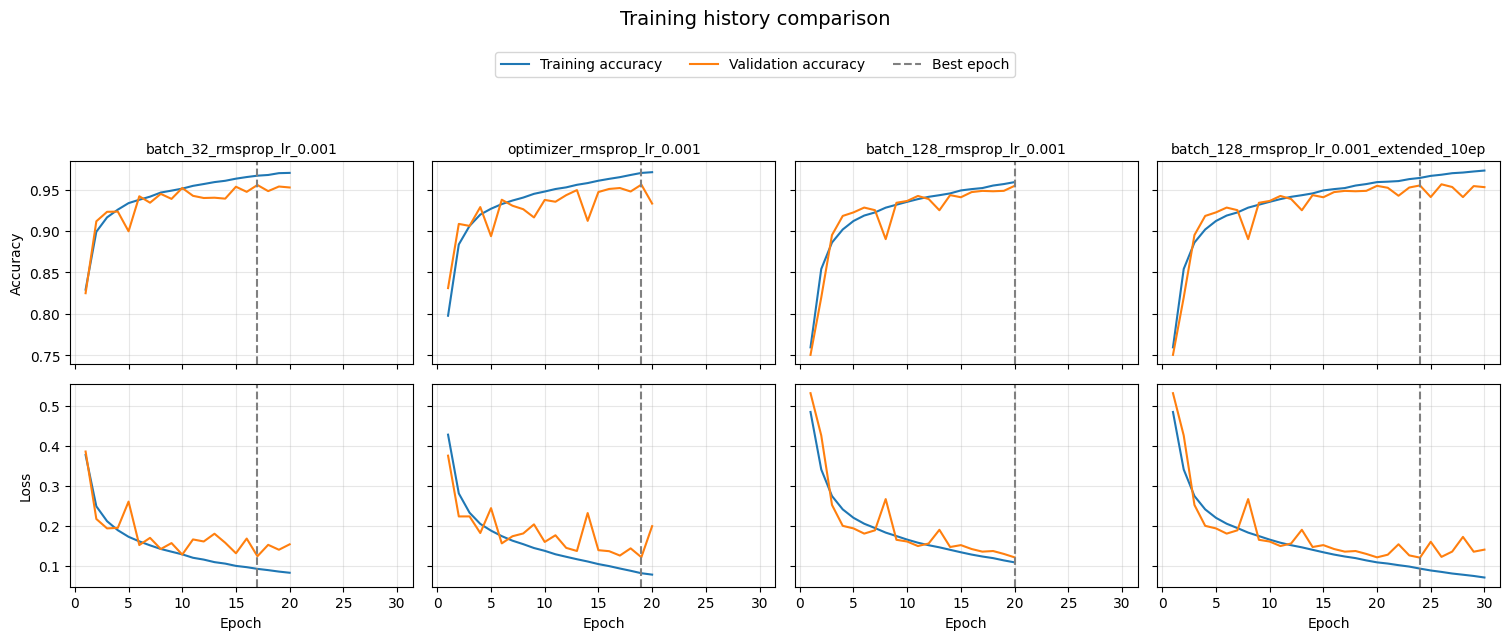

In [34]:
batch_extended_experiments = [
    "batch_32_rmsprop_lr_0.001",
    "optimizer_rmsprop_lr_0.001",
    BATCH128_BASE_EXPERIMENT,
    BATCH128_EXTENDED_EXPERIMENT
]

batch_extended_results = get_results_table(
    batch_extended_experiments
)

display(
    batch_extended_results[
        [
            "experiment",
            "val_loss",
            "val_accuracy",
            "val_precision",
            "val_recall",
            "val_f1_real",
            "val_macro_f1",
            "best_epoch",
            "parameters",
            "training_seconds"
        ]
    ]
)

# Comparación de las curvas
plot_training_history(batch_extended_experiments)

La continuación del entrenamiento con batch 128 durante otras 10 épocas adicionales permitió mejorar ligeramente la pérdida de validación, que pasó de 0.1205 a 0.1198, y la puntuación Macro F1, que aumentó del 95.44 % al 95.50 %. Sin embargo, la mejora en accuracy fue muy reducida. El mejor resultado se alcanzó en la época 24, a partir de la cual la pérdida de validación comenzó a presentar oscilaciones sin una tendencia clara de mejora, mientras que la pérdida de entrenamiento continuó disminuyendo. Este comportamiento sugiere que la capacidad de generalización del modelo comienza a estabilizarse y que prolongar todavía más el entrenamiento no proporcionaría necesariamente mejoras significativas.

En cuanto al coste computacional, batch size 128 requiere aproximadamente 636 segundos para las primeras 20 épocas y 968 segundos considerando la continuación de 10 épocas adicionales. Este último valor supone un incremento aproximado del 38 % respecto al entrenamiento de batch size 64, sin conseguir superar sus métricas globales de clasificación. Por otra parte, batch size 32 requiere aproximadamente 793 segundos, un 13 % más que batch size 64, a pesar de proporcionar resultados muy similares.

En conjunto, **batch size 64 proporciona el mejor equilibrio entre rendimiento predictivo, estabilidad del aprendizaje y coste computacional**. Aunque batch size 128 consigue una pérdida de validación ligeramente inferior tras prolongar el entrenamiento, no proporciona una mejora significativa en las métricas de clasificación que justifique su mayor coste computacional.

En consecuencia, se selecciona **un tamaño de batch de 64 imágenes** para los siguientes experimentos, manteniendo RMSprop con una tasa de aprendizaje de 0.001 y un máximo de 20 épocas de entrenamiento.

Se actualiza la configuración de referencia para los próximos experimentos.

In [35]:
REFERENCE_CONFIG.update({
    "optimizer_name": "rmsprop",
    "learning_rate": 0.001,
    "momentum": 0.9,
    "activation": "relu",
    "dropout_rate": 0.0,
    "l2_strength": 0.0,
    "batch_normalization": False
})

REFERENCE_BATCH_SIZE = 64
REFERENCE_EPOCHS = 20

print(REFERENCE_CONFIG)

{'num_conv_blocks': 3, 'num_dense_layers': 1, 'spatial_reduction': 'gap', 'activation': 'relu', 'optimizer_name': 'rmsprop', 'learning_rate': 0.001, 'momentum': 0.9, 'dropout_rate': 0.0, 'l2_strength': 0.0, 'batch_normalization': False}


### 4.3.3. Función de activación

Las funciones de activación introducen no linealidad en las redes neuronales, permitiendo aprender relaciones complejas entre las características de entrada y la variable objetivo. Su elección influye en la propagación de los gradientes, la velocidad de convergencia y el comportamiento del modelo durante el entrenamiento.

En los experimentos anteriores se ha utilizado ReLU como función de activación en las capas ocultas de la red. En esta etapa se estudiará el efecto de utilizar diferentes alternativas, comparando ReLU, LeakyReLU, ELU, Tanh y Sigmoide. Estas funciones presentan propiedades diferentes. Mientras que ReLU y sus variantes permiten mantener gradientes relativamente elevados en determinadas regiones de entrada, Tanh y Sigmoid presentan comportamientos saturantes que pueden dificultar la propagación del gradiente cuando sus entradas alcanzan valores extremos.

El objetivo de este experimento es comprobar cómo afectan estas diferencias al aprendizaje de nuestra CNN y determinar qué función proporciona mejores resultados de validación.

Para realizar una comparación controlada, se mantendrán constantes la arquitectura, el optimizador, la tasa de aprendizaje, el tamaño de batch y el número de épocas. La función de activación seleccionada se aplicará de forma uniforme a las capas convolucionales y densas ocultas. La activación de salida se mantendrá como Sigmoide en todos los modelos, al tratarse de un problema de clasificación binaria.

Para realizar la comparación se plantean cinco configuraciones:

| Experimento | Función de activación |
|:---|:---|
| CNN-ReLU | ReLU |
| CNN-LeakyReLU | LeakyReLU |
| CNN-ELU | ELU |
| CNN-Tanh | Tanh |
| CNN-Sigmoid | Sigmoide |

En el caso de LeakyReLU se utilizará un coeficiente de pendiente negativa de 0.1, mientras que para el resto de las funciones se emplearán sus implementaciones estándar de TensorFlow/Keras.

Se utilizará como punto de partida la configuración seleccionada en los experimentos anteriores:

| Parámetro | Configuración |
|---|---|
| Arquitectura | Conv3 + Dense1 + GAP |
| Optimizador | RMSprop |
| Learning rate | 0.001 |
| Batch size | 64 |
| Épocas | 20 |
| Función de pérdida | Binary Crossentropy |
| Regularización adicional | Desactivada |

El experimento con ReLU ya ha sido realizado durante la evaluación de los optimizadores y las tasas de aprendizaje, utilizando RMSprop con una tasa de aprendizaje de 0.001. Por tanto, se reutilizarán sus resultados como referencia y únicamente será necesario entrenar las cuatro configuraciones restantes.

La comparación se realizará utilizando las métricas de validación y las curvas de aprendizaje, prestando especial atención a la convergencia, la estabilidad del entrenamiento y la posible aparición de sobreajuste.

In [36]:
# Modelo ReLU ya entrenado durante 20 épocas
BASE_ACTIVATION_EXPERIMENT = "optimizer_rmsprop_lr_0.001"

# Recuperar la configuración utilizada
activation_base_config = experiment_configs[BASE_ACTIVATION_EXPERIMENT].copy()

# Comprobar la configuración de referencia
print("Configuración de referencia:")
print(activation_base_config)

# Funciones de activación a comparar
activation_candidates = [
    "relu",
    "leaky_relu",
    "elu",
    "tanh",
    "sigmoid"
]

# Reutilizar los resultados del modelo ReLU
activation_experiments = [BASE_ACTIVATION_EXPERIMENT]

for activation in activation_candidates:

    # ReLU ya está entrenado: no repetir
    if activation == "relu":
        continue

    experiment_name = f"activation_{activation}"

    # Recuperar configuración de referencia
    config = activation_base_config.copy()

    # Modificar exclusivamente la activación oculta
    config["activation"] = activation

    # Entrenamiento
    run_experiment(
        experiment_name=experiment_name,
        model_config=config,
        batch_size=REFERENCE_BATCH_SIZE,
        epochs=REFERENCE_EPOCHS
    )

    activation_experiments.append(experiment_name)

Configuración de referencia:
{'num_conv_blocks': 3, 'num_dense_layers': 1, 'spatial_reduction': 'gap', 'activation': 'relu', 'optimizer_name': 'rmsprop', 'learning_rate': 0.001, 'momentum': 0.9}

EXPERIMENTO: activation_leaky_relu
CONFIGURACIÓN: {'num_conv_blocks': 3, 'num_dense_layers': 1, 'spatial_reduction': 'gap', 'activation': 'leaky_relu', 'optimizer_name': 'rmsprop', 'learning_rate': 0.001, 'momentum': 0.9}
BATCH SIZE: 64
Epoch 1/20


c:\Users\angel\AppData\Local\Programs\Python\Python314\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


1234/1234 - 41s - 34ms/step - accuracy: 0.8047 - f1_real: 0.8106 - loss: 0.4149 - precision: 0.7964 - recall: 0.8254 - val_accuracy: 0.8342 - val_f1_real: 0.8558 - val_loss: 0.3720 - val_precision: 0.7648 - val_recall: 0.9715
Epoch 2/20
1234/1234 - 35s - 28ms/step - accuracy: 0.8888 - f1_real: 0.8904 - loss: 0.2670 - precision: 0.8893 - recall: 0.8914 - val_accuracy: 0.9092 - val_f1_real: 0.9133 - val_loss: 0.2224 - val_precision: 0.8840 - val_recall: 0.9446
Epoch 3/20
1234/1234 - 35s - 29ms/step - accuracy: 0.9089 - f1_real: 0.9102 - loss: 0.2272 - precision: 0.9091 - recall: 0.9112 - val_accuracy: 0.9119 - val_f1_real: 0.9169 - val_loss: 0.2204 - val_precision: 0.8781 - val_recall: 0.9593
Epoch 4/20
1234/1234 - 35s - 28ms/step - accuracy: 0.9200 - f1_real: 0.9211 - loss: 0.2016 - precision: 0.9205 - recall: 0.9217 - val_accuracy: 0.9301 - val_f1_real: 0.9313 - val_loss: 0.1767 - val_precision: 0.9275 - val_recall: 0.9352
Epoch 5/20
1234/1234 - 35s - 29ms/step - accuracy: 0.9275 - f1_

c:\Users\angel\AppData\Local\Programs\Python\Python314\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


1234/1234 - 40s - 32ms/step - accuracy: 0.8090 - f1_real: 0.8140 - loss: 0.4119 - precision: 0.8032 - recall: 0.8252 - val_accuracy: 0.8259 - val_f1_real: 0.8482 - val_loss: 0.3834 - val_precision: 0.7597 - val_recall: 0.9600
Epoch 2/20
1234/1234 - 38s - 31ms/step - accuracy: 0.8809 - f1_real: 0.8826 - loss: 0.2845 - precision: 0.8818 - recall: 0.8834 - val_accuracy: 0.9044 - val_f1_real: 0.9082 - val_loss: 0.2283 - val_precision: 0.8842 - val_recall: 0.9335
Epoch 3/20
1234/1234 - 38s - 31ms/step - accuracy: 0.9043 - f1_real: 0.9054 - loss: 0.2365 - precision: 0.9062 - recall: 0.9047 - val_accuracy: 0.9136 - val_f1_real: 0.9169 - val_loss: 0.2108 - val_precision: 0.8938 - val_recall: 0.9412
Epoch 4/20
1234/1234 - 38s - 31ms/step - accuracy: 0.9165 - f1_real: 0.9174 - loss: 0.2078 - precision: 0.9197 - recall: 0.9151 - val_accuracy: 0.9229 - val_f1_real: 0.9217 - val_loss: 0.1976 - val_precision: 0.9492 - val_recall: 0.8957
Epoch 5/20
1234/1234 - 38s - 31ms/step - accuracy: 0.9238 - f1_

c:\Users\angel\AppData\Local\Programs\Python\Python314\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


1234/1234 - 36s - 29ms/step - accuracy: 0.8034 - f1_real: 0.8071 - loss: 0.4183 - precision: 0.8024 - recall: 0.8120 - val_accuracy: 0.8556 - val_f1_real: 0.8632 - val_loss: 0.3390 - val_precision: 0.8298 - val_recall: 0.8994
Epoch 2/20
1234/1234 - 34s - 28ms/step - accuracy: 0.8776 - f1_real: 0.8793 - loss: 0.2913 - precision: 0.8785 - recall: 0.8801 - val_accuracy: 0.9025 - val_f1_real: 0.9069 - val_loss: 0.2378 - val_precision: 0.8783 - val_recall: 0.9374
Epoch 3/20
1234/1234 - 34s - 28ms/step - accuracy: 0.8999 - f1_real: 0.9013 - loss: 0.2463 - precision: 0.9004 - recall: 0.9021 - val_accuracy: 0.8927 - val_f1_real: 0.9002 - val_loss: 0.2488 - val_precision: 0.8511 - val_recall: 0.9552
Epoch 4/20
1234/1234 - 34s - 28ms/step - accuracy: 0.9117 - f1_real: 0.9129 - loss: 0.2184 - precision: 0.9122 - recall: 0.9137 - val_accuracy: 0.9253 - val_f1_real: 0.9270 - val_loss: 0.1883 - val_precision: 0.9173 - val_recall: 0.9370
Epoch 5/20
1234/1234 - 35s - 28ms/step - accuracy: 0.9195 - f1_

c:\Users\angel\AppData\Local\Programs\Python\Python314\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


1234/1234 - 37s - 30ms/step - accuracy: 0.5020 - f1_real: 0.5361 - loss: 0.6961 - precision: 0.5076 - recall: 0.5679 - val_accuracy: 0.5066 - val_f1_real: 0.6725 - val_loss: 0.6957 - val_precision: 0.5066 - val_recall: 1.0000
Epoch 2/20
1234/1234 - 35s - 29ms/step - accuracy: 0.5018 - f1_real: 0.5454 - loss: 0.6946 - precision: 0.5071 - recall: 0.5899 - val_accuracy: 0.5066 - val_f1_real: 0.6725 - val_loss: 0.6941 - val_precision: 0.5066 - val_recall: 1.0000
Epoch 3/20
1234/1234 - 35s - 28ms/step - accuracy: 0.5779 - f1_real: 0.5707 - loss: 0.6715 - precision: 0.5887 - recall: 0.5538 - val_accuracy: 0.5873 - val_f1_real: 0.5905 - val_loss: 0.6543 - val_precision: 0.5937 - val_recall: 0.5873
Epoch 4/20
1234/1234 - 35s - 28ms/step - accuracy: 0.6032 - f1_real: 0.5533 - loss: 0.6476 - precision: 0.6439 - recall: 0.4850 - val_accuracy: 0.5900 - val_f1_real: 0.6150 - val_loss: 0.6468 - val_precision: 0.5865 - val_recall: 0.6463
Epoch 5/20
1234/1234 - 35s - 28ms/step - accuracy: 0.6319 - f1_

Una vez completados los entrenamientos, se recopilan las métricas obtenidas para cada función de activación. Se analizarán la pérdida de validación, la accuracy, la precision, el recall y las puntuaciones F1, junto con el número de parámetros y el tiempo de entrenamiento. Además, se representarán las curvas de aprendizaje para estudiar las diferencias en la evolución de las métricas de entrenamiento y validación.

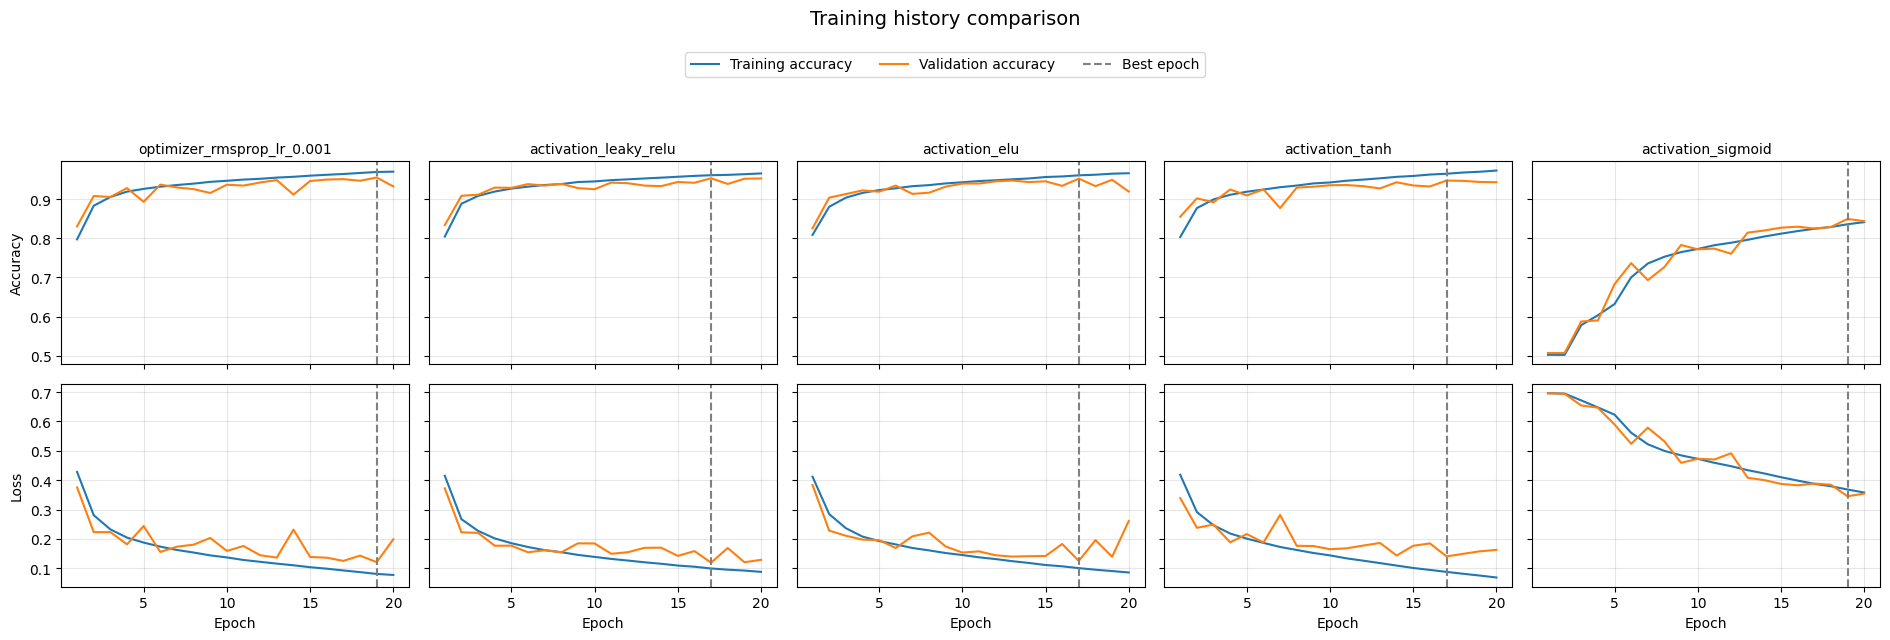

In [37]:
plot_training_history(activation_experiments)

In [38]:
activation_results = get_results_table(activation_experiments)

display(
    activation_results[
        [
            "experiment",
            "val_loss",
            "val_accuracy",
            "val_precision",
            "val_recall",
            "val_f1_real",
            "val_macro_f1",
            "best_epoch",
            "parameters",
            "training_seconds"
        ]
    ]
)

,experiment,val_loss,val_accuracy,val_precision,val_recall,val_f1_real,val_macro_f1,best_epoch,parameters,training_seconds
0,activation_leaky_relu,0.119023,0.954053,0.960219,0.9486,0.954374,0.954050,17,109889,712.403263
1,optimizer_rmsprop_lr_0.001,0.120787,0.955927,0.961951,0.9506,0.956242,0.955925,19,109889,701.787476
2,activation_elu,0.124934,0.953141,0.948857,0.9592,0.954001,0.953124,17,109889,768.422945
3,activation_tanh,0.140334,0.948176,0.944802,0.9534,0.949082,0.948160,17,109889,687.928198
4,activation_sigmoid,0.345196,0.849848,0.838464,0.8715,0.854663,0.849683,19,109889,703.535353


Los resultados muestran que **ReLU y Leaky ReLU proporcionan el mejor rendimiento global**, con valores de accuracy y Macro F1 superiores al 95 %. ReLU obtiene una accuracy del 95.59 % y un Macro F1 del 95.59 %, mientras que Leaky ReLU alcanza un 95.41 % en ambas métricas. Aunque Leaky ReLU consigue la menor pérdida de validación (0.1190 frente a 0.1208), ReLU presenta mejores resultados en las principales métricas de clasificación, incluyendo precisión, recall y F1-REAL.

ELU proporciona resultados próximos a los de ReLU y Leaky ReLU, con una accuracy del 95.31 % y un Macro F1 del 95.31 %. Destaca especialmente por conseguir el mayor recall de los experimentos (95.92 %), aunque su precisión es inferior (94.89 %). Por su parte, tanh presenta un rendimiento algo más limitado, con una accuracy del 94.82 % y un Macro F1 del 94.82 %. Finalmente, sigmoid obtiene resultados considerablemente inferiores, con una accuracy del 84.98 % y un Macro F1 del 84.97 %.

La evolución de las curvas de entrenamiento y validación permite complementar esta comparación. ReLU y Leaky ReLU presentan una evolución favorable, alcanzando accuracies de validación próximas al 95-96 %. En ambos casos, las métricas de entrenamiento continúan mejorando durante el proceso, mientras que las de validación presentan algunas fluctuaciones. Los mejores resultados se alcanzan en las épocas 19 y 17, respectivamente. Aunque se aprecia cierta separación entre las curvas, no se observa un sobreajuste especialmente pronunciado durante la mayor parte del entrenamiento.

ELU y tanh también muestran una evolución favorable durante las primeras épocas, pero sus métricas de validación dejan de mejorar alrededor de la época 17. A partir de ese momento, mientras la pérdida de entrenamiento continúa disminuyendo, la pérdida de validación presenta fluctuaciones y una tendencia creciente. Este comportamiento sugiere la aparición de cierto sobreajuste o una pérdida de capacidad de generalización al prolongar el entrenamiento.

El comportamiento de sigmoide es diferente. Tanto la accuracy de entrenamiento como la de validación siguen aumentando progresivamente, mientras que ambas pérdidas continúan disminuyendo. Además, las curvas de entrenamiento y validación permanecen próximas, sin mostrar una divergencia significativa que indique sobreajuste. El mejor resultado de validación se alcanza en la época 19, y la evolución de las curvas sugiere que el modelo todavía podría beneficiarse de un entrenamiento más prolongado. No obstante, su rendimiento sigue estando considerablemente por debajo del resto de las activaciones, por lo que alcanzar resultados competitivos podría requerir un proceso de entrenamiento más largo.

El comportamiento de sigmoide también puede relacionarse con sus propiedades matemáticas. Su salida está acotada entre 0 y 1 y sus gradientes pueden volverse muy pequeños cuando la entrada se encuentra en las regiones de saturación. Esto puede dificultar la propagación del gradiente a través de las capas de la red y ralentizar el aprendizaje, especialmente cuando se utiliza repetidamente en las capas ocultas.

En conjunto, los resultados respaldan la utilización de ReLU como función de activación en las capas ocultas de la CNN. Aunque Leaky ReLU consigue una pérdida de validación ligeramente inferior y ELU presenta un recall más elevado, ReLU proporciona los mejores resultados globales en accuracy, precisión, F1-REAL y Macro F1. Por tanto, **se mantiene ReLU como función de activación para los siguientes experimentos**.

Es importante mencionar que se ha mantenido una tasa de aprendizaje constante de 0.001 para todas las funciones de activación, con el objetivo de aislar el efecto de esta variable en el experimento. Sin embargo, cada función de activación puede responder mejor a diferentes valores de learning rate. Por tanto, los resultados reflejan el rendimiento de cada activación bajo las mismas condiciones de optimización, pero no necesariamente el mejor rendimiento que podría alcanzar cada una tras ajustar individualmente su tasa de aprendizaje.

## 4.4. Regularización

Una vez seleccionadas la arquitectura y las principales configuraciones de entrenamiento de la CNN, se estudia el efecto de diferentes técnicas de regularización y normalización sobre su capacidad de generalización.

El modelo de referencia presenta un rendimiento elevado sobre el conjunto de validación, aunque las curvas de entrenamiento muestran cierta separación respecto a las de validación. En particular, la pérdida de entrenamiento continúa disminuyendo mientras que la pérdida de validación presenta fluctuaciones y una tendencia de mejora más limitada. Este comportamiento sugiere que existe cierto margen para estudiar si la introducción de técnicas de regularización permite mejorar la generalización del modelo.

Para estudiar este efecto se evaluarán tres técnicas: **regularización L2, Dropout y Batch Normalization**. Cada técnica se introducirá inicialmente de forma independiente, manteniendo constantes el resto de los parámetros experimentales. De esta manera, será posible analizar el efecto individual de cada una y determinar cuáles proporcionan una mejora respecto al modelo de referencia.

Se utilizará como punto de partida la arquitectura seleccionada en los experimentos anteriores, formada por tres bloques convolucionales, una capa densa oculta y Global Average Pooling. Asimismo, se mantendrán la función de activación ReLU, el optimizador RMSprop, una tasa de aprendizaje de 0.001 y un tamaño de batch de 64 imágenes. Cada modelo se entrenará durante un máximo de 20 épocas.

El modelo sin regularización previamente entrenado servirá como referencia para comparar los resultados, por lo que no será necesario repetir su entrenamiento.

### 4.4.1. Configuración de los experimentos

Se plantean los siguientes experimentos:

| Experimento | Técnica | Configuración |
|---|---|---|
| Referencia | Sin regularización | Dropout = 0, L2 = 0, Batch Normalization desactivado |
| L2 | Regularización L2 | Coeficiente L2 = 0.0001 |
| Dropout | Dropout | Tasa de Dropout = 0.3 |
| Batch Normalization | Batch Normalization | Activada en las capas ocultas |

**Weight regularization (L2).** Esta técnica incorpora un término de penalización a la función de pérdida, proporcional a la suma de los cuadrados de los pesos de la red. Su objetivo es penalizar valores elevados de los parámetros y limitar la complejidad del modelo, favoreciendo soluciones menos dependientes de determinados pesos. Se comenzará utilizando un coeficiente de regularización de 0.0001.

**Dropout.** Consiste en desactivar aleatoriamente una proporción de neuronas durante cada iteración del entrenamiento. Esto dificulta que la red desarrolle dependencias excesivas entre neuronas concretas y favorece el aprendizaje de representaciones más robustas. Se utilizará inicialmente una tasa de Dropout de 0.3, aplicada después de la activación de la capa densa oculta.

**Batch Normalization.** Normaliza las activaciones de las capas utilizando estadísticas calculadas a partir de los batches de entrenamiento. Su objetivo principal es estabilizar y facilitar el proceso de optimización, aunque las variaciones introducidas por las estadísticas de cada batch también pueden aportar cierto efecto regularizador. Se activará en las capas convolucionales y densas ocultas, situando la normalización antes de la función de activación.

Todas las pruebas utilizarán las mismas particiones de entrenamiento y validación, así como las mismas condiciones de optimización. Se mantendrán desactivadas las técnicas de regularización que no correspondan al experimento en curso.

A continuación se define la configuración de cada uno de los experimentos.

In [39]:
# Experimento de referencia ya entrenado
BASE_REGULARIZATION_EXPERIMENT = "optimizer_rmsprop_lr_0.001"

# Recuperamos su configuración
regularization_base_config = experiment_configs[BASE_REGULARIZATION_EXPERIMENT].copy()

# Comprobamos las condiciones experimentales
print("Configuración del modelo de referencia:")
print(regularization_base_config)

# Fijamos explícitamente las condiciones comunes
regularization_base_config.update({
    "activation": "relu",
    "dropout_rate": 0.0,
    "l2_strength": 0.0,
    "batch_normalization": False
})

# Lista de experimentos para las comparaciones
regularization_experiments = [BASE_REGULARIZATION_EXPERIMENT]

Configuración del modelo de referencia:
{'num_conv_blocks': 3, 'num_dense_layers': 1, 'spatial_reduction': 'gap', 'activation': 'relu', 'optimizer_name': 'rmsprop', 'learning_rate': 0.001, 'momentum': 0.9}


### 4.4.2. Ejecución y análisis de los experimentos

A continuación se lanza la batería de experimentos descrita en la sección anterior.

In [40]:
# Configuraciones específicas de cada técnica
regularization_candidates = {
    "regularization_l2_1e-4": {
        "l2_strength": 1e-4
    },
    "regularization_dropout_0.3": {
        "dropout_rate": 0.3
    },
    "regularization_batch_norm": {
        "batch_normalization": True
    }
}

# Condiciones comunes de entrenamiento
REGULARIZATION_BATCH_SIZE = REFERENCE_BATCH_SIZE
REGULARIZATION_EPOCHS = REFERENCE_EPOCHS

# Entrenamos cada variante desde cero
for experiment_name, overrides in regularization_candidates.items():

    print(f"\n{'=' * 60}")
    print(f"Ejecutando experimento: {experiment_name}")
    print(f"{'=' * 60}")

    # Partimos siempre de la misma configuración de referencia
    model_config = regularization_base_config.copy()

    # Aplicamos únicamente la técnica correspondiente
    model_config.update(overrides)

    # Entrenamiento del modelo
    run_experiment(
        experiment_name=experiment_name,
        model_config=model_config,
        batch_size=REGULARIZATION_BATCH_SIZE,
        epochs=REGULARIZATION_EPOCHS
    )

    regularization_experiments.append(experiment_name)


Ejecutando experimento: regularization_l2_1e-4

EXPERIMENTO: regularization_l2_1e-4
CONFIGURACIÓN: {'num_conv_blocks': 3, 'num_dense_layers': 1, 'spatial_reduction': 'gap', 'activation': 'relu', 'optimizer_name': 'rmsprop', 'learning_rate': 0.001, 'momentum': 0.9, 'dropout_rate': 0.0, 'l2_strength': 0.0001, 'batch_normalization': False}
BATCH SIZE: 64
Epoch 1/20


c:\Users\angel\AppData\Local\Programs\Python\Python314\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


1234/1234 - 39s - 32ms/step - accuracy: 0.7919 - f1_real: 0.7992 - loss: 0.4582 - precision: 0.7817 - recall: 0.8176 - val_accuracy: 0.8197 - val_f1_real: 0.8443 - val_loss: 0.4214 - val_precision: 0.7502 - val_recall: 0.9654
Epoch 2/20
1234/1234 - 34s - 27ms/step - accuracy: 0.8773 - f1_real: 0.8790 - loss: 0.3167 - precision: 0.8784 - recall: 0.8795 - val_accuracy: 0.9045 - val_f1_real: 0.9079 - val_loss: 0.2590 - val_precision: 0.8876 - val_recall: 0.9292
Epoch 3/20
1234/1234 - 34s - 27ms/step - accuracy: 0.8984 - f1_real: 0.8998 - loss: 0.2745 - precision: 0.8987 - recall: 0.9009 - val_accuracy: 0.8943 - val_f1_real: 0.9025 - val_loss: 0.2775 - val_precision: 0.8473 - val_recall: 0.9653
Epoch 4/20
1234/1234 - 34s - 28ms/step - accuracy: 0.9107 - f1_real: 0.9120 - loss: 0.2511 - precision: 0.9107 - recall: 0.9134 - val_accuracy: 0.9259 - val_f1_real: 0.9268 - val_loss: 0.2153 - val_precision: 0.9271 - val_recall: 0.9265
Epoch 5/20
1234/1234 - 34s - 27ms/step - accuracy: 0.9177 - f1_

c:\Users\angel\AppData\Local\Programs\Python\Python314\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


1234/1234 - 35s - 28ms/step - accuracy: 0.8002 - f1_real: 0.8061 - loss: 0.4251 - precision: 0.7927 - recall: 0.8199 - val_accuracy: 0.8553 - val_f1_real: 0.8693 - val_loss: 0.3378 - val_precision: 0.8013 - val_recall: 0.9499
Epoch 2/20
1234/1234 - 34s - 27ms/step - accuracy: 0.8849 - f1_real: 0.8861 - loss: 0.2777 - precision: 0.8881 - recall: 0.8841 - val_accuracy: 0.8972 - val_f1_real: 0.8973 - val_loss: 0.2405 - val_precision: 0.9087 - val_recall: 0.8861
Epoch 3/20
1234/1234 - 34s - 28ms/step - accuracy: 0.9074 - f1_real: 0.9086 - loss: 0.2316 - precision: 0.9084 - recall: 0.9089 - val_accuracy: 0.9178 - val_f1_real: 0.9186 - val_loss: 0.2014 - val_precision: 0.9216 - val_recall: 0.9156
Epoch 4/20
1234/1234 - 34s - 27ms/step - accuracy: 0.9201 - f1_real: 0.9210 - loss: 0.2040 - precision: 0.9218 - recall: 0.9203 - val_accuracy: 0.9306 - val_f1_real: 0.9323 - val_loss: 0.1762 - val_precision: 0.9221 - val_recall: 0.9428
Epoch 5/20
1234/1234 - 34s - 27ms/step - accuracy: 0.9270 - f1_

c:\Users\angel\AppData\Local\Programs\Python\Python314\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


1234/1234 - 61s - 49ms/step - accuracy: 0.8986 - f1_real: 0.9001 - loss: 0.2439 - precision: 0.8980 - recall: 0.9024 - val_accuracy: 0.7917 - val_f1_real: 0.8285 - val_loss: 0.5077 - val_precision: 0.7106 - val_recall: 0.9933
Epoch 2/20
1234/1234 - 59s - 47ms/step - accuracy: 0.9306 - f1_real: 0.9315 - loss: 0.1777 - precision: 0.9309 - recall: 0.9321 - val_accuracy: 0.8711 - val_f1_real: 0.8562 - val_loss: 0.3148 - val_precision: 0.9847 - val_recall: 0.7574
Epoch 3/20
1234/1234 - 58s - 47ms/step - accuracy: 0.9399 - f1_real: 0.9406 - loss: 0.1532 - precision: 0.9414 - recall: 0.9398 - val_accuracy: 0.9108 - val_f1_real: 0.9074 - val_loss: 0.2457 - val_precision: 0.9574 - val_recall: 0.8624
Epoch 4/20
1234/1234 - 58s - 47ms/step - accuracy: 0.9470 - f1_real: 0.9476 - loss: 0.1384 - precision: 0.9484 - recall: 0.9469 - val_accuracy: 0.8137 - val_f1_real: 0.8441 - val_loss: 0.5884 - val_precision: 0.7325 - val_recall: 0.9960
Epoch 5/20
1234/1234 - 58s - 47ms/step - accuracy: 0.9504 - f1_

Una vez finalizados los entrenamientos, se comparan los resultados obtenidos con las tres técnicas de regularización frente al modelo de referencia sin regularización.

Se analizarán tanto las métricas finales de validación como la evolución de las curvas de entrenamiento. Además del rendimiento predictivo, se prestará especial atención a la diferencia entre las métricas de entrenamiento y validación, ya que permite identificar si las técnicas evaluadas consiguen reducir el sobreajuste.

La selección de la configuración más adecuada no dependerá únicamente de la accuracy. Se tendrán en cuenta conjuntamente la pérdida de validación, el Macro F1 y el F1 de la clase REAL, así como la estabilidad de las curvas y el coste computacional.

Es importante tener en cuenta algunas particularidades al interpretar los resultados:

- En el experimento con L2, la pérdida calculada por Keras incluye el término de penalización asociado a los pesos de la red. Por tanto, su valor de val_loss no es directamente equivalente al del modelo sin regularización, ya que incorpora un término adicional. Para comparar la capacidad predictiva de ambos modelos también se tendrán en cuenta accuracy, precisión, recall y F1.
- En el experimento con Dropout, las neuronas se desactivan aleatoriamente durante el entrenamiento, pero todas permanecen activas durante la evaluación y la predicción. Por este motivo, es normal que las métricas de entrenamiento y validación presenten diferencias respecto al modelo de referencia.
- Batch Normalization introduce parámetros adicionales en las capas donde se aplica y utiliza un comportamiento diferente durante entrenamiento y evaluación. Por tanto, se analizará tanto su efecto sobre el rendimiento como su influencia en el proceso de convergencia.

Los resultados de esta primera batería permitirán determinar qué técnicas ofrecen una mejora individual respecto al modelo de referencia. En función de las conclusiones obtenidas, se seleccionarán las alternativas más prometedoras para estudiar posteriormente el efecto de combinar diferentes técnicas de regularización.

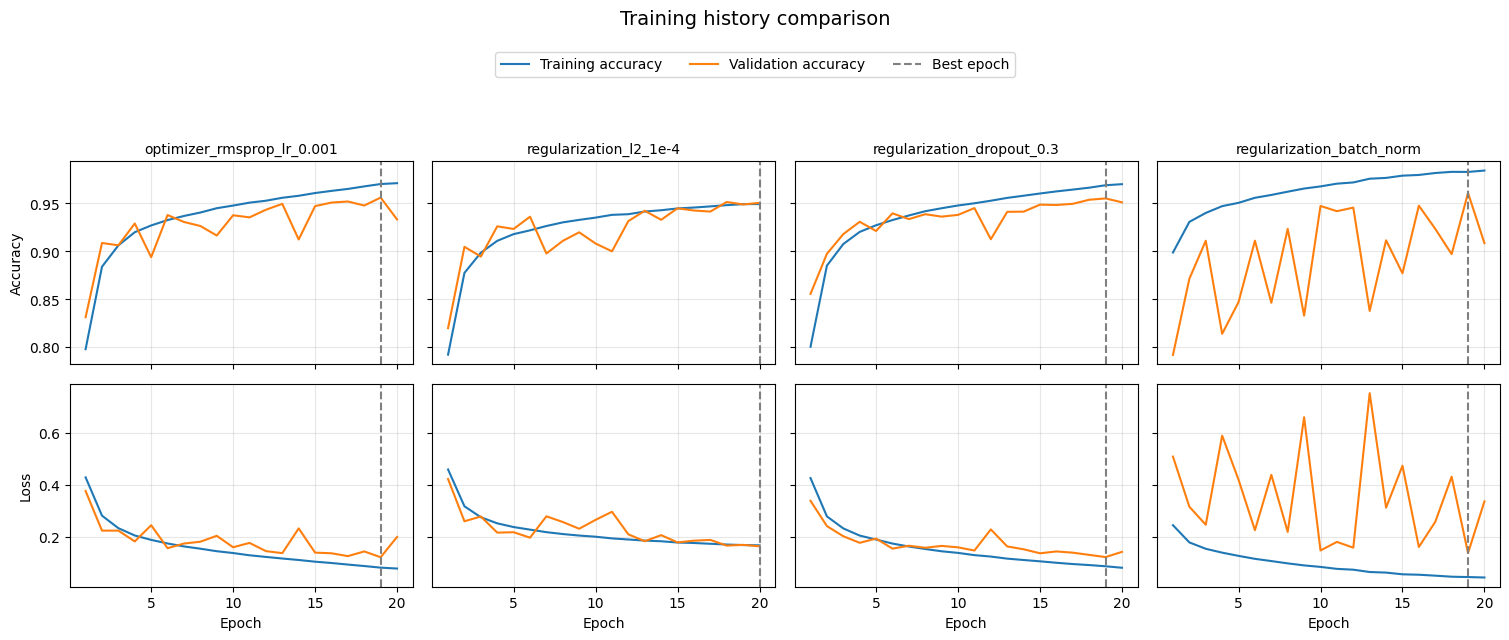

In [41]:
# Evolución de accuracy y loss durante el entrenamiento
plot_training_history(regularization_experiments)

In [42]:
# Generamos la tabla de resultados
regularization_results = get_results_table(regularization_experiments)

# Columnas de interés
regularization_columns = [
    "experiment",
    "val_loss",
    "val_accuracy",
    "val_precision",
    "val_recall",
    "val_f1_real",
    "val_macro_f1",
    "best_epoch",
    "parameters",
    "training_seconds"
]

# Ordenamos por Macro F1 para facilitar la comparación global
display(
    regularization_results[regularization_columns]
    .sort_values("val_macro_f1", ascending=False)
    .reset_index(drop=True)
)

,experiment,val_loss,val_accuracy,val_precision,val_recall,val_f1_real,val_macro_f1,best_epoch,parameters,training_seconds
0,regularization_batch_norm,0.136980,0.960740,0.970136,0.9518,0.960880,0.960739,19,110945,1170.759125
1,optimizer_rmsprop_lr_0.001,0.120787,0.955927,0.961951,0.9506,0.956242,0.955925,19,109889,701.787476
2,regularization_dropout_0.3,0.121261,0.955015,0.966995,0.9434,0.955052,0.955015,19,109889,678.962395
3,regularization_l2_1e-4,0.162787,0.950405,0.949477,0.9528,0.951136,0.950394,20,109889,681.888878


Los resultados obtenidos muestran diferencias relevantes entre las técnicas de regularización evaluadas.

La CNN sin regularización obtiene una accuracy del 95.59 % y un Macro F1 del 95.59 %. La regularización L2 proporciona resultados inferiores, con una accuracy del 95.04 % y un Macro F1 del 95.04 %. Aunque su recall aumenta ligeramente respecto al modelo de referencia, este incremento no compensa la reducción observada en precisión y en las métricas globales de clasificación.

Dropout obtiene resultados muy próximos a los del modelo de referencia, con una accuracy del 95.50 % y un Macro F1 del 95.50 %. Destaca por alcanzar una precisión del 96.70 %, superior a la obtenida con las demás configuraciones, aunque presenta un recall más reducido (94.34 %). Esto indica que la técnica favorece un comportamiento más conservador en la clasificación de imágenes como REAL, pero no consigue mejorar el equilibrio global entre ambas clases.

Por su parte, Batch Normalization proporciona los mejores resultados de clasificación, alcanzando una accuracy del 96.07 %, una precisión del 97.01 % y un Macro F1 del 96.07 %. Estas cifras representan una mejora considerable en accuracy y Macro F1 respecto al modelo de referencia. Sin embargo, su pérdida de validación es superior (0.1370 frente a 0.1208), lo que indica que las predicciones presentan un comportamiento diferente en términos de confianza, a pesar de conseguir mejores resultados al aplicar el umbral de clasificación.

El análisis de las curvas de aprendizaje permite identificar diferencias adicionales entre las configuraciones. El modelo de referencia presenta una evolución relativamente estable, aunque mantiene cierta separación entre las métricas de entrenamiento y validación. L2 y Dropout muestran comportamientos también relativamente estables, pero no consiguen reducir de forma significativa esta separación ni proporcionar una mejora clara de la generalización.

En cambio, Batch Normalization presenta una evolución especialmente irregular sobre el conjunto de validación. Mientras que las métricas de entrenamiento mejoran progresivamente, la accuracy y la pérdida de validación muestran oscilaciones pronunciadas durante buena parte del entrenamiento. Este comportamiento indica que, pese a obtener las mejores métricas finales de clasificación, el modelo presenta una mayor inestabilidad en su comportamiento sobre datos no utilizados durante el entrenamiento. Sería conveniente comprobar adicionalmente la evolución de las estadísticas móviles de las capas de normalización para determinar si pueden estar contribuyendo a esta inestabilidad.

En cuanto al coste computacional, Batch Normalization requiere aproximadamente 1170 segundos de entrenamiento, frente a los 701 segundos del modelo de referencia. Esto representa un incremento aproximado del 67 %, considerablemente superior al observado con L2 y Dropout, cuyos tiempos son similares al del modelo sin regularización.

En conjunto, los resultados muestran que L2 y Dropout no proporcionan una mejora significativa respecto al modelo de referencia bajo las configuraciones evaluadas. Batch Normalization, por el contrario, consigue mejorar las métricas globales de clasificación, aunque esta mejora viene acompañada de una pérdida de validación superior, una evolución mucho más irregular de las curvas y un coste computacional considerablemente mayor.

Por tanto, los resultados no permiten descartar Batch Normalization, ya que presenta el mejor rendimiento cuantitativo sobre validación. Sin embargo, su comportamiento durante el entrenamiento aconseja analizar con mayor detalle su estabilidad antes de adoptarla como configuración definitiva. Se mantiene provisionalmente la CNN sin regularización como referencia para las siguientes pruebas, sin descartar la posibilidad de incorporar Batch Normalization si se confirma que sus mejores resultados son consistentes.

### 4.4.3. Verificación del comportamiento de Batch Normalization

Los resultados anteriores muestran que Batch Normalization proporciona las mejores métricas de clasificación, pero presenta una evolución muy irregular de las métricas de validación durante el entrenamiento. Mientras que las métricas de entrenamiento mejoran progresivamente, la accuracy de validación y la pérdida muestran oscilaciones importantes.

Con el objetivo de investigar este comportamiento, se realizará un análisis adicional del modelo ya entrenado, sin repetir el proceso de entrenamiento.

En primer lugar, se comprobará la reproducibilidad de las predicciones sobre el conjunto de validación, realizando varias evaluaciones consecutivas con los mismos pesos y los mismos datos. De esta manera se podrá determinar si las fluctuaciones observadas durante el entrenamiento corresponden a una inestabilidad del proceso de aprendizaje o si también aparecen durante la evaluación de un modelo cuyo estado permanece fijo.

En segundo lugar, se inspeccionarán las estadísticas móviles de las capas Batch Normalization, concretamente la media y la varianza acumuladas durante el entrenamiento. Estas estadísticas se utilizan durante la evaluación y la inferencia del modelo, por lo que resulta importante comprobar que contienen valores válidos y que se han actualizado correctamente.

Finalmente, se compararán las predicciones de Batch Normalization con las del modelo de referencia sin regularización, utilizando las matrices de confusión y las métricas de clasificación por clase. Esto permitirá identificar si la mejora observada en las métricas globales se corresponde con una reducción efectiva de los errores de clasificación.

Primero reconstruimos ambas arquitecturas y recuperamos sus mejores pesos desde memoria.

In [43]:
# Identificadores de los experimentos
REFERENCE_EXPERIMENT = "optimizer_rmsprop_lr_0.001"
BN_EXPERIMENT = "regularization_batch_norm"

# Reiniciar el estado de Keras
tf.keras.backend.clear_session()

# Fijar la semilla
tf.keras.utils.set_random_seed(SEED)

# Recuperar configuración de referencia
reference_config = experiment_configs[
    REFERENCE_EXPERIMENT
].copy()

# Recuperar configuración de Batch Normalization
bn_config = experiment_configs[
    BN_EXPERIMENT
].copy()

# Reconstruir modelo de referencia
reference_model = build_cnn(**reference_config)

# Recuperar sus mejores pesos
reference_model.set_weights(
    experiment_best_weights[REFERENCE_EXPERIMENT]
)

# Reconstruir modelo con Batch Normalization
bn_model = build_cnn(**bn_config)

# Recuperar sus mejores pesos
bn_model.set_weights(
    experiment_best_weights[BN_EXPERIMENT]
)

print("Ambos modelos han sido reconstruidos correctamente.")
print("Parámetros modelo de referencia:",
      reference_model.count_params())
print("Parámetros modelo Batch Normalization:",
      bn_model.count_params())

Ambos modelos han sido reconstruidos correctamente.
Parámetros modelo de referencia: 109889
Parámetros modelo Batch Normalization: 110945


Se realizará una primera comprobación utilizando el modelo con Batch Normalization ya entrenado. Se calcularán sus predicciones sobre el conjunto de validación en dos ejecuciones independientes, manteniendo exactamente los mismos pesos y datos.

Durante la evaluación, las capas Batch Normalization utilizan las estadísticas móviles acumuladas durante el entrenamiento, sin actualizarlas. Por tanto, las predicciones deberían ser prácticamente idénticas en ambas ejecuciones.

Si se obtiene este comportamiento, podremos descartar que las fluctuaciones observadas en las curvas de validación sean consecuencia de una aleatoriedad introducida durante la evaluación de un modelo fijo.

In [44]:
# Preparar el conjunto de validación
val_batched = prepare_batched_dataset(val_ds, REFERENCE_BATCH_SIZE, AUTOTUNE)

# Primera evaluación
bn_predictions_1 = bn_model.predict(val_batched, verbose=0).reshape(-1)

# Segunda evaluación
bn_predictions_2 = bn_model.predict(val_batched, verbose=0).reshape(-1)

# Comparar las probabilidades
max_prediction_difference = np.max(np.abs(bn_predictions_1 - bn_predictions_2))

mean_prediction_difference = np.mean(np.abs(bn_predictions_1 - bn_predictions_2))

predictions_identical = np.allclose(bn_predictions_1, bn_predictions_2, atol=1e-7, rtol=1e-7)

print("Máxima diferencia entre predicciones:", max_prediction_difference)

print("Diferencia media entre predicciones:", mean_prediction_difference)

print("Predicciones reproducibles:", predictions_identical)

Máxima diferencia entre predicciones: 0.0
Diferencia media entre predicciones: 0.0
Predicciones reproducibles: True


Los resultados muestran una diferencia máxima y media entre las probabilidades predichas de 0, lo que confirma que ambas evaluaciones producen exactamente las mismas predicciones. Por tanto, el comportamiento irregular observado en las curvas de validación durante el entrenamiento no se debe a una aleatoriedad introducida durante la fase de evaluación del modelo.

Este resultado confirma que las predicciones son reproducibles cuando se utilizan los pesos y las estadísticas móviles de Batch Normalization ya entrenados. No obstante, todavía es necesario analizar dichas estadísticas para determinar si su comportamiento puede estar relacionado con las fluctuaciones observadas durante el entrenamiento.

Durante el entrenamiento, Batch Normalization utiliza las estadísticas del batch actual y actualiza progresivamente las estimaciones móviles de media y varianza. Durante la evaluación y la inferencia utiliza estas últimas, que deberían representar razonablemente la distribución de las activaciones observada durante el entrenamiento.

Se inspeccionarán las estadísticas móviles de todas las capas Batch Normalization, comprobando que contienen valores finitos, que las varianzas son positivas y que no permanecen en sus valores iniciales por defecto.

In [45]:
# Identificar las capas Batch Normalization
bn_layers = [
    layer
    for layer in bn_model.layers
    if isinstance(layer, tf.keras.layers.BatchNormalization)
]

print("Número de capas Batch Normalization:", len(bn_layers))

# Inspeccionar estadísticas móviles
bn_statistics = []

for layer in bn_layers:

    moving_mean = layer.moving_mean.numpy()
    moving_variance = layer.moving_variance.numpy()

    bn_statistics.append({
        "layer": layer.name,

        "mean_min": np.min(moving_mean),
        "mean_max": np.max(moving_mean),
        "mean_abs_average": np.mean(np.abs(moving_mean)),

        "variance_min": np.min(moving_variance),
        "variance_max": np.max(moving_variance),
        "variance_average": np.mean(moving_variance),

        "non_finite_values": (
            np.sum(~np.isfinite(moving_mean))
            + np.sum(~np.isfinite(moving_variance))
        ),

        "non_positive_variances": np.sum(
            moving_variance <= 0
        )
    })

bn_statistics_df = pd.DataFrame(bn_statistics)

display(bn_statistics_df)

Número de capas Batch Normalization: 4


,layer,mean_min,mean_max,mean_abs_average,variance_min,variance_max,variance_average,non_finite_values,non_positive_variances
0,batch_normalization,-0.953043,0.808434,0.143350,0.002439,0.266653,0.039802,0,0
1,batch_normalization_1,-9.298858,2.993380,2.289783,4.198149,33.819553,10.359443,0,0
2,batch_normalization_2,-8.273970,7.363492,2.604929,6.543354,22.479313,11.791041,0,0
3,batch_normalization_3,-2.863040,2.505268,1.156011,0.178728,0.916486,0.432004,0,0


Los resultados muestran que todas las capas presentan estadísticas numéricamente válidas. En particular, no se han detectado valores NaN o infinitos en ninguna de las medias o varianzas móviles, y todas las varianzas son estrictamente positivas. Además, los valores obtenidos muestran que las estadísticas han sido actualizadas durante el entrenamiento y presentan distribuciones diferentes entre las distintas capas, algo esperable debido a las características de las activaciones que procesa cada una.

Por tanto, esta comprobación no revela anomalías numéricas evidentes en las estadísticas móviles de Batch Normalization. Las oscilaciones observadas durante la validación no parecen estar relacionadas con valores inválidos o varianzas no positivas en estas capas. No obstante, este análisis no permite determinar por sí solo si las estadísticas acumuladas representan adecuadamente la distribución de las activaciones durante la evaluación.

En consecuencia, se considera necesario complementar esta comprobación con el análisis de las predicciones y las matrices de confusión de ambos modelos, con el objetivo de estudiar si la mejora de las métricas globales obtenida con Batch Normalization se corresponde con una reducción efectiva de los errores de clasificación.

Se calcularán las métricas de clasificación y las matrices de confusión de ambos modelos, utilizando un umbral de decisión de 0.5 y considerando REAL como la clase positiva. Esto permitirá estudiar cómo se distribuyen los errores entre las dos categorías y comprobar si la mejora de accuracy obtenida con Batch Normalization se corresponde con una reducción de los falsos positivos, los falsos negativos o ambos.

También se analizarán las métricas individuales de cada clase mediante el informe de clasificación, con el objetivo de identificar posibles desequilibrios en el comportamiento predictivo de los modelos.

In [46]:
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Etiquetas reales del conjunto de validación
y_true = np.array([label for _, label in val_records], dtype=np.int32)

# Modelos que vamos a comparar
models_to_compare = {
    "Sin regularización": reference_model,
    "Batch Normalization": bn_model
}

diagnostic_metrics = {}
diagnostic_predictions = {}

for model_name, model in models_to_compare.items():

    # Evaluación
    evaluation = model.evaluate(val_batched, return_dict=True, verbose=0)

    # Predicciones
    probabilities = model.predict(val_batched, verbose=0).reshape(-1)

    predictions = (probabilities >= 0.5).astype(np.int32)

    # Métricas
    diagnostic_metrics[model_name] = {
        "val_loss": float(evaluation["loss"]),

        "accuracy": accuracy_score(
            y_true, predictions
        ),

        "precision": precision_score(
            y_true, predictions,
            pos_label=1,
            zero_division=0
        ),

        "recall": recall_score(
            y_true, predictions,
            pos_label=1,
            zero_division=0
        ),

        "f1_real": f1_score(
            y_true, predictions,
            pos_label=1,
            zero_division=0
        ),

        "macro_f1": f1_score(
            y_true, predictions,
            average="macro",
            zero_division=0
        )
    }

    diagnostic_predictions[model_name] = {
        "probabilities": probabilities,
        "predictions": predictions
    }

# Tabla comparativa
diagnostic_results_df = pd.DataFrame(diagnostic_metrics).T

display(diagnostic_results_df)

,val_loss,accuracy,precision,recall,f1_real,macro_f1
Sin regularización,0.120787,0.955927,0.961951,0.9506,0.956242,0.955925
Batch Normalization,0.136980,0.960740,0.970136,0.9518,0.960880,0.960739


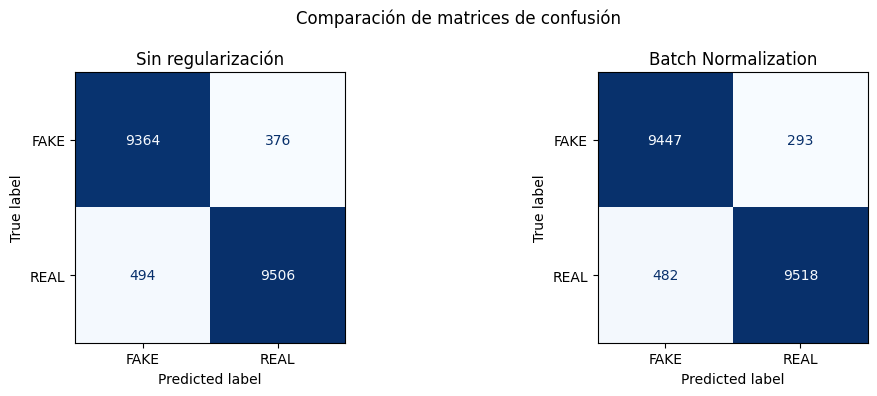

In [47]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(
    1,
    2,
    figsize=(11, 4)
)

for ax, (model_name, model_data) in zip(
    axes,
    diagnostic_predictions.items()
):

    cm = confusion_matrix(
        y_true,
        model_data["predictions"],
        labels=[0, 1]
    )

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["FAKE", "REAL"]
    )

    disp.plot(
        ax=ax,
        cmap="Blues",
        values_format="d",
        colorbar=False
    )

    ax.set_title(model_name)

plt.suptitle("Comparación de matrices de confusión")
plt.tight_layout()
plt.show()

In [48]:
for model_name, model_data in diagnostic_predictions.items():

    print("\n" + "=" * 60)
    print(model_name)
    print("=" * 60)

    report = classification_report(
        y_true,
        model_data["predictions"],
        labels=[0, 1],
        target_names=["FAKE", "REAL"],
        zero_division=0,
        output_dict=True
    )

    display(
        pd.DataFrame(report).T
    )


Sin regularización


,precision,recall,f1-score,support
FAKE,0.949888,0.961396,0.955608,9740.000000
REAL,0.961951,0.950600,0.956242,10000.000000
accuracy,0.955927,0.955927,0.955927,0.955927
macro avg,0.955920,0.955998,0.955925,19740.000000
weighted avg,0.955999,0.955927,0.955929,19740.000000



Batch Normalization


,precision,recall,f1-score,support
FAKE,0.951455,0.969918,0.960598,9740.00000
REAL,0.970136,0.951800,0.960880,10000.00000
accuracy,0.960740,0.960740,0.960740,0.96074
macro avg,0.960795,0.960859,0.960739,19740.00000
weighted avg,0.960918,0.960740,0.960741,19740.00000


La comparación de las matrices de confusión permite profundizar en las diferencias entre el modelo de referencia y el modelo con Batch Normalization. Los resultados muestran que esta última configuración reduce los errores de clasificación en ambas categorías. En particular, el número de imágenes FAKE clasificadas incorrectamente como REAL disminuye de 376 a 293, lo que supone una reducción de aproximadamente el 22 % de los falsos positivos. Por otra parte, los falsos negativos, correspondientes a imágenes REAL clasificadas como FAKE, pasan de 494 a 482. En conjunto, el número total de errores disminuye de 870 a 775, es decir, 95 errores menos sobre las 19740 imágenes del conjunto de validación.

Este comportamiento también se refleja en las métricas individuales de cada clase. El F1-score de FAKE aumenta del 95.56 % al 96.06 %, mientras que el de REAL pasa del 95.62 % al 96.09 %. Como consecuencia, el Macro F1 mejora del 95.59 % al 96.07 % y la accuracy aumenta del 95.59 % al 96.07 %. Por tanto, la mejora obtenida con Batch Normalization no se limita a una única categoría, sino que proporciona una clasificación más equilibrada de ambas clases. Destaca especialmente la reducción de falsos positivos, que indica una mayor capacidad para identificar correctamente las imágenes FAKE.

Estos resultados confirman que Batch Normalization proporciona una mejora efectiva del rendimiento predictivo sobre el conjunto de validación, a pesar de las oscilaciones observadas durante el entrenamiento. La comprobación previa de reproducibilidad también ha permitido descartar que estas diferencias sean consecuencia de una aleatoriedad introducida durante la evaluación del modelo. Asimismo, la inspección de las estadísticas móviles no ha revelado anomalías numéricas evidentes.

No obstante, la mejora en las métricas de clasificación viene acompañada de una pérdida de validación superior y de un incremento considerable del tiempo de entrenamiento. Por tanto, la elección de esta configuración deberá considerar conjuntamente el rendimiento predictivo, la estabilidad observada durante el entrenamiento y el coste computacional.

En conjunto, los experimentos muestran que el efecto de las técnicas de regularización depende de la estrategia utilizada. Mientras que L2 y Dropout no proporcionan mejoras significativas respecto al modelo de referencia, Batch Normalization consigue mejorar las métricas de clasificación, aunque presenta una mayor inestabilidad durante el entrenamiento y un coste computacional superior. Por tanto, se mantiene la CNN sin regularización como modelo de referencia y Batch Normalization como alternativa prometedora para los siguientes experimentos.

A continuación, se estudiará el efecto de Data Augmentation, con el objetivo de aumentar la diversidad de los datos de entrenamiento mediante transformaciones de las imágenes y comprobar si esta estrategia permite mejorar la capacidad de generalización de la red. Posteriormente, se evaluará la posible combinación de Data Augmentation con Batch Normalization para determinar si ambas técnicas proporcionan beneficios complementarios.

## 4.5. Data Augmentation

Una vez estudiado el efecto de las diferentes técnicas de regularización, se analiza la utilización de Data Augmentation como estrategia para mejorar la capacidad de generalización de la CNN.

Esta técnica consiste en aplicar transformaciones a las imágenes originales para introducir variabilidad en los datos utilizados durante el entrenamiento. De esta manera, el modelo puede aprender a reconocer las características relevantes de las imágenes bajo diferentes condiciones, reduciendo su dependencia de determinadas configuraciones visuales.

En este proyecto se utilizará una estrategia de *Data Augmentation on the fly*, en la que las transformaciones se aplican de forma aleatoria durante el propio proceso de entrenamiento, mediante capas de preprocesamiento integradas en la arquitectura de la CNN. Por tanto, no se generan ni almacenan nuevas imágenes en el dataset: el número de imágenes originales permanece constante y cada imagen se procesa una vez por época, aunque su representación puede variar entre diferentes épocas como consecuencia de las transformaciones aplicadas. Esto permite aumentar la diversidad de las muestras que recibe el modelo sin incrementar el tamaño del conjunto de datos ni los requisitos de almacenamiento.

Las transformaciones se aplicarán exclusivamente durante el entrenamiento. Durante la validación y la inferencia, las capas de Data Augmentation permanecen desactivadas, por lo que se utilizan siempre las imágenes originales, sin modificar. De esta forma, se garantiza que la evaluación del modelo se realiza sobre datos que no han sido aumentados artificialmente.

En este proyecto resulta especialmente importante seleccionar transformaciones que preserven la etiqueta original de las imágenes. El objetivo de clasificación consiste en distinguir entre imágenes reales y generadas sintéticamente, por lo que determinadas modificaciones podrían alterar características visuales relacionadas con las diferencias entre ambas categorías. Por este motivo, se priorizarán transformaciones geométricas moderadas y se evitarán inicialmente modificaciones de color, brillo o contraste, que podrían modificar características relevantes para la clasificación.

Se estudiarán dos estrategias de aumento de datos: la aplicación de reflexiones horizontales aleatorias y una combinación de reflexiones horizontales con pequeñas rotaciones, traslaciones y variaciones de zoom. Esto permitirá analizar si una mayor diversidad geométrica proporciona mejoras adicionales respecto a una transformación más sencilla.

Para realizar una comparación controlada, se mantendrán constantes la arquitectura y los hiperparámetros seleccionados en los experimentos anteriores: tres bloques convolucionales, una capa densa oculta y Global Average Pooling, con función de activación ReLU, optimizador RMSprop, tasa de aprendizaje de 0.001 y tamaño de batch de 64 imágenes. Se utilizará un máximo de 20 épocas de entrenamiento.

El modelo sin Data Augmentation, previamente entrenado, servirá como referencia para comparar los resultados, por lo que no será necesario repetir su entrenamiento.

Antes de realizar los entrenamientos, se muestran algunos ejemplos de las transformaciones geométricas que se aplicarán a las imágenes. Esto permite comprobar visualmente que las modificaciones introducidas son moderadas y que las imágenes resultantes conservan sus características generales.

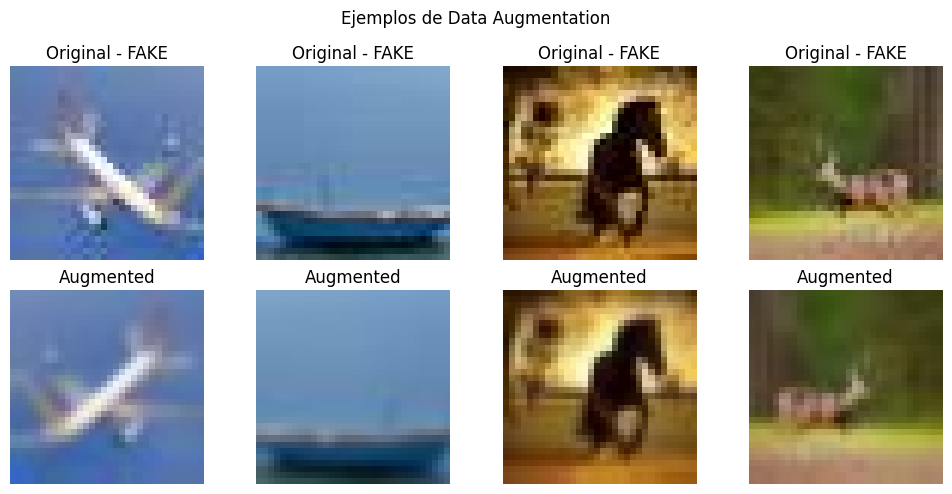

In [49]:
# Seleccionar cuatro imágenes de entrenamiento de forma reproducible
preview_records = random.Random(SEED).sample(train_records, 4)

# Cargar las imágenes originales
preview_images = []

for file_path, label in preview_records:

    image, _ = load_image(str(file_path), label)
    preview_images.append(image)

preview_images = tf.stack(preview_images)

# Aplicar Data Augmentation
preview_augmentation = create_augmentation_layers("mild_geometric")

augmented_images = preview_augmentation(preview_images, training=True)

# Representación
fig, axes = plt.subplots(2, 4, figsize=(10, 5))

for i in range(4):

    label_name = (
        "REAL" if preview_records[i][1] == 1 else "FAKE"
    )

    # Imagen original
    axes[0, i].imshow(
        np.clip(preview_images[i].numpy(), 0, 255).astype(np.uint8)
    )

    axes[0, i].set_title(f"Original - {label_name}")
    axes[0, i].axis("off")

    # Imagen transformada
    axes[1, i].imshow(
        np.clip(augmented_images[i].numpy(), 0, 255).astype(np.uint8)
    )

    axes[1, i].set_title("Augmented")
    axes[1, i].axis("off")

plt.suptitle("Ejemplos de Data Augmentation")
plt.tight_layout()
plt.show()

### 4.5.1. Configuración de los experimentos

Se plantean las siguientes configuraciones experimentales:

| Experimento | Data Augmentation |
|---|---|
| Referencia | Desactivado |
| CNN-HorizontalFlip | Reflexión horizontal aleatoria |
| CNN-Geometric | Reflexión horizontal, rotación, traslación y zoom moderados |

Las transformaciones se implementarán mediante las capas de preprocesamiento aleatorio de TensorFlow/Keras (RandomFlip, RandomRotation, RandomTranslation y RandomZoom), integradas directamente en la arquitectura de la red antes de la capa de normalización de las imágenes.

Al tratarse de una implementación de Data Augmentation on the fly, las imágenes transformadas se generan dinámicamente cada vez que atraviesan estas capas durante el entrenamiento, sin modificar los archivos originales ni aumentar el número de muestras del conjunto de entrenamiento. Además, una misma imagen puede experimentar transformaciones diferentes en distintas épocas, proporcionando variabilidad adicional al proceso de aprendizaje.

La intensidad de las transformaciones se mantendrá moderada debido a la baja resolución de las imágenes (32 × 32 píxeles), con el objetivo de introducir diversidad visual sin alterar excesivamente su contenido.

El modelo de referencia sin Data Augmentation ya ha sido entrenado durante los experimentos anteriores, por lo que se reutilizarán sus resultados. Únicamente será necesario entrenar las dos configuraciones adicionales.

Todas las variantes utilizarán las mismas particiones de entrenamiento y validación, así como idénticas condiciones de optimización. Las transformaciones aleatorias se aplicarán exclusivamente durante el entrenamiento, manteniendo intactos los conjuntos de validación y test.

A continuación se define la configuración de referencia para los experimentos llevados a cabo en esta sección.

In [50]:
# Modelo de referencia sin Data Augmentation
AUGMENTATION_REFERENCE_EXPERIMENT = ("optimizer_rmsprop_lr_0.001")

# Recuperar configuración seleccionada
augmentation_base_config = REFERENCE_CONFIG.copy()

# Condiciones comunes
augmentation_base_config.update({
    "activation": "relu",
    "optimizer_name": "rmsprop",
    "learning_rate": 0.001,
    "dropout_rate": 0.0,
    "l2_strength": 0.0,
    "batch_normalization": False,
    "data_augmentation": None
})

print("Configuración de referencia:")
print(augmentation_base_config)

# Inicializar lista de experimentos
augmentation_experiments = [AUGMENTATION_REFERENCE_EXPERIMENT]

Configuración de referencia:
{'num_conv_blocks': 3, 'num_dense_layers': 1, 'spatial_reduction': 'gap', 'activation': 'relu', 'optimizer_name': 'rmsprop', 'learning_rate': 0.001, 'momentum': 0.9, 'dropout_rate': 0.0, 'l2_strength': 0.0, 'batch_normalization': False, 'data_augmentation': None}


### 4.5.2. Ejecución y análisis de los experimentos

A continuación se ejecutan los experimentos expuestos en la sección anterior.

In [51]:
# Configuraciones de Data Augmentation
augmentation_candidates = {
    "augmentation_horizontal_flip": "horizontal_flip",
    "augmentation_mild_geometric": "mild_geometric"
}

# Entrenamiento de las variantes
for experiment_name, augmentation_type in augmentation_candidates.items():

    print(f"\n{'=' * 60}")
    print(f"Ejecutando experimento: {experiment_name}")
    print(f"{'=' * 60}")

    # Partir de la misma configuración de referencia
    config = augmentation_base_config.copy()

    # Activar la estrategia correspondiente
    config["data_augmentation"] = augmentation_type

    # Entrenamiento
    run_experiment(
        experiment_name=experiment_name,
        model_config=config,
        batch_size=REFERENCE_BATCH_SIZE,
        epochs=REFERENCE_EPOCHS
    )

    augmentation_experiments.append(experiment_name)


Ejecutando experimento: augmentation_horizontal_flip

EXPERIMENTO: augmentation_horizontal_flip
CONFIGURACIÓN: {'num_conv_blocks': 3, 'num_dense_layers': 1, 'spatial_reduction': 'gap', 'activation': 'relu', 'optimizer_name': 'rmsprop', 'learning_rate': 0.001, 'momentum': 0.9, 'dropout_rate': 0.0, 'l2_strength': 0.0, 'batch_normalization': False, 'data_augmentation': 'horizontal_flip'}
BATCH SIZE: 64
Epoch 1/20


c:\Users\angel\AppData\Local\Programs\Python\Python314\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


1234/1234 - 36s - 29ms/step - accuracy: 0.7979 - f1_real: 0.8043 - loss: 0.4290 - precision: 0.7894 - recall: 0.8198 - val_accuracy: 0.8513 - val_f1_real: 0.8662 - val_loss: 0.3439 - val_precision: 0.7961 - val_recall: 0.9498
Epoch 2/20
1234/1234 - 34s - 28ms/step - accuracy: 0.8819 - f1_real: 0.8834 - loss: 0.2837 - precision: 0.8835 - recall: 0.8832 - val_accuracy: 0.9116 - val_f1_real: 0.9138 - val_loss: 0.2211 - val_precision: 0.9026 - val_recall: 0.9253
Epoch 3/20
1234/1234 - 34s - 28ms/step - accuracy: 0.9054 - f1_real: 0.9067 - loss: 0.2323 - precision: 0.9057 - recall: 0.9078 - val_accuracy: 0.9089 - val_f1_real: 0.9146 - val_loss: 0.2205 - val_precision: 0.8710 - val_recall: 0.9628
Epoch 4/20
1234/1234 - 34s - 28ms/step - accuracy: 0.9178 - f1_real: 0.9189 - loss: 0.2064 - precision: 0.9188 - recall: 0.9189 - val_accuracy: 0.9342 - val_f1_real: 0.9354 - val_loss: 0.1704 - val_precision: 0.9317 - val_recall: 0.9390
Epoch 5/20
1234/1234 - 34s - 28ms/step - accuracy: 0.9242 - f1_

c:\Users\angel\AppData\Local\Programs\Python\Python314\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


1234/1234 - 38s - 31ms/step - accuracy: 0.7375 - f1_real: 0.7488 - loss: 0.5153 - precision: 0.7267 - recall: 0.7722 - val_accuracy: 0.7390 - val_f1_real: 0.6682 - val_loss: 0.5199 - val_precision: 0.9387 - val_recall: 0.5187
Epoch 2/20
1234/1234 - 36s - 29ms/step - accuracy: 0.8125 - f1_real: 0.8161 - loss: 0.4061 - precision: 0.8110 - recall: 0.8213 - val_accuracy: 0.7603 - val_f1_real: 0.6993 - val_loss: 0.5317 - val_precision: 0.9597 - val_recall: 0.5500
Epoch 3/20
1234/1234 - 36s - 29ms/step - accuracy: 0.8452 - f1_real: 0.8477 - loss: 0.3491 - precision: 0.8449 - recall: 0.8504 - val_accuracy: 0.6495 - val_f1_real: 0.4741 - val_loss: 1.1314 - val_precision: 0.9880 - val_recall: 0.3119
Epoch 4/20
1234/1234 - 36s - 29ms/step - accuracy: 0.8653 - f1_real: 0.8674 - loss: 0.3118 - precision: 0.8650 - recall: 0.8698 - val_accuracy: 0.7315 - val_f1_real: 0.6444 - val_loss: 0.7272 - val_precision: 0.9790 - val_recall: 0.4803
Epoch 5/20
1234/1234 - 36s - 29ms/step - accuracy: 0.8775 - f1_

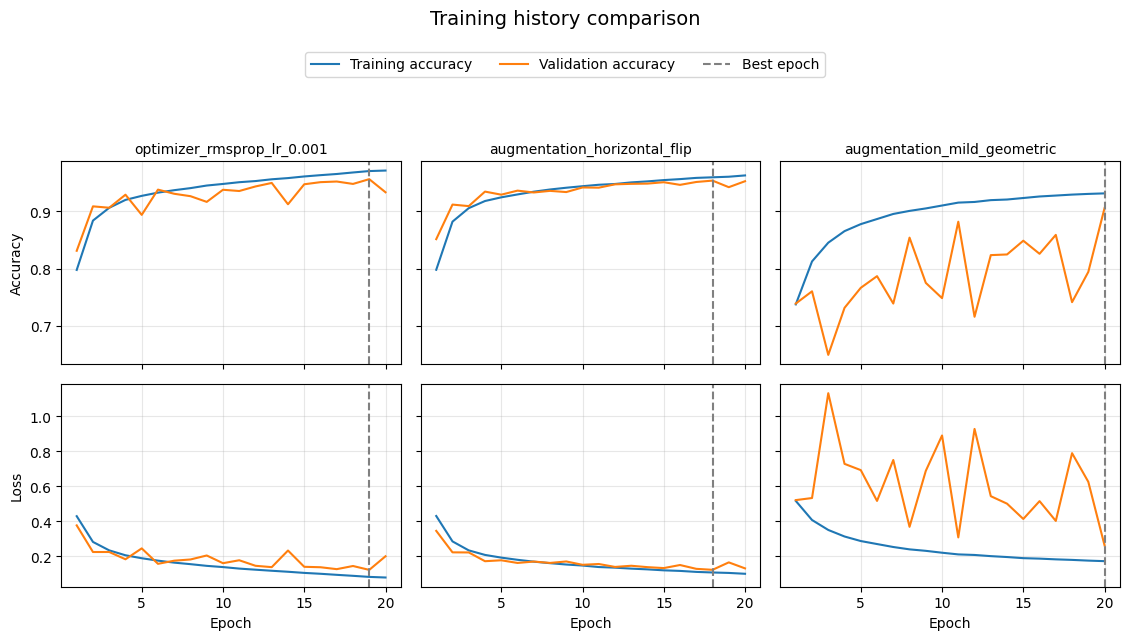

In [52]:
# Curvas de entrenamiento y validación
plot_training_history(augmentation_experiments)

In [53]:
augmentation_results = get_results_table(augmentation_experiments)

display(
    augmentation_results[
        [
            "experiment",
            "val_loss",
            "val_accuracy",
            "val_precision",
            "val_recall",
            "val_f1_real",
            "val_macro_f1",
            "best_epoch",
            "parameters",
            "training_seconds"
        ]
    ]
)

,experiment,val_loss,val_accuracy,val_precision,val_recall,val_f1_real,val_macro_f1,best_epoch,parameters,training_seconds
0,optimizer_rmsprop_lr_0.001,0.120787,0.955927,0.961951,0.9506,0.956242,0.955925,19,109889,701.787476
1,augmentation_horizontal_flip,0.121170,0.953394,0.958401,0.9492,0.953778,0.953391,18,109889,687.009997
2,augmentation_mild_geometric,0.260899,0.905522,0.979715,0.8307,0.899074,0.905135,20,109889,716.847832


Los resultados obtenidos muestran que las estrategias de Data Augmentation evaluadas no consiguen mejorar el rendimiento global del modelo de referencia. La aplicación de reflexiones horizontales proporciona resultados muy próximos a los obtenidos sin aumento de datos, mientras que la combinación de transformaciones geométricas produce un deterioro considerable de las métricas de clasificación.

En el caso de Horizontal Flip, se obtiene una accuracy del 95.34 % y un Macro F1 del 95.34 %, ligeramente inferiores a los valores del modelo sin Data Augmentation (95.59 % y 95.59 %, respectivamente). Las curvas de entrenamiento y validación presentan una evolución estable y similar a la de referencia, sin mostrar diferencias significativas en el comportamiento del aprendizaje. Por tanto, la reflexión horizontal no parece aportar una mejora relevante de la capacidad de generalización para el problema estudiado.

Por el contrario, Geometric Augmentation proporciona resultados considerablemente inferiores, alcanzando una accuracy del 90.55 % y un Macro F1 del 90.51 %. Aunque consigue una precisión elevada (97.97 %), su recall disminuye hasta el 83.07 %, lo que indica que el modelo identifica correctamente una elevada proporción de las imágenes que predice como REAL, pero deja sin clasificar correctamente un número considerable de imágenes pertenecientes a esta categoría.

El análisis de las curvas permite identificar un comportamiento especialmente irregular en esta última configuración. Mientras que la accuracy de entrenamiento aumenta progresivamente y la pérdida disminuye de forma relativamente suave, las métricas de validación presentan oscilaciones pronunciadas. La pérdida de validación alcanza valores elevados en diferentes épocas y la accuracy experimenta fluctuaciones importantes. Este comportamiento sugiere que las transformaciones geométricas introducidas dificultan la generalización del modelo sobre las imágenes originales.

Una posible explicación es que, debido a la reducida resolución de las imágenes del dataset (32 × 32 píxeles), las rotaciones, traslaciones y variaciones de zoom pueden modificar características visuales y de textura relevantes para distinguir entre imágenes reales y sintéticas. Además, al combinar varias transformaciones simultáneamente, no es posible determinar cuál de ellas contribuye en mayor medida al deterioro observado.

En cuanto al coste computacional, Horizontal Flip apenas incrementa el tiempo de entrenamiento respecto al modelo de referencia, mientras que Geometric Augmentation supone un incremento moderado. Sin embargo, ninguno de estos costes adicionales se traduce en una mejora del rendimiento predictivo.

En conjunto, los resultados indican que las estrategias de Data Augmentation evaluadas no proporcionan beneficios significativos para la arquitectura y el problema considerados. La reflexión horizontal mantiene un comportamiento estable, pero no consigue superar al modelo de referencia, mientras que la combinación de transformaciones geométricas perjudica considerablemente la capacidad de clasificación.

Por tanto, se mantiene como configuración de referencia la CNN sin Data Augmentation. Los resultados sugieren que las transformaciones geométricas utilizadas no son adecuadas en su configuración actual para imágenes de tan baja resolución y para una tarea en la que las características visuales y de textura pueden tener un papel relevante.

### 4.5.3. Combinación de Batch Normalization y Data Augmentation

Los experimentos anteriores han mostrado que Batch Normalization proporciona una mejora en las métricas de clasificación respecto al modelo de referencia, mientras que la aplicación de reflexiones horizontales aleatorias mediante Data Augmentation no consigue mejorar significativamente el rendimiento cuando se utiliza de forma independiente.

A partir de estas observaciones, se plantea un experimento adicional para estudiar si ambas técnicas pueden proporcionar beneficios complementarios cuando se utilizan conjuntamente.

Para ello, se incorporará la transformación Horizontal Flip al modelo que utiliza Batch Normalization, manteniendo el resto de las condiciones experimentales. Se descartan las transformaciones geométricas más complejas evaluadas anteriormente, debido al deterioro significativo de las métricas de validación que produjeron.

La comparación permitirá estudiar si la diversidad adicional introducida mediante las reflexiones horizontales contribuye a mejorar la capacidad de generalización del modelo con Batch Normalization o si, por el contrario, no proporciona beneficios adicionales.

Se mantendrán la arquitectura, la función de activación ReLU, el optimizador RMSprop, una tasa de aprendizaje de 0.001, un tamaño de batch de 64 imágenes y un máximo de 20 épocas de entrenamiento. La única diferencia respecto al experimento individual con Batch Normalization será la activación de Horizontal Flip.

Para evaluar el efecto de la combinación se compararán cuatro configuraciones: el modelo de referencia sin regularización ni Data Augmentation, el modelo con Batch Normalization, el modelo con Horizontal Flip y el modelo que combina ambas técnicas.

In [54]:
# Nombre del nuevo experimento
COMBINED_EXPERIMENT = ("regularization_batch_norm_horizontal_flip")

# Recuperar la configuración de referencia
combined_config = REFERENCE_CONFIG.copy()

# Activar Batch Normalization y Horizontal Flip
combined_config.update({
    "batch_normalization": True,
    "data_augmentation": "horizontal_flip",

    # Mantener desactivadas las otras técnicas
    "dropout_rate": 0.0,
    "l2_strength": 0.0
})

# Comprobar la configuración
print("Configuración del experimento combinado:")
print(combined_config)

# Entrenamiento
run_experiment(
    experiment_name=COMBINED_EXPERIMENT,
    model_config=combined_config,
    batch_size=REFERENCE_BATCH_SIZE,
    epochs=REFERENCE_EPOCHS
)

Configuración del experimento combinado:
{'num_conv_blocks': 3, 'num_dense_layers': 1, 'spatial_reduction': 'gap', 'activation': 'relu', 'optimizer_name': 'rmsprop', 'learning_rate': 0.001, 'momentum': 0.9, 'dropout_rate': 0.0, 'l2_strength': 0.0, 'batch_normalization': True, 'data_augmentation': 'horizontal_flip'}

EXPERIMENTO: regularization_batch_norm_horizontal_flip
CONFIGURACIÓN: {'num_conv_blocks': 3, 'num_dense_layers': 1, 'spatial_reduction': 'gap', 'activation': 'relu', 'optimizer_name': 'rmsprop', 'learning_rate': 0.001, 'momentum': 0.9, 'dropout_rate': 0.0, 'l2_strength': 0.0, 'batch_normalization': True, 'data_augmentation': 'horizontal_flip'}
BATCH SIZE: 64
Epoch 1/20


c:\Users\angel\AppData\Local\Programs\Python\Python314\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


1234/1234 - 63s - 51ms/step - accuracy: 0.8981 - f1_real: 0.8996 - loss: 0.2437 - precision: 0.8978 - recall: 0.9014 - val_accuracy: 0.8214 - val_f1_real: 0.8493 - val_loss: 0.4110 - val_precision: 0.7418 - val_recall: 0.9933
Epoch 2/20
1234/1234 - 59s - 48ms/step - accuracy: 0.9289 - f1_real: 0.9299 - loss: 0.1802 - precision: 0.9297 - recall: 0.9301 - val_accuracy: 0.8587 - val_f1_real: 0.8401 - val_loss: 0.3454 - val_precision: 0.9842 - val_recall: 0.7329
Epoch 3/20
1234/1234 - 59s - 48ms/step - accuracy: 0.9387 - f1_real: 0.9395 - loss: 0.1572 - precision: 0.9402 - recall: 0.9387 - val_accuracy: 0.9121 - val_f1_real: 0.9181 - val_loss: 0.2366 - val_precision: 0.8692 - val_recall: 0.9729
Epoch 4/20
1234/1234 - 59s - 48ms/step - accuracy: 0.9443 - f1_real: 0.9449 - loss: 0.1442 - precision: 0.9457 - recall: 0.9441 - val_accuracy: 0.8664 - val_f1_real: 0.8826 - val_loss: 0.3623 - val_precision: 0.7954 - val_recall: 0.9912
Epoch 5/20
1234/1234 - 59s - 48ms/step - accuracy: 0.9479 - f1_

{'experiment': 'regularization_batch_norm_horizontal_flip',
 'val_loss': 0.13459543883800507,
 'val_accuracy': 0.9517730474472046,
 'val_precision': 0.9521287083625793,
 'val_recall': 0.9527000188827515,
 'val_f1_real': 0.9524142146110535,
 'val_macro_f1': 0.951764290985889,
 'best_epoch': 20,
 'parameters': 110945,
 'training_seconds': 1184.6128320999997,
 'batch_size': 64}

In [55]:
# Modelos incluidos en la comparación
combined_experiments = [
    "optimizer_rmsprop_lr_0.001",
    "regularization_batch_norm",
    "augmentation_horizontal_flip",
    COMBINED_EXPERIMENT
]

combined_results = get_results_table(combined_experiments)

display(
    combined_results[
        [
            "experiment",
            "val_loss",
            "val_accuracy",
            "val_precision",
            "val_recall",
            "val_f1_real",
            "val_macro_f1",
            "best_epoch",
            "parameters",
            "training_seconds"
        ]
    ]
)

,experiment,val_loss,val_accuracy,val_precision,val_recall,val_f1_real,val_macro_f1,best_epoch,parameters,training_seconds
0,optimizer_rmsprop_lr_0.001,0.120787,0.955927,0.961951,0.9506,0.956242,0.955925,19,109889,701.787476
1,augmentation_horizontal_flip,0.121170,0.953394,0.958401,0.9492,0.953778,0.953391,18,109889,687.009997
2,regularization_batch_norm_horizontal_flip,0.134595,0.951773,0.952129,0.9527,0.952414,0.951764,20,110945,1184.612832
3,regularization_batch_norm,0.136980,0.960740,0.970136,0.9518,0.960880,0.960739,19,110945,1170.759125


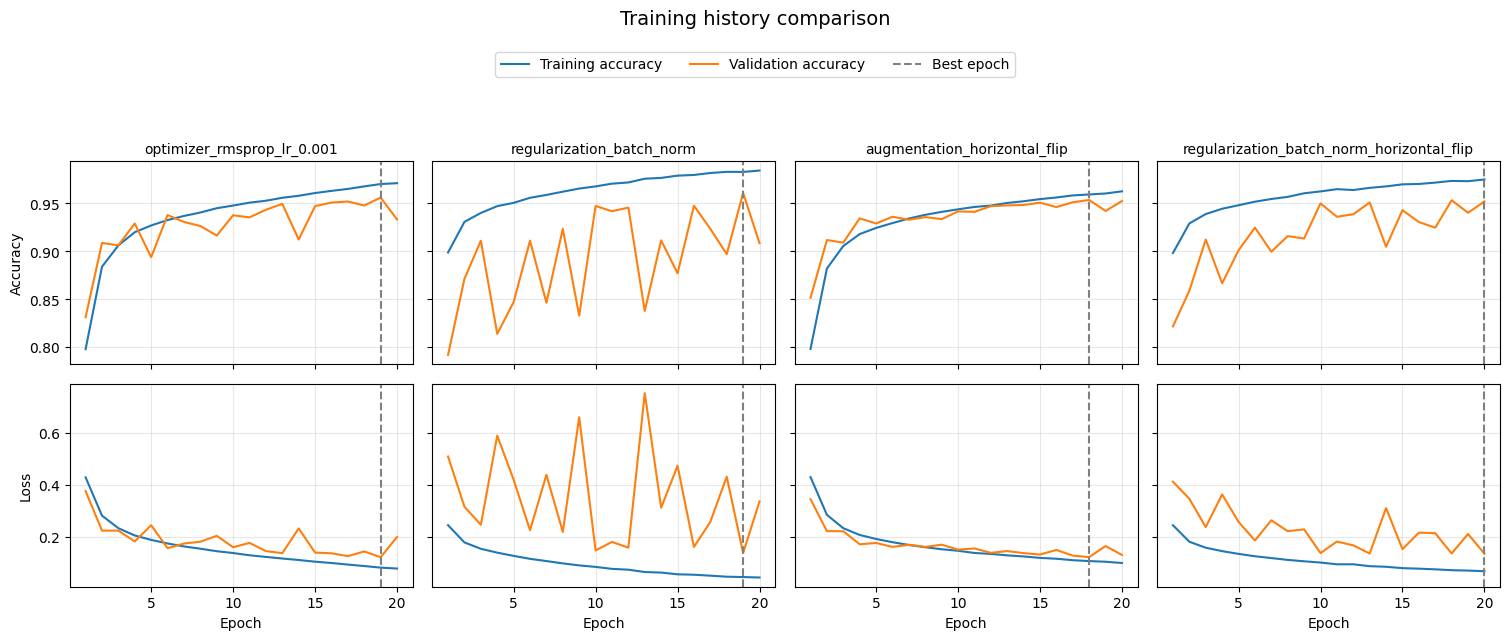

In [56]:
# Curvas de entrenamiento y validación
plot_training_history(combined_experiments)

Los resultados muestran que la combinación no proporciona una mejora. El modelo combinado alcanza una accuracy del 95.18 % y un F1 macro del 95.18 %, por debajo tanto del modelo de referencia (95.59 % en ambas métricas) como del modelo que utiliza exclusivamente Batch Normalization (96.07 %).

Aunque la pérdida de validación del modelo combinado es ligeramente inferior a la obtenida con Batch Normalization por separado (0.1346 frente a 0.1370), esta diferencia no se traduce en una mejora de las métricas de clasificación. Por tanto, la evaluación conjunta de accuracy, precision, recall y F1 macro resulta más favorable al modelo con Batch Normalization sin aumento de datos.

El análisis de las curvas de entrenamiento también muestra que la combinación no resuelve las oscilaciones observadas en la validación del modelo con Batch Normalization. En consecuencia, no se observa una complementariedad positiva entre ambas técnicas para este problema.

**Conclusión:** se descarta la combinación de Batch Normalization y Data Augmentation, ya que no mejora los resultados de ninguna de las configuraciones individuales. Se mantiene Batch Normalization como la alternativa más prometedora para la CNN entrenada desde cero, al haber obtenido los mejores resultados de accuracy, precision y F1 macro en el conjunto de validación. No obstante, sus oscilaciones durante la validación deberán tenerse en cuenta al interpretar su capacidad de generalización.

### 4.5.4. Experimento: efecto de incrementar el número de épocas

Una vez seleccionadas las configuraciones más prometedoras, se realiza un último experimento para estudiar el efecto de prolongar el entrenamiento de 20 a 50 épocas.

Se comparan la CNN de referencia y la CNN con Batch Normalization, manteniendo constantes el resto de hiperparámetros. El objetivo es determinar si los modelos pueden seguir mejorando su rendimiento o si ya han alcanzado su capacidad de generalización con el entrenamiento inicial.

En ambos casos, se conserva la configuración correspondiente a la época con menor pérdida de validación mediante el mecanismo de almacenamiento de mejores pesos en memoria.

In [57]:
LONG_TRAINING_EPOCHS = 50

# 1. CNN de referencia: entrenamiento desde cero
config_cnn_50 = REFERENCE_CONFIG.copy()
config_cnn_50.update({
    "batch_normalization": False,
    "data_augmentation": None,
    "dropout_rate": 0.0,
    "l2_strength": 0.0
})

run_experiment(
    experiment_name="cnn_reference_50_epochs",
    model_config=config_cnn_50,
    batch_size=REFERENCE_BATCH_SIZE,
    epochs=LONG_TRAINING_EPOCHS
)

# 2. CNN con Batch Normalization: entrenamiento desde cero
config_bn_50 = REFERENCE_CONFIG.copy()
config_bn_50.update({
    "batch_normalization": True,
    "data_augmentation": None,
    "dropout_rate": 0.0,
    "l2_strength": 0.0
})

run_experiment(
    experiment_name="cnn_batch_norm_50_epochs",
    model_config=config_bn_50,
    batch_size=REFERENCE_BATCH_SIZE,
    epochs=LONG_TRAINING_EPOCHS
)


EXPERIMENTO: cnn_reference_50_epochs
CONFIGURACIÓN: {'num_conv_blocks': 3, 'num_dense_layers': 1, 'spatial_reduction': 'gap', 'activation': 'relu', 'optimizer_name': 'rmsprop', 'learning_rate': 0.001, 'momentum': 0.9, 'dropout_rate': 0.0, 'l2_strength': 0.0, 'batch_normalization': False, 'data_augmentation': None}
BATCH SIZE: 64
Epoch 1/50


c:\Users\angel\AppData\Local\Programs\Python\Python314\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


1234/1234 - 39s - 31ms/step - accuracy: 0.7976 - f1_real: 0.8041 - loss: 0.4279 - precision: 0.7889 - recall: 0.8200 - val_accuracy: 0.8310 - val_f1_real: 0.8524 - val_loss: 0.3753 - val_precision: 0.7644 - val_recall: 0.9634
Epoch 2/50
1234/1234 - 34s - 27ms/step - accuracy: 0.8837 - f1_real: 0.8852 - loss: 0.2807 - precision: 0.8855 - recall: 0.8848 - val_accuracy: 0.9085 - val_f1_real: 0.9115 - val_loss: 0.2230 - val_precision: 0.8936 - val_recall: 0.9301
Epoch 3/50
1234/1234 - 34s - 27ms/step - accuracy: 0.9060 - f1_real: 0.9074 - loss: 0.2324 - precision: 0.9060 - recall: 0.9088 - val_accuracy: 0.9061 - val_f1_real: 0.9122 - val_loss: 0.2231 - val_precision: 0.8667 - val_recall: 0.9626
Epoch 4/50
1234/1234 - 33s - 27ms/step - accuracy: 0.9198 - f1_real: 0.9209 - loss: 0.2043 - precision: 0.9203 - recall: 0.9214 - val_accuracy: 0.9288 - val_f1_real: 0.9315 - val_loss: 0.1815 - val_precision: 0.9093 - val_recall: 0.9547
Epoch 5/50
1234/1234 - 34s - 27ms/step - accuracy: 0.9268 - f1_

c:\Users\angel\AppData\Local\Programs\Python\Python314\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


1234/1234 - 63s - 51ms/step - accuracy: 0.8986 - f1_real: 0.9001 - loss: 0.2439 - precision: 0.8980 - recall: 0.9024 - val_accuracy: 0.7917 - val_f1_real: 0.8285 - val_loss: 0.5077 - val_precision: 0.7106 - val_recall: 0.9933
Epoch 2/50
1234/1234 - 58s - 47ms/step - accuracy: 0.9306 - f1_real: 0.9315 - loss: 0.1777 - precision: 0.9309 - recall: 0.9321 - val_accuracy: 0.8711 - val_f1_real: 0.8562 - val_loss: 0.3148 - val_precision: 0.9847 - val_recall: 0.7574
Epoch 3/50
1234/1234 - 58s - 47ms/step - accuracy: 0.9399 - f1_real: 0.9406 - loss: 0.1532 - precision: 0.9414 - recall: 0.9398 - val_accuracy: 0.9108 - val_f1_real: 0.9074 - val_loss: 0.2457 - val_precision: 0.9574 - val_recall: 0.8624
Epoch 4/50
1234/1234 - 58s - 47ms/step - accuracy: 0.9470 - f1_real: 0.9476 - loss: 0.1384 - precision: 0.9484 - recall: 0.9469 - val_accuracy: 0.8137 - val_f1_real: 0.8441 - val_loss: 0.5884 - val_precision: 0.7325 - val_recall: 0.9960
Epoch 5/50
1234/1234 - 58s - 47ms/step - accuracy: 0.9504 - f1_

{'experiment': 'cnn_batch_norm_50_epochs',
 'val_loss': 0.1369798183441162,
 'val_accuracy': 0.9607396125793457,
 'val_precision': 0.9701355695724487,
 'val_recall': 0.9517999887466431,
 'val_f1_real': 0.9608802199363708,
 'val_macro_f1': 0.9607391070898346,
 'best_epoch': 19,
 'parameters': 110945,
 'training_seconds': 2909.9203797999944,
 'batch_size': 64}

,experiment,val_loss,val_accuracy,val_precision,val_recall,val_f1_real,val_macro_f1,best_epoch,training_seconds
0,optimizer_rmsprop_lr_0.001,0.120787,0.955927,0.961951,0.9506,0.956242,0.955925,19,701.787476
1,cnn_reference_50_epochs,0.120787,0.955927,0.961951,0.9506,0.956242,0.955925,19,1698.922400
2,regularization_batch_norm,0.136980,0.960740,0.970136,0.9518,0.960880,0.960739,19,1170.759125
3,cnn_batch_norm_50_epochs,0.136980,0.960740,0.970136,0.9518,0.960880,0.960739,19,2909.920380


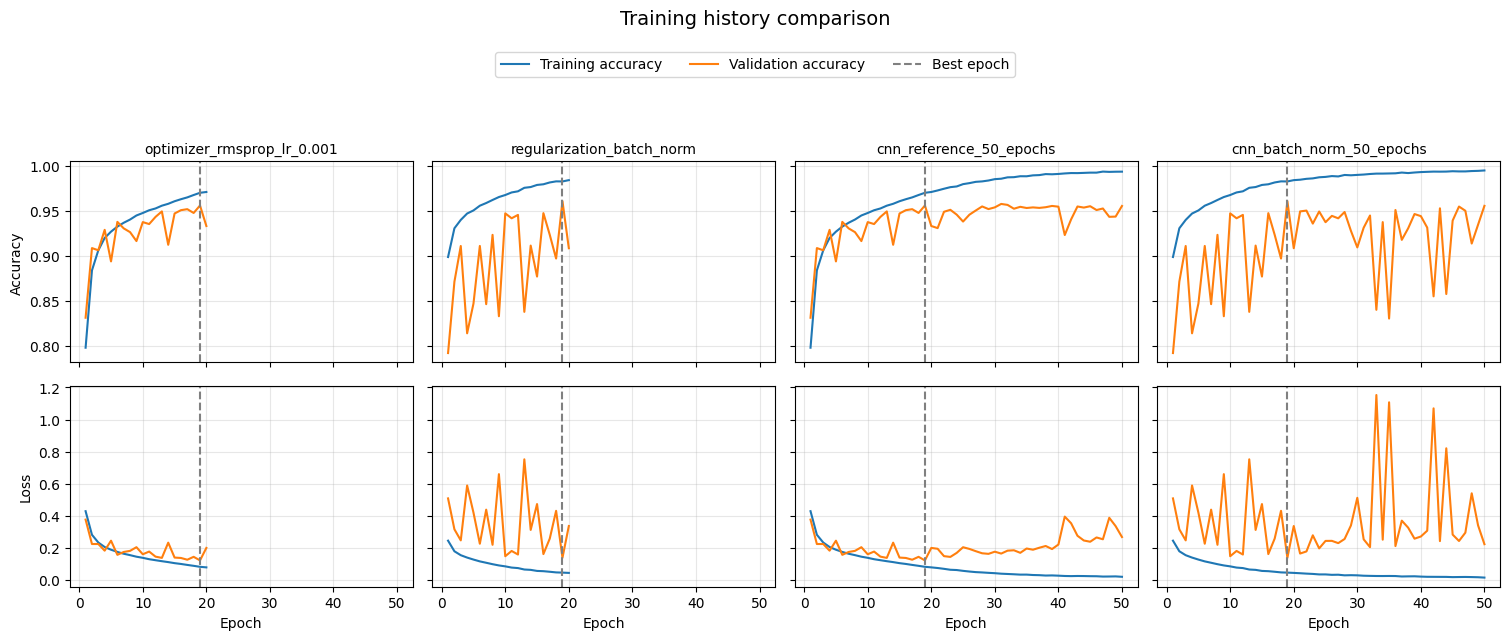

In [58]:
long_training_experiments = [
    "optimizer_rmsprop_lr_0.001",
    "regularization_batch_norm",
    "cnn_reference_50_epochs",
    "cnn_batch_norm_50_epochs"
]

long_training_results = get_results_table(
    long_training_experiments
)

display(
    long_training_results[
        [
            "experiment",
            "val_loss",
            "val_accuracy",
            "val_precision",
            "val_recall",
            "val_f1_real",
            "val_macro_f1",
            "best_epoch",
            "training_seconds"
        ]
    ]
)

plot_training_history(long_training_experiments)

Los resultados muestran que el incremento del número de épocas no proporciona ninguna mejora en las métricas de validación. En ambos modelos, los valores obtenidos son exactamente iguales a los de los experimentos originales de 20 épocas. Además, el mejor checkpoint continúa correspondiendo a la época 19.

El análisis de las curvas permite explicar este comportamiento. Aunque la accuracy de entrenamiento sigue aumentando durante las épocas adicionales, las métricas de validación permanecen prácticamente estancadas. En la CNN de referencia se observa incluso una tendencia creciente de la pérdida de validación, mientras que el modelo con Batch Normalization mantiene las importantes oscilaciones observadas en los experimentos anteriores.

Estos resultados indican que prolongar el entrenamiento no mejora la capacidad de generalización de los modelos y puede favorecer el sobreajuste. Por otra parte, supone un incremento considerable del coste computacional sin obtener beneficios adicionales.

Por lo tanto, se mantiene un máximo de 20 épocas para los experimentos de la CNN entrenada desde cero. La configuración con Batch Normalization sigue siendo la candidata más prometedora, al alcanzar una accuracy del 96.07 % y un F1 macro del 96.07 % en validación, frente al 95.59 % obtenido por la CNN de referencia.

## 4.6. Conclusiones

En esta sección se ha desarrollado de forma progresiva una red neuronal convolucional entrenada desde cero para distinguir entre imágenes reales e imágenes generadas sintéticamente. El diseño se ha abordado mediante un proceso experimental iterativo, estudiando por separado la influencia de la arquitectura, los hiperparámetros y las técnicas de regularización y aumento de datos. Este procedimiento ha permitido justificar las decisiones de diseño a partir de los resultados obtenidos sobre el conjunto de validación.

En primer lugar, se ha seleccionado una arquitectura formada por **tres bloques convolucionales, una capa densa oculta y Global Average Pooling**. Esta configuración proporciona un equilibrio adecuado entre capacidad de representación y complejidad, con 109889 parámetros entrenables en su versión sin Batch Normalization. La utilización de Global Average Pooling permite reducir las dimensiones de los mapas de características antes de la etapa de clasificación, evitando el incremento de parámetros que supondría una capa Flatten seguida de una capa densa de gran tamaño.

En cuanto a la optimización, los experimentos han permitido seleccionar **RMSprop con una tasa de aprendizaje de 0.001**, un tamaño de batch de 64 imágenes y la función de activación ReLU. Aunque se han observado diferencias entre los optimizadores, tamaños de batch y funciones de activación evaluados, esta combinación ha ofrecido el mejor equilibrio entre rendimiento predictivo y coste computacional.

Posteriormente, se han estudiado diferentes técnicas de regularización. Los resultados indican que ni la regularización L2 ni Dropout proporcionan mejoras relevantes respecto al modelo de referencia. Por el contrario, **Batch Normalization consigue los mejores resultados de clasificación sobre el conjunto de validación**, alcanzando una accuracy del 96.07 %, un F1-score para la clase REAL del 96.09 % y un Macro F1 del 96.07 %. Esto supone una mejora aproximada de 0.48 puntos porcentuales en accuracy y Macro F1 respecto a la CNN sin regularización, cuyos valores son del 95.59 %. No obstante, esta mejora debe interpretarse teniendo en cuenta que el modelo con Batch Normalization presenta una pérdida de validación superior a la del modelo de referencia y unas curvas de validación con oscilaciones pronunciadas. Por tanto, aunque obtiene mejores métricas de clasificación para el umbral establecido, su comportamiento durante la validación resulta menos estable.

También se ha evaluado la aplicación de Data Augmentation mediante volteo horizontal y transformaciones geométricas moderadas. Ninguna de estas configuraciones ha conseguido mejorar el rendimiento del modelo de referencia. En particular, las transformaciones geométricas producen un deterioro considerable de las métricas, mientras que el volteo horizontal ofrece resultados próximos, pero ligeramente inferiores. Asimismo, la combinación de Batch Normalization con volteo horizontal tampoco proporciona una mejora respecto a la utilización individual de Batch Normalization. Estos resultados indican que las transformaciones evaluadas no aportan información adicional útil para este problema y que algunas pueden alterar características relevantes de las imágenes.

Por último, se ha estudiado el efecto de prolongar el entrenamiento de 20 a 50 épocas para las dos configuraciones más prometedoras: la CNN de referencia y la CNN con Batch Normalization. En ambos casos, las métricas finales de validación permanecen exactamente iguales a las obtenidas con 20 épocas, y el mejor resultado continúa correspondiendo a la época 19. Aunque la accuracy de entrenamiento sigue aumentando durante las épocas adicionales, el rendimiento de validación no mejora, lo que apunta a un posible sobreajuste. Por tanto, se considera suficiente mantener un máximo de 20 épocas para esta estrategia.

En conjunto, los experimentos permiten seleccionar como configuración candidata la **CNN con tres bloques convolucionales, una capa densa oculta, Global Average Pooling, ReLU, RMSprop con learning rate de 0.001, batch size de 64 y Batch Normalization**. Esta configuración ha obtenido los mejores resultados de clasificación en validación entre las alternativas estudiadas.

Finalmente, debe tenerse en cuenta que todas las decisiones de diseño se han tomado utilizando exclusivamente los conjuntos de entrenamiento y validación. El conjunto de test permanece reservado para la evaluación final, una vez completado el desarrollo de las distintas estrategias. De este modo, será posible comparar de forma independiente la capacidad de generalización de la CNN entrenada desde cero y de los modelos basados en Transfer Learning y Fine-Tuning.

# 5. Diseño, entrenamiento y evaluación de redes preentrenadas

## 5.1. Introducción y selección de arquitecturas

En esta sección se aborda la segunda estrategia propuesta en el proyecto: utilizar arquitecturas de redes neuronales convolucionales preentrenadas sobre ImageNet y adaptarlas al problema de clasificación mediante técnicas de *Transfer Learning* y *Fine-Tuning*.

A diferencia de la estrategia anterior, en la que todos los parámetros de la CNN se inicializaban aleatoriamente y se aprendían a partir del conjunto de datos seleccionado, en este caso se parte de modelos que ya han aprendido representaciones visuales a partir de un conjunto de imágenes de gran escala. El objetivo es aprovechar estas características previamente aprendidas y estudiar hasta qué punto pueden transferirse al problema de distinguir entre imágenes reales e imágenes generadas sintéticamente.

De acuerdo con el enunciado, se seleccionan dos arquitecturas diferentes disponibles en Keras: **MobileNetV2 y ResNet50**. Ambas disponen de pesos preentrenados sobre ImageNet y presentan características arquitectónicas distintas, lo que permite comparar dos aproximaciones al problema.

El desarrollo de esta estrategia se organizará en las siguientes etapas:

1. **Selección y configuración de las arquitecturas preentrenadas.** Se cargarán MobileNetV2 y ResNet50 con los pesos aprendidos sobre ImageNet, eliminando sus clasificadores originales para incorporar nuevas capas adaptadas a la clasificación binaria del proyecto.
2. **Adaptación del preprocesamiento.** Las imágenes se redimensionarán para adecuarlas a las entradas de las redes y se aplicará el preprocesamiento específico requerido por cada arquitectura.
3. **Transfer Learning.** Inicialmente se congelarán todas las capas de las redes preentrenadas y se entrenará únicamente el nuevo clasificador. De esta forma se estudiará la capacidad de las características aprendidas sobre ImageNet para resolver el problema sin modificar el extractor original.
4. **Fine-Tuning.** Partiendo de los pesos obtenidos durante la fase anterior, se desbloqueará una parte de las capas finales de cada arquitectura y se continuará el entrenamiento utilizando una tasa de aprendizaje reducida. El objetivo será adaptar parcialmente las características preentrenadas al conjunto de imágenes CIFAKE.
5. **Comparación y selección de modelos.** Se compararán los resultados de ambas arquitecturas y de las dos estrategias de entrenamiento, utilizando las mismas particiones de entrenamiento y validación y las métricas definidas anteriormente.

En todos los experimentos se utilizará el conjunto de entrenamiento para actualizar los parámetros y el conjunto de validación para monitorizar el aprendizaje y seleccionar los mejores pesos. El conjunto de test permanecerá reservado para la evaluación final de las estrategias.

### 5.1.1. MobileNetV2

MobileNetV2 es una arquitectura CNN diseñada para conseguir un equilibrio entre capacidad de representación y coste computacional. Su diseño se basa en bloques *inverted residual* y *linear bottlenecks*, que permiten reducir el número de operaciones y parámetros respecto a las convoluciones convencionales.

Una de sus principales características es la utilización de convoluciones separables en profundidad (*depthwise separable convolutions*), que descomponen las operaciones convolucionales en dos etapas y reducen significativamente el coste computacional.

Estas características hacen de MobileNetV2 una alternativa especialmente interesante para este proyecto, ya que permite estudiar el rendimiento de una arquitectura preentrenada relativamente ligera frente a la CNN diseñada desde cero.

### 5.1.2. ResNet50

ResNet50 es una arquitectura convolucional profunda basada en conexiones residuales (*residual connections*). Estas conexiones introducen caminos alternativos que permiten transmitir las activaciones y los gradientes entre diferentes niveles de la red, facilitando el entrenamiento de arquitecturas con un elevado número de capas.

La arquitectura ResNet50 está formada por diferentes etapas de bloques residuales que extraen características visuales progresivamente más complejas. Su mayor profundidad y capacidad representacional permiten estudiar si un extractor de características más complejo proporciona ventajas respecto a MobileNetV2 para el problema planteado.

### 5.1.3. Adaptación de las arquitecturas al problema de clasificación

En ambos casos se eliminará el clasificador original de ImageNet. De esta manera se conservará el extractor convolucional preentrenado, sustituyendo las capas finales por una nueva cabeza de clasificación adaptada al problema binario.

Para mantener una comparación homogénea, se utilizará la misma cabeza de clasificación en las dos arquitecturas, formada por una capa GlobalAveragePooling2D, una capa densa de 128 neuronas con activación ReLU y una neurona de salida con activación sigmoide.

La arquitectura resultante permitirá obtener una única probabilidad asociada a la clase REAL, considerando como FAKE aquellas predicciones inferiores al umbral de 0.5.

Ambos modelos utilizarán inicialmente una resolución de entrada de 128 × 128 píxeles. Dado que las imágenes originales tienen una resolución de 32 × 32 píxeles, será necesario redimensionarlas. Esta operación adapta las dimensiones de entrada, pero no incorpora información visual adicional a la contenida en las imágenes originales. Nótese que se utiliza un tamaño de batch de 32 para reducir el consumo de memoria, ya que las redes preentrenadas procesan imágenes de mayor resolución (128 × 128) y tienen arquitecturas más complejas.

Se utilizará el preprocesamiento específico de cada arquitectura, de acuerdo con los requisitos de los modelos preentrenados. Asimismo, inicialmente no se aplicarán técnicas adicionales de aumento de datos, ya que los experimentos realizados en la sección anterior no mostraron mejoras con las transformaciones evaluadas. De esta forma se podrá estudiar primero el efecto de los pesos preentrenados y del Fine-Tuning sin introducir otros factores adicionales.

### 5.1.4. Estrategia de entrenamiento

Para cada arquitectura se realizarán dos fases de entrenamiento.

En primer lugar, durante la fase de *Transfer Learning*, se congelarán todas las capas del extractor convolucional preentrenado. Únicamente se actualizarán los parámetros de la nueva cabeza de clasificación, que parte de una inicialización aleatoria. Esta fase permitirá evaluar la utilidad de las representaciones visuales aprendidas sobre ImageNet sin modificar los pesos originales.

Posteriormente, durante la fase de *Fine-Tuning*, se partirá de los mejores pesos obtenidos en la fase anterior y se desbloqueará el 25 % final de las capas del extractor convolucional. El entrenamiento continuará durante un número adicional de épocas, utilizando una tasa de aprendizaje considerablemente menor para evitar modificar bruscamente las representaciones previamente aprendidas.

Las capas Batch Normalization pertenecientes a los extractores preentrenados permanecerán congeladas durante el Fine-Tuning, evitando alterar sus estadísticas internas debido al cambio de dominio y al tamaño de los batches.

Para facilitar la comparación, se mantendrán las mismas condiciones de entrenamiento para las dos arquitecturas: tamaño de batch de 32 imágenes, optimizador RMSprop y una tasa de aprendizaje inicial de 0.001 durante Transfer Learning. En Fine-Tuning se reducirá la tasa de aprendizaje a 0.00001.

Se conservará en memoria el conjunto de pesos que proporcione la menor pérdida de validación, tanto durante Transfer Learning como durante Fine-Tuning. De esta forma, el modelo seleccionado al finalizar la segunda fase no será necesariamente el correspondiente a la última época, sino el que haya obtenido el mejor resultado de validación a lo largo de ambas fases.

## 5.2. Configuración del entorno experimental

Antes de construir y entrenar los modelos, se definen los parámetros comunes que se utilizarán durante esta estrategia.

Se utilizará una resolución de 128 × 128 píxeles para ambas arquitecturas y un tamaño de batch de 32 imágenes, con el objetivo de limitar el consumo de memoria durante el entrenamiento de ResNet50.

La fase inicial de Transfer Learning tendrá una duración máxima de 20 épocas, mientras que Fine-Tuning incorporará otras 20 épocas de entrenamiento. Se utilizará RMSprop con una tasa de aprendizaje de 0.001 durante la primera fase y de 0.00001 durante la adaptación de las capas finales.

Se mantendrán las particiones de entrenamiento y validación definidas anteriormente, así como la semilla aleatoria utilizada para favorecer la reproducibilidad. No se utilizará el conjunto de test durante esta etapa.

### 5.2.1. Parámetros y preparación de los datos

En primer lugar, se definen los parámetros comunes de entrenamiento para las dos arquitecturas preentrenadas, incluyendo la resolución de entrada, el tamaño de batch, el número de épocas y las tasas de aprendizaje previstas para Transfer Learning y Fine-Tuning.

In [ ]:
# Parámetros de la estrategia con redes preentrenadas
PRETRAINED_IMAGE_SIZE = (128, 128)
PRETRAINED_BATCH_SIZE = 32

TRANSFER_EPOCHS = 20
FINE_TUNE_EPOCHS = 20

TRANSFER_LEARNING_RATE = 0.001
FINE_TUNING_LEARNING_RATE = 0.00001

UNFREEZE_FRACTION = 0.25

PRETRAINED_ARCHITECTURES = [
    "MobileNetV2",
    "ResNet50"
]

# Fijar la semilla para favorecer la reproducibilidad
tf.keras.utils.set_random_seed(SEED)

A continuación, se preparan los conjuntos de entrenamiento y validación. Para ello, las imágenes originales de 32 × 32 píxeles se redimensionan a 128 × 128 y se aplica el preprocesamiento específico requerido por cada arquitectura (MobileNetV2 y ResNet50). Finalmente, los datos se agrupan en batches y se optimiza su carga mediante prefetch. Se mantienen las particiones definidas anteriormente y se comprueban las dimensiones y características de los tensores generados para verificar que el preprocesamiento se ha realizado correctamente.

In [60]:
def get_preprocessing_function(architecture):

    if architecture == "MobileNetV2":
        return tf.keras.applications.mobilenet_v2.preprocess_input

    elif architecture == "ResNet50":
        return tf.keras.applications.resnet50.preprocess_input

    else:
        raise ValueError(
            f"Arquitectura no soportada: {architecture}"
        )


def create_pretrained_datasets(
    architecture,
    batch_size=PRETRAINED_BATCH_SIZE
):

    preprocess_input = get_preprocessing_function(architecture)

    # Transformación de las imágenes
    def preprocess_image(image, label):

        # Redimensionamiento de 32x32 a 128x128
        image = tf.image.resize(
            image,
            PRETRAINED_IMAGE_SIZE,
            method="bilinear",
            antialias=True
        )

        # Preprocesamiento específico de la arquitectura
        image = preprocess_input(image)

        image = tf.ensure_shape(
            image,
            (
                PRETRAINED_IMAGE_SIZE[0],
                PRETRAINED_IMAGE_SIZE[1],
                3
            )
        )

        return image, label

    # Crear los datasets a partir de las mismas particiones
    train_dataset = create_dataset(
        train_records,
        shuffle=True,
        seed=SEED
    )

    val_dataset = create_dataset(
        val_records,
        shuffle=False
    )

    # Aplicar redimensionamiento y normalización
    train_dataset = train_dataset.map(
        preprocess_image,
        num_parallel_calls=AUTOTUNE,
        deterministic=True
    )

    val_dataset = val_dataset.map(
        preprocess_image,
        num_parallel_calls=AUTOTUNE,
        deterministic=True
    )

    # Agrupar en batches y anticipar la carga de datos
    train_dataset = (
        train_dataset
        .batch(batch_size)
        .prefetch(AUTOTUNE)
    )

    val_dataset = (
        val_dataset
        .batch(batch_size)
        .prefetch(AUTOTUNE)
    )

    return train_dataset, val_dataset

In [61]:
# Crear un pipeline de datos para cada arquitectura
pretrained_datasets = {}

for architecture in PRETRAINED_ARCHITECTURES:

    print(f"\nPreparando datasets para {architecture}...")

    train_pretrained, val_pretrained = create_pretrained_datasets(architecture)

    pretrained_datasets[architecture] = {
        "train": train_pretrained,
        "val": val_pretrained
    }

    # Comprobar las dimensiones de un batch
    images, labels = next(iter(train_pretrained))

    print("Forma del batch:", images.shape)
    print("Forma de las etiquetas:", labels.shape)
    print("Tipo de datos:", images.dtype)
    print("Valor mínimo:", tf.reduce_min(images).numpy())
    print("Valor máximo:", tf.reduce_max(images).numpy())


Preparando datasets para MobileNetV2...
Forma del batch: (32, 128, 128, 3)
Forma de las etiquetas: (32, 1)
Tipo de datos: <dtype: 'float32'>
Valor mínimo: -1.0
Valor máximo: 1.0

Preparando datasets para ResNet50...
Forma del batch: (32, 128, 128, 3)
Forma de las etiquetas: (32, 1)
Tipo de datos: <dtype: 'float32'>
Valor mínimo: -123.68
Valor máximo: 151.061


### 5.2.2. Construcción de los modelos preentrenados

A continuación se construyen los modelos basados en MobileNetV2 y ResNet50 utilizando los pesos preentrenados sobre ImageNet. Se elimina el clasificador original de ambas arquitecturas y se incorpora una nueva cabeza de clasificación, formada por una capa Global Average Pooling, una capa densa de 128 neuronas con activación ReLU y una neurona de salida con activación sigmoide, adaptada al problema de clasificación binaria. 

La función implementada permite controlar qué proporción de las capas del extractor convolucional permanece entrenable, lo que facilitará su utilización tanto en Transfer Learning como en Fine-Tuning. Inicialmente, todas las capas del extractor se congelan y únicamente se entrenará el nuevo clasificador. Finalmente, se inspeccionan las arquitecturas mediante model.summary() y se comprueba el número de parámetros totales y entrenables de cada modelo.

In [62]:
def build_pretrained_classifier(
    architecture,
    unfreeze_fraction=0.0
):

    # Comprobar el parámetro de descongelación
    if not 0.0 <= unfreeze_fraction <= 1.0:
        raise ValueError(
            "unfreeze_fraction debe estar entre 0 y 1."
        )

    # --------------------------------------------------
    # Cargar el extractor convolucional preentrenado
    # --------------------------------------------------

    if architecture == "MobileNetV2":

        backbone = tf.keras.applications.MobileNetV2(
            input_shape=(
                PRETRAINED_IMAGE_SIZE[0],
                PRETRAINED_IMAGE_SIZE[1],
                3
            ),
            include_top=False,
            weights="imagenet"
        )

    elif architecture == "ResNet50":

        backbone = tf.keras.applications.ResNet50(
            input_shape=(
                PRETRAINED_IMAGE_SIZE[0],
                PRETRAINED_IMAGE_SIZE[1],
                3
            ),
            include_top=False,
            weights="imagenet"
        )

    else:
        raise ValueError(
            f"Arquitectura no soportada: {architecture}"
        )

    # --------------------------------------------------
    # Configurar las capas entrenables
    # --------------------------------------------------

    if unfreeze_fraction == 0.0:

        # Transfer Learning: congelar todas las capas
        backbone.trainable = False

    else:

        # Fine-Tuning: permitir el entrenamiento selectivo
        backbone.trainable = True

        n_layers = len(backbone.layers)

        first_trainable_layer = int(n_layers * (1.0 - unfreeze_fraction))

        for i, layer in enumerate(backbone.layers):

            layer.trainable = i >= first_trainable_layer

            # Mantener congeladas las estadísticas de Batch Normalization
            if isinstance(
                layer,
                tf.keras.layers.BatchNormalization
            ):
                layer.trainable = False

    # --------------------------------------------------
    # Construir la cabeza de clasificación
    # --------------------------------------------------

    inputs = tf.keras.Input(
        shape=(
            PRETRAINED_IMAGE_SIZE[0],
            PRETRAINED_IMAGE_SIZE[1],
            3
        ),
        name="image_input"
    )

    # Mantener el backbone en modo inferencia.
    # Esto evita actualizar las estadísticas de Batch Normalization.
    x = backbone(inputs, training=False)

    x = tf.keras.layers.GlobalAveragePooling2D(
        name="global_average_pooling"
    )(x)

    x = tf.keras.layers.Dense(
        128,
        activation="relu",
        name="classifier_dense"
    )(x)

    outputs = tf.keras.layers.Dense(
        1,
        activation="sigmoid",
        name="classifier_output"
    )(x)

    model = tf.keras.Model(
        inputs=inputs,
        outputs=outputs,
        name=f"{architecture}_transfer_classifier"
    )

    return model, backbone

In [63]:
for architecture in PRETRAINED_ARCHITECTURES:

    print(f"\n{'=' * 60}")
    print(f"Arquitectura: {architecture}")
    print(f"{'=' * 60}")

    model, backbone = build_pretrained_classifier(
        architecture,
        unfreeze_fraction=0.0
    )

    model.summary()

    print(
        "Capas del backbone:",
        len(backbone.layers)
    )

    print(
        "Capas entrenables del backbone:",
        sum(layer.trainable for layer in backbone.layers)
    )

    print(
        "Parámetros totales:",
        model.count_params()
    )

    print(
        "Parámetros entrenables:",
        sum(
            np.prod(variable.shape)
            for variable in model.trainable_variables
        )
    )

    del model, backbone
    tf.keras.backend.clear_session()


Arquitectura: MobileNetV2
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "MobileNetV2_transfer_classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image_input (InputLayer)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_128            │ (None, 4, 4, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling          │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ classifier_dense (Dense)        │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ classifier_output (Dense)       │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,081 (9.24 MB)

 Trainable params: 164,097 (641.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

... (3 outputs left out)

 Total params: 23,850,113 (90.98 MB)

 Trainable params: 262,401 (1.00 MB)

 Non-trainable params: 23,587,712 (89.98 MB)

Capas del backbone: 175
Capas entrenables del backbone: 0
Parámetros totales: 23850113
Parámetros entrenables: 262401


## 5.3. Transfer Learning

Una vez construidas las arquitecturas, comenzamos con Transfer Learning. En esta etapa, todas las capas del extractor convolucional permanecen congeladas y solamente se entrenan las capas del nuevo clasificador. De esta manera, los pesos aprendidos sobre ImageNet se utilizan como un extractor fijo de características. El objetivo es comprobar cuánto rendimiento podemos obtener sin modificar las representaciones originales.

### 5.3.1. Configuración del entrenamiento

Para mantener las métricas comparables con los experimentos anteriores, utilizaremos las mismas métricas de evaluación:
- Accuracy.
- Precision y Recall, considerando REAL como clase positiva.
- F1-score de la clase REAL.
- Macro F1, calculado sobre las dos clases.

También conservaremos en memoria los pesos que proporcionen la menor pérdida de validación. Esto nos permitirá recuperar el mejor modelo de Transfer Learning para utilizarlo como punto de partida del Fine-Tuning.

Para realizar el entrenamiento y evaluar el rendimiento de los modelos, se implementan dos funciones auxiliares.

En primer lugar, se define un callback personalizado que monitoriza la pérdida de validación al finalizar cada época. Cuando se obtiene un valor inferior al mínimo registrado hasta ese momento, se almacenan en memoria los pesos actuales del modelo y el número de época correspondiente. Al finalizar el entrenamiento, se recuperan automáticamente los pesos que han proporcionado la menor pérdida de validación. De esta manera, se evita utilizar necesariamente los pesos de la última época cuando el modelo presenta sobreajuste. Este procedimiento no requiere guardar checkpoints en disco.

In [64]:
import time
from sklearn.metrics import f1_score


class BestValWeightsCallback(tf.keras.callbacks.Callback):

    def __init__(
        self,
        initial_val_loss=np.inf,
        initial_weights=None,
        initial_best_epoch=0
    ):

        super().__init__()

        self.best_val_loss = float(initial_val_loss)

        self.best_weights = (
            [np.array(w, copy=True) for w in initial_weights]
            if initial_weights is not None
            else None
        )

        self.best_epoch = initial_best_epoch

    def on_epoch_end(self, epoch, logs=None):

        logs = logs or {}

        current_val_loss = logs.get("val_loss")

        if current_val_loss is None:
            return

        current_val_loss = float(current_val_loss)

        if current_val_loss < self.best_val_loss:

            self.best_val_loss = current_val_loss

            self.best_weights = [
                np.array(w, copy=True)
                for w in self.model.get_weights()
            ]

            self.best_epoch = epoch + 1

    def on_train_end(self, logs=None):

        if self.best_weights is None:
            raise RuntimeError(
                "No se han podido almacenar pesos válidos."
            )

        self.model.set_weights(self.best_weights)

A continuación, se define una función para compilar los modelos, utilizando RMSprop como optimizador, Binary Crossentropy como función de pérdida y una tasa de aprendizaje inicial de 0.001. Se incorporan las métricas de accuracy, precision, recall y F1-score de la clase REAL, manteniendo el mismo criterio de evaluación empleado en la CNN entrenada desde cero.

El Macro F1 se calculará posteriormente mediante la biblioteca scikit-learn, a partir de las predicciones sobre el conjunto de validación, para obtener una medida equilibrada del rendimiento en ambas clases.

In [65]:
def compile_pretrained_model(
    model,
    learning_rate
):

    model.compile(
        optimizer=tf.keras.optimizers.RMSprop(
            learning_rate=learning_rate
        ),

        loss="binary_crossentropy",

        metrics=[
            tf.keras.metrics.BinaryAccuracy(
                name="accuracy"
            ),

            tf.keras.metrics.Precision(
                name="precision"
            ),

            tf.keras.metrics.Recall(
                name="recall"
            ),

            BinaryF1Score(
                threshold=0.5,
                name="f1_real"
            )
        ]
    )

### 5.3.2. Funciones de entrenamiento y evaluación

Para automatizar los experimentos y mantener una implementación común para ambas arquitecturas, se desarrollan dos funciones principales.

En primer lugar, evaluate_pretrained_model() realiza la evaluación del modelo sobre el conjunto de validación. Además de recuperar las métricas calculadas por Keras, obtiene las predicciones para calcular el Macro F1 mediante scikit-learn, aplicando un umbral de clasificación de 0.5.

In [66]:
# Inicializar los diccionarios únicamente si todavía no existen.
# De esta forma se conservan los experimentos de la sección 4.

if "experiment_metrics" not in globals():
    experiment_metrics = {}

if "experiment_histories" not in globals():
    experiment_histories = {}

if "experiment_configs" not in globals():
    experiment_configs = {}

if "experiment_best_weights" not in globals():
    experiment_best_weights = {}

if "experiment_epoch_offsets" not in globals():
    experiment_epoch_offsets = {}


def evaluate_pretrained_model(
    model,
    val_dataset
):

    # Evaluación mediante las métricas de Keras
    keras_results = model.evaluate(
        val_dataset,
        verbose=0,
        return_dict=True
    )

    # Recuperar las etiquetas reales
    y_true = np.concatenate([
        labels.numpy().reshape(-1)
        for _, labels in val_dataset
    ])

    # Obtener las probabilidades predichas
    y_prob = model.predict(
        val_dataset,
        verbose=0
    ).reshape(-1)

    # Clasificación mediante umbral 0.5
    y_pred = (y_prob >= 0.5).astype(int)

    # Calcular Macro F1
    macro_f1 = f1_score(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    )

    return {
        "val_loss": float(keras_results["loss"]),
        "val_accuracy": float(keras_results["accuracy"]),
        "val_precision": float(keras_results["precision"]),
        "val_recall": float(keras_results["recall"]),
        "val_f1_real": float(keras_results["f1_real"]),
        "val_macro_f1": float(macro_f1)
    }

Por otra parte, run_pretrained_transfer_learning() integra todo el proceso de entrenamiento: construcción y compilación del modelo, ejecución del entrenamiento y evaluación del mejor checkpoint seleccionado mediante la menor pérdida de validación. También registra el tiempo de entrenamiento, el número de parámetros totales y entrenables, y el historial completo de las métricas por época.

Los resultados se almacenan en diccionarios en memoria, siguiendo la misma estructura utilizada en la sección 4. Esto permite conservar conjuntamente los resultados de todos los experimentos, sus configuraciones, historiales y mejores pesos, facilitando su posterior comparación sin necesidad de generar archivos auxiliares.

De esta forma, la misma implementación puede utilizarse para MobileNetV2 y ResNet50, garantizando que ambas arquitecturas se entrenan y evalúan siguiendo el mismo procedimiento.

In [67]:
def run_pretrained_transfer_learning(
    architecture,
    train_dataset,
    val_dataset,
    epochs=TRANSFER_EPOCHS,
    batch_size=PRETRAINED_BATCH_SIZE
):

    experiment_name = (
        f"transfer_learning_{architecture.lower()}"
    )

    # Reiniciar la semilla antes de construir el clasificador
    tf.keras.utils.set_random_seed(SEED)

    # Construir el modelo con el backbone congelado
    model, backbone = build_pretrained_classifier(
        architecture,
        unfreeze_fraction=0.0
    )

    # Compilar el modelo
    compile_pretrained_model(
        model,
        learning_rate=TRANSFER_LEARNING_RATE
    )

    # Callback de mejores pesos
    best_weights_callback = BestValWeightsCallback()

    print(f"\n{'=' * 65}")
    print(f"Transfer Learning: {architecture}")
    print(f"{'=' * 65}")

    print("Parámetros totales:", model.count_params())

    print(
        "Parámetros entrenables:",
        sum(
            np.prod(variable.shape)
            for variable in model.trainable_variables
        )
    )

    # Entrenamiento
    start_time = time.perf_counter()

    history = model.fit(
        train_dataset,
        validation_data=val_dataset,
        epochs=epochs,
        callbacks=[best_weights_callback],
        verbose=1
    )

    training_seconds = time.perf_counter() - start_time

    # Los mejores pesos se restauran automáticamente
    # al finalizar el entrenamiento

    # Evaluación del modelo restaurado
    final_metrics = evaluate_pretrained_model(
        model,
        val_dataset
    )

    # Almacenar historial
    history_data = {
        key: list(values)
        for key, values in history.history.items()
    }

    # Almacenar métricas
    results = {
        "experiment": experiment_name,
        **final_metrics,
        "best_epoch": best_weights_callback.best_epoch,
        "parameters": model.count_params(),
        "trainable_parameters": sum(
            np.prod(variable.shape)
            for variable in model.trainable_variables
        ),
        "training_seconds": training_seconds
    }

    experiment_metrics[experiment_name] = results

    experiment_histories[experiment_name] = history_data

    experiment_configs[experiment_name] = {
        "architecture": architecture,
        "phase": "transfer_learning",
        "image_size": PRETRAINED_IMAGE_SIZE,
        "batch_size": batch_size,
        "epochs": epochs,
        "optimizer": "RMSprop",
        "learning_rate": TRANSFER_LEARNING_RATE,
        "unfreeze_fraction": 0.0
    }

    experiment_best_weights[experiment_name] = [
        np.array(w, copy=True)
        for w in model.get_weights()
    ]

    experiment_epoch_offsets[experiment_name] = 0

    print("\nResultados:")
    print(results)

    # Liberar el modelo de la memoria de trabajo
    del model, backbone, history

    tf.keras.backend.clear_session()

    return results

### 5.3.3. Ejecución de los experimentos

Se entrenarán ambos extractores utilizando exactamente las mismas condiciones de entrenamiento y validación. La única diferencia será la arquitectura preentrenada y su correspondiente función de preprocesamiento.

In [68]:
transfer_learning_experiments = []

for architecture in PRETRAINED_ARCHITECTURES:

    train_dataset = pretrained_datasets[architecture]["train"]
    val_dataset = pretrained_datasets[architecture]["val"]

    results = run_pretrained_transfer_learning(
        architecture=architecture,
        train_dataset=train_dataset,
        val_dataset=val_dataset,
        epochs=TRANSFER_EPOCHS,
        batch_size=PRETRAINED_BATCH_SIZE
    )

    transfer_learning_experiments.append(
        f"transfer_learning_{architecture.lower()}"
    )


Transfer Learning: MobileNetV2
Parámetros totales: 2422081
Parámetros entrenables: 164097
Epoch 1/20


c:\Users\angel\AppData\Local\Programs\Python\Python314\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


2468/2468 ━━━━━━━━━━━━━━━━━━━━ 355s 143ms/step - accuracy: 0.8807 - f1_real: 0.8824 - loss: 0.2844 - precision: 0.8815 - recall: 0.8832 - val_accuracy: 0.9113 - val_f1_real: 0.9112 - val_loss: 0.2177 - val_precision: 0.9247 - val_recall: 0.8980
Epoch 2/20
2468/2468 ━━━━━━━━━━━━━━━━━━━━ 346s 140ms/step - accuracy: 0.9201 - f1_real: 0.9213 - loss: 0.2030 - precision: 0.9191 - recall: 0.9236 - val_accuracy: 0.9143 - val_f1_real: 0.9129 - val_loss: 0.2174 - val_precision: 0.9412 - val_recall: 0.8863
Epoch 3/20
2468/2468 ━━━━━━━━━━━━━━━━━━━━ 346s 140ms/step - accuracy: 0.9324 - f1_real: 0.9334 - loss: 0.1758 - precision: 0.9307 - recall: 0.9362 - val_accuracy: 0.9210 - val_f1_real: 0.9239 - val_loss: 0.1961 - val_precision: 0.9029 - val_recall: 0.9458
Epoch 4/20
2468/2468 ━━━━━━━━━━━━━━━━━━━━ 347s 141ms/step - accuracy: 0.9404 - f1_real: 0.9413 - loss: 0.1560 - precision: 0.9389 - recall: 0.9438 - val_accuracy: 0.9171 - val_f1_real: 0.9159 - val_loss: 0.2239 - val_precision: 0.9419 - val_re

c:\Users\angel\AppData\Local\Programs\Python\Python314\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


2468/2468 ━━━━━━━━━━━━━━━━━━━━ 1080s 436ms/step - accuracy: 0.9183 - f1_real: 0.9192 - loss: 0.2055 - precision: 0.9212 - recall: 0.9172 - val_accuracy: 0.9481 - val_f1_real: 0.9489 - val_loss: 0.1362 - val_precision: 0.9463 - val_recall: 0.9515
Epoch 2/20
2468/2468 ━━━━━━━━━━━━━━━━━━━━ 1065s 432ms/step - accuracy: 0.9536 - f1_real: 0.9542 - loss: 0.1260 - precision: 0.9550 - recall: 0.9533 - val_accuracy: 0.9526 - val_f1_real: 0.9540 - val_loss: 0.1334 - val_precision: 0.9378 - val_recall: 0.9708
Epoch 3/20
2468/2468 ━━━━━━━━━━━━━━━━━━━━ 1056s 428ms/step - accuracy: 0.9633 - f1_real: 0.9638 - loss: 0.1011 - precision: 0.9640 - recall: 0.9636 - val_accuracy: 0.9527 - val_f1_real: 0.9543 - val_loss: 0.1392 - val_precision: 0.9345 - val_recall: 0.9749
Epoch 4/20
2468/2468 ━━━━━━━━━━━━━━━━━━━━ 1064s 431ms/step - accuracy: 0.9706 - f1_real: 0.9710 - loss: 0.0839 - precision: 0.9713 - recall: 0.9707 - val_accuracy: 0.9574 - val_f1_real: 0.9576 - val_loss: 0.1276 - val_precision: 0.9670 - va

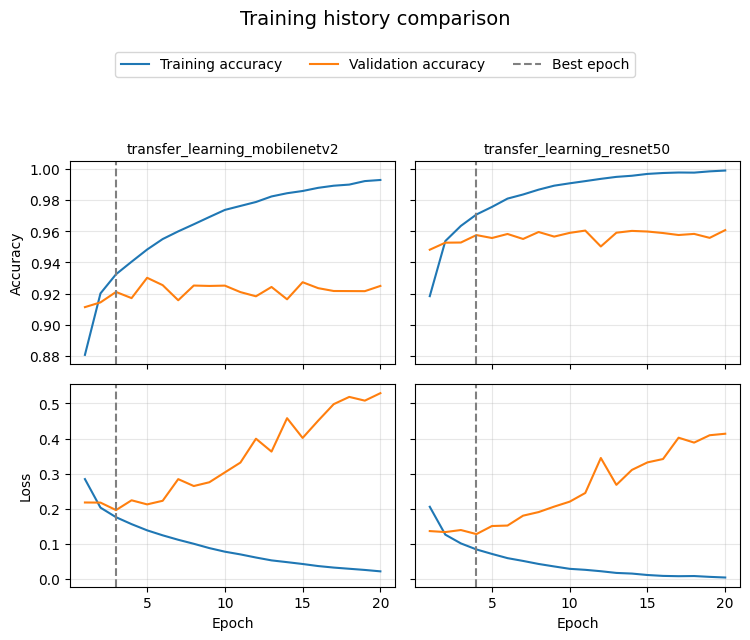

In [69]:
# Evolución de accuracy y loss
plot_training_history(transfer_learning_experiments)

In [70]:
transfer_results = get_results_table(transfer_learning_experiments)

transfer_columns = [
    "experiment",
    "val_loss",
    "val_accuracy",
    "val_precision",
    "val_recall",
    "val_f1_real",
    "val_macro_f1",
    "best_epoch",
    "parameters",
    "trainable_parameters",
    "training_seconds"
]

display(transfer_results[transfer_columns])

,experiment,val_loss,val_accuracy,val_precision,val_recall,val_f1_real,val_macro_f1,best_epoch,parameters,trainable_parameters,training_seconds
0,transfer_learning_resnet50,0.127637,0.957447,0.966966,0.9484,0.957593,0.957446,4,23850113,262401,21251.634013
1,transfer_learning_mobilenetv2,0.196055,0.921023,0.902912,0.9458,0.923858,0.920914,3,2422081,164097,6986.085768


### 5.3.4. Análisis de los resultados

Los resultados muestran una diferencia significativa entre ambas arquitecturas. ResNet50 obtiene una accuracy del 95.74 % y un Macro F1 del 95.74 %, frente al 92.10 % y 92.09 % alcanzados por MobileNetV2, respectivamente. También presenta una menor pérdida de validación (0.1276 frente a 0.1961) y una precision superior para la clase REAL.

En cuanto al recall, ambos modelos presentan valores próximos, ligeramente superiores en ResNet50. En conjunto, estas métricas indican que las características extraídas por ResNet50 permiten distinguir con mayor precisión las imágenes reales de las generadas artificialmente en este conjunto de datos.

Sin embargo, esta mejora tiene un coste computacional considerable. ResNet50 cuenta con aproximadamente 23.85 millones de parámetros, frente a los 2.42 millones de MobileNetV2, y su tiempo de entrenamiento ha sido aproximadamente tres veces superior. A pesar de ello, el número de parámetros realmente entrenables durante esta fase es reducido en ambos casos, ya que los extractores convolucionales permanecen congelados y únicamente se actualiza la cabeza de clasificación.

El análisis de las curvas de aprendizaje permite identificar un comportamiento de sobreajuste en las dos arquitecturas. La accuracy de entrenamiento aumenta progresivamente hasta aproximarse al 100 %, mientras que la accuracy de validación permanece prácticamente estancada. Al mismo tiempo, la pérdida de validación presenta una tendencia creciente, especialmente pronunciada en MobileNetV2.

La mejor época de validación corresponde a la cuarta para ResNet50 y a la tercera para MobileNetV2. Esto indica que el entrenamiento de las nuevas capas de clasificación alcanza rápidamente su mejor rendimiento y que prolongarlo sin modificar los extractores preentrenados no proporciona mejoras adicionales.

En conclusión, **ResNet50 ofrece mejores resultados que MobileNetV2 durante Transfer Learning**, aunque presenta un mayor coste computacional. Asimismo, las curvas muestran que la utilización de las características preentrenadas sin adaptarlas al nuevo problema presenta ciertas limitaciones de generalización. Por este motivo, resulta de interés estudiar si mediante Fine-Tuning es posible adaptar las capas finales de ambas arquitecturas y mejorar su rendimiento sobre el conjunto de validación.

## 5.4. Fine-Tuning

Una vez completada la fase de Transfer Learning, se procede a estudiar si la adaptación de las capas finales de las arquitecturas preentrenadas permite mejorar los resultados de clasificación.

Durante Transfer Learning, los extractores convolucionales permanecían congelados y únicamente se entrenaba la nueva cabeza de clasificación. En esta segunda fase se partirá de los mejores pesos obtenidos en los experimentos anteriores y se permitirá actualizar una parte del extractor convolucional.

Concretamente, se desbloqueará inicialmente el 25 % final de las capas de MobileNetV2 y ResNet50, manteniendo congelado el resto de cada arquitectura. De esta forma, las primeras capas conservarán las características visuales generales aprendidas sobre ImageNet, mientras que las capas más profundas podrán adaptar sus representaciones al conjunto de imágenes CIFAKE.

Para evitar modificar bruscamente los pesos preentrenados, se reducirá la tasa de aprendizaje de 0.001 a 0.00001. Se mantendrá el optimizador RMSprop y se realizarán 20 épocas adicionales de entrenamiento para cada arquitectura.

Las capas Batch Normalization pertenecientes a los extractores preentrenados permanecerán congeladas durante esta fase. Asimismo, se mantendrá su funcionamiento en modo inferencia, evitando actualizar las estadísticas internas de normalización durante el entrenamiento.

El objetivo será comprobar si esta adaptación parcial permite mejorar el rendimiento respecto a la fase de Transfer Learning. Para ello, se analizará la evolución completa de las métricas de entrenamiento y validación durante las 20 épocas adicionales.

Finalmente, se conservarán los pesos correspondientes a la menor pérdida de validación obtenida considerando conjuntamente ambas fases. Así, si Fine-Tuning no consigue mejorar el resultado de Transfer Learning, se mantendrá el modelo anterior.

### 5.4.1. Configuración del entrenamiento

Para la fase de Fine-Tuning se establecen 20 épocas adicionales de entrenamiento y una tasa de aprendizaje de 0.00001, considerablemente inferior a la utilizada durante Transfer Learning. Esta reducción permite realizar ajustes graduales sobre los pesos preentrenados, evitando modificaciones demasiado bruscas de las características previamente aprendidas.

Se establece inicialmente que el 25 % final de las capas del extractor convolucional sea entrenable, manteniendo congeladas las capas anteriores. Esta configuración permite adaptar las características más profundas al problema de clasificación sin modificar la totalidad de la arquitectura.

In [71]:
# Número de épocas adicionales de Fine-Tuning
FINE_TUNE_EPOCHS = 20

# Learning rate reducido para adaptar los pesos preentrenados
FINE_TUNING_LEARNING_RATE = 0.00001

# Proporción de capas finales que se desbloquearán
UNFREEZE_FRACTION = 0.25

print("Fine-Tuning epochs:", FINE_TUNE_EPOCHS)
print("Fine-Tuning learning rate:", FINE_TUNING_LEARNING_RATE)
print("Unfreeze fraction:", UNFREEZE_FRACTION)

Fine-Tuning epochs: 20
Fine-Tuning learning rate: 1e-05
Unfreeze fraction: 0.25


### 5.4.2. Desbloqueo de las capas finales

A continuación se comprueba cómo se distribuyen las capas entrenables de MobileNetV2 y ResNet50 al aplicar la estrategia de Fine-Tuning. Para ello, se construyen ambas arquitecturas desbloqueando el 25 % final de las capas del extractor convolucional y se contabilizan las capas y los parámetros que podrán actualizarse durante el entrenamiento.

Además, se inspeccionan las primeras y últimas capas desbloqueadas para verificar que la selección se ha aplicado correctamente. Se comprueba también que todas las capas Batch Normalization permanecen congeladas, evitando modificar sus parámetros y estadísticas internas durante la adaptación de los modelos. Esta comprobación permite confirmar que ambas arquitecturas están configuradas de acuerdo con la estrategia de Fine-Tuning definida.

In [72]:
for architecture in PRETRAINED_ARCHITECTURES:

    print(f"\n{'=' * 65}")
    print(f"Configuración de Fine-Tuning: {architecture}")
    print(f"{'=' * 65}")

    model, backbone = build_pretrained_classifier(
        architecture,
        unfreeze_fraction=UNFREEZE_FRACTION
    )

    total_backbone_layers = len(backbone.layers)

    trainable_backbone_layers = [
        layer for layer in backbone.layers
        if layer.trainable
    ]

    trainable_non_bn_layers = [
        layer for layer in trainable_backbone_layers
        if not isinstance(
            layer,
            tf.keras.layers.BatchNormalization
        )
    ]

    trainable_parameters = sum(
        int(np.prod(variable.shape))
        for variable in model.trainable_variables
    )

    print("Número total de capas del extractor:", total_backbone_layers)

    print("Número de capas entrenables del extractor:", len(trainable_backbone_layers))

    print(
        "Número de capas entrenables (excluyendo Batch Normalization):",
        len(trainable_non_bn_layers)
    )

    print(
        "Número de parámetros entrenables (incluyendo el clasificador):",
        trainable_parameters
    )

    print("\nPrimeras capas entrenables:")

    for layer in trainable_backbone_layers[:10]:
        print(layer.name, type(layer).__name__)

    print("\nÚltimas capas entrenables:")

    for layer in trainable_backbone_layers[-10:]:
        print(layer.name, type(layer).__name__)

    # Comprobar que ninguna capa Batch Normalization está entrenable
    assert all(
        not layer.trainable
        for layer in backbone.layers
        if isinstance(
            layer,
            tf.keras.layers.BatchNormalization
        )
    )

    print("\nComprobación correcta: todas las capas Batch Normalization están congeladas.")

    del model, backbone
    tf.keras.backend.clear_session()


Configuración de Fine-Tuning: MobileNetV2
Número total de capas del extractor: 154
Número de capas entrenables del extractor: 26
Número de capas entrenables (excluyendo Batch Normalization): 26
Número de parámetros entrenables (incluyendo el clasificador): 1827457

Primeras capas entrenables:
block_12_add Add
block_13_expand Conv2D
block_13_expand_relu ReLU
block_13_pad ZeroPadding2D
block_13_depthwise DepthwiseConv2D
block_13_depthwise_relu ReLU
block_13_project Conv2D
block_14_expand Conv2D
block_14_expand_relu ReLU
block_14_depthwise DepthwiseConv2D

Últimas capas entrenables:
block_15_depthwise_relu ReLU
block_15_project Conv2D
block_15_add Add
block_16_expand Conv2D
block_16_expand_relu ReLU
block_16_depthwise DepthwiseConv2D
block_16_depthwise_relu ReLU
block_16_project Conv2D
Conv_1 Conv2D
out_relu ReLU

Comprobación correcta: todas las capas Batch Normalization están congeladas.

Configuración de Fine-Tuning: ResNet50
Número total de capas del extractor: 175
Número de capas en

### 5.4.3. Implementación del entrenamiento

Para ejecutar el Fine-Tuning se implementa una función que integra todo el proceso de adaptación de cada arquitectura. En primer lugar, se recuperan los mejores pesos obtenidos durante Transfer Learning y se cargan en el modelo con las capas finales desbloqueadas. A continuación, se recompila utilizando RMSprop y la tasa de aprendizaje reducida definida anteriormente, y se realiza el entrenamiento durante las 20 épocas adicionales.

Se implementa también un callback específico que monitoriza la pérdida de validación considerando conjuntamente las dos fases de entrenamiento. De esta forma, se conservan los pesos que proporcionan el menor valor de dicha métrica y, si Fine-Tuning no consigue mejorar el resultado de Transfer Learning, se recuperan automáticamente los pesos de la fase anterior.

Finalmente, se evalúa el mejor modelo obtenido y se almacenan en memoria sus métricas, pesos e historial completo de entrenamiento. También se registra el tiempo empleado tanto en Fine-Tuning como en el proceso acumulado de ambas fases, permitiendo analizar posteriormente el rendimiento y el coste computacional de cada arquitectura.

In [73]:
class BestWeightsAcrossPhases(tf.keras.callbacks.Callback):

    def __init__(
        self,
        initial_val_loss,
        initial_weights,
        initial_best_epoch
    ):

        super().__init__()

        self.best_val_loss = float(initial_val_loss)

        self.best_weights = [
            np.array(w, copy=True)
            for w in initial_weights
        ]

        self.best_epoch = int(initial_best_epoch)

    def on_epoch_end(self, epoch, logs=None):

        logs = logs or {}

        current_val_loss = logs.get("val_loss")

        if current_val_loss is None:
            return

        current_val_loss = float(current_val_loss)

        if current_val_loss < self.best_val_loss:

            self.best_val_loss = current_val_loss

            # epoch ya tiene en cuenta initial_epoch
            self.best_epoch = epoch + 1

            self.best_weights = [
                np.array(w, copy=True)
                for w in self.model.get_weights()
            ]

    def on_train_end(self, logs=None):

        if self.best_weights is None:
            raise RuntimeError(
                "No se dispone de pesos válidos."
            )

        # Restaurar el mejor modelo de ambas fases
        self.model.set_weights(self.best_weights)

In [74]:
def run_pretrained_fine_tuning(
    architecture,
    train_dataset,
    val_dataset,
    epochs=FINE_TUNE_EPOCHS,
    unfreeze_fraction=UNFREEZE_FRACTION
):

    transfer_experiment = (f"transfer_learning_{architecture.lower()}")

    fine_tuning_experiment = (f"fine_tuning_{architecture.lower()}")

    # --------------------------------------------------
    # 1. Recuperar el modelo de Transfer Learning
    # --------------------------------------------------

    if transfer_experiment not in experiment_best_weights:
        raise ValueError(f"No existen pesos de Transfer Learning para {architecture}.")

    initial_weights = experiment_best_weights[transfer_experiment]

    initial_metrics = experiment_metrics[transfer_experiment]

    initial_val_loss = initial_metrics["val_loss"]
    initial_best_epoch = initial_metrics["best_epoch"]

    transfer_epochs = experiment_configs[transfer_experiment]["epochs"]

    transfer_training_seconds = initial_metrics["training_seconds"]

    transfer_history = experiment_histories[transfer_experiment]

    # --------------------------------------------------
    # 2. Construcción del modelo parcialmente desbloqueado
    # --------------------------------------------------

    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)

    model, backbone = build_pretrained_classifier(
        architecture,
        unfreeze_fraction=unfreeze_fraction
    )

    # Recuperar los mejores pesos de Transfer Learning
    model.set_weights(initial_weights)

    # --------------------------------------------------
    # 3. Recompilación con learning rate reducido
    # --------------------------------------------------

    compile_pretrained_model(model, learning_rate=FINE_TUNING_LEARNING_RATE)

    # --------------------------------------------------
    # 4. Callback de mejores pesos entre ambas fases
    # --------------------------------------------------

    best_weights_callback = BestWeightsAcrossPhases(
        initial_val_loss=initial_val_loss,
        initial_weights=initial_weights,
        initial_best_epoch=initial_best_epoch
    )

    # --------------------------------------------------
    # 5. Información del modelo
    # --------------------------------------------------

    trainable_parameters = sum(
        int(np.prod(variable.shape))
        for variable in model.trainable_variables
    )

    print("\n" + "=" * 70)
    print(f"FINE-TUNING: {architecture}")
    print("=" * 70)

    print("Transfer Learning best epoch:", initial_best_epoch)
    print("Initial validation loss:", initial_val_loss)
    print("Fine-Tuning epochs:", epochs)
    print("Learning rate:", FINE_TUNING_LEARNING_RATE)
    print("Unfreeze fraction:", unfreeze_fraction)
    print("Total parameters:", model.count_params())
    print("Trainable parameters:", trainable_parameters)

    # --------------------------------------------------
    # 6. Entrenamiento completo de Fine-Tuning
    # --------------------------------------------------

    start_time = time.perf_counter()

    fine_tuning_history = model.fit(
        train_dataset,
        validation_data=val_dataset,

        # Las épocas continúan desde Transfer Learning
        initial_epoch=transfer_epochs,

        # Se entrenan todas las épocas adicionales
        epochs=transfer_epochs + epochs,

        # Solo conserva pesos; NO detiene el entrenamiento
        callbacks=[best_weights_callback],

        verbose=2
    )

    fine_tuning_seconds = time.perf_counter() - start_time

    total_training_seconds = (transfer_training_seconds + fine_tuning_seconds)

    # Los mejores pesos de ambas fases ya están restaurados

    # --------------------------------------------------
    # 7. Evaluación del mejor modelo
    # --------------------------------------------------

    final_metrics = evaluate_pretrained_model(model, val_dataset)

    # --------------------------------------------------
    # 8. Combinar historiales de ambas fases
    # --------------------------------------------------

    fine_history = fine_tuning_history.history

    combined_history = {}

    for key, values in transfer_history.items():

        combined_history[key] = (list(values) + list(fine_history[key]))

    # --------------------------------------------------
    # 9. Almacenar resultados
    # --------------------------------------------------

    results = {
        "experiment": fine_tuning_experiment,

        **final_metrics,

        "best_epoch": int(
            best_weights_callback.best_epoch
        ),

        "parameters": int(model.count_params()),

        "trainable_parameters": int(
            trainable_parameters
        ),

        # Tiempo acumulado de TL + Fine-Tuning
        "training_seconds": float(
            total_training_seconds
        ),

        # Tiempo empleado únicamente en Fine-Tuning
        "fine_tuning_seconds": float(
            fine_tuning_seconds
        )
    }

    experiment_metrics[fine_tuning_experiment] = results

    experiment_histories[fine_tuning_experiment] = {
        key: [float(value) for value in values]
        for key, values in combined_history.items()
    }

    experiment_configs[fine_tuning_experiment] = {
        "architecture": architecture,
        "phase": "fine_tuning",
        "image_size": PRETRAINED_IMAGE_SIZE,
        "batch_size": PRETRAINED_BATCH_SIZE,
        "transfer_epochs": transfer_epochs,
        "fine_tuning_epochs": epochs,
        "optimizer": "RMSprop",
        "learning_rate": FINE_TUNING_LEARNING_RATE,
        "unfreeze_fraction": unfreeze_fraction
    }

    experiment_best_weights[fine_tuning_experiment] = [
        np.array(w, copy=True)
        for w in model.get_weights()
    ]

    # El historial contiene desde la época 1 hasta la 40
    experiment_epoch_offsets[fine_tuning_experiment] = 0

    print("\nResultados finales:")
    print(pd.Series(results))

    # --------------------------------------------------
    # 10. Liberar memoria
    # --------------------------------------------------

    del model, backbone, fine_tuning_history

    gc.collect()
    tf.keras.backend.clear_session()

    return results

### 5.4.4. Ejecución del Fine-Tuning

Una vez definida la función de entrenamiento, se ejecuta el proceso de Fine-Tuning para MobileNetV2 y ResNet50, utilizando en ambos casos los conjuntos de entrenamiento y validación preparados anteriormente. Cada arquitectura parte de los mejores pesos obtenidos durante su correspondiente fase de Transfer Learning y se entrena durante 20 épocas adicionales, desbloqueando el 25 % final de las capas del extractor convolucional.

Los resultados de cada experimento se almacenan en una lista para facilitar su posterior análisis y comparación. De esta forma, se obtiene el historial completo de entrenamiento de ambas arquitecturas, junto con las métricas correspondientes a sus mejores pesos seleccionados mediante la pérdida de validación.

In [75]:
fine_tuning_experiments = []

for architecture in PRETRAINED_ARCHITECTURES:

    train_dataset = pretrained_datasets[architecture]["train"]
    val_dataset = pretrained_datasets[architecture]["val"]

    results = run_pretrained_fine_tuning(
        architecture=architecture,
        train_dataset=train_dataset,
        val_dataset=val_dataset,
        epochs=FINE_TUNE_EPOCHS,
        unfreeze_fraction=UNFREEZE_FRACTION
    )

    fine_tuning_experiments.append(f"fine_tuning_{architecture.lower()}")


FINE-TUNING: MobileNetV2
Transfer Learning best epoch: 3
Initial validation loss: 0.19605502486228943
Fine-Tuning epochs: 20
Learning rate: 1e-05
Unfreeze fraction: 0.25
Total parameters: 2422081
Trainable parameters: 1827457
Epoch 21/40


c:\Users\angel\AppData\Local\Programs\Python\Python314\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


2468/2468 - 485s - 197ms/step - accuracy: 0.9468 - f1_real: 0.9477 - loss: 0.1391 - precision: 0.9444 - recall: 0.9510 - val_accuracy: 0.9406 - val_f1_real: 0.9404 - val_loss: 0.1587 - val_precision: 0.9554 - val_recall: 0.9259
Epoch 22/40
2468/2468 - 474s - 192ms/step - accuracy: 0.9612 - f1_real: 0.9618 - loss: 0.1035 - precision: 0.9600 - recall: 0.9635 - val_accuracy: 0.9220 - val_f1_real: 0.9275 - val_loss: 0.2118 - val_precision: 0.8765 - val_recall: 0.9848
Epoch 23/40
2468/2468 - 477s - 193ms/step - accuracy: 0.9690 - f1_real: 0.9694 - loss: 0.0824 - precision: 0.9677 - recall: 0.9711 - val_accuracy: 0.9533 - val_f1_real: 0.9542 - val_loss: 0.1333 - val_precision: 0.9491 - val_recall: 0.9593
Epoch 24/40
2468/2468 - 475s - 193ms/step - accuracy: 0.9748 - f1_real: 0.9752 - loss: 0.0675 - precision: 0.9736 - recall: 0.9767 - val_accuracy: 0.9515 - val_f1_real: 0.9529 - val_loss: 0.1357 - val_precision: 0.9372 - val_recall: 0.9691
Epoch 25/40
2468/2468 - 464s - 188ms/step - accuracy

c:\Users\angel\AppData\Local\Programs\Python\Python314\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


2468/2468 - 1611s - 653ms/step - accuracy: 0.9802 - f1_real: 0.9805 - loss: 0.0550 - precision: 0.9806 - recall: 0.9804 - val_accuracy: 0.9653 - val_f1_real: 0.9653 - val_loss: 0.1142 - val_precision: 0.9788 - val_recall: 0.9521
Epoch 22/40
2468/2468 - 1578s - 639ms/step - accuracy: 0.9935 - f1_real: 0.9935 - loss: 0.0185 - precision: 0.9936 - recall: 0.9935 - val_accuracy: 0.9597 - val_f1_real: 0.9613 - val_loss: 0.1451 - val_precision: 0.9360 - val_recall: 0.9881
Epoch 23/40
2468/2468 - 1565s - 634ms/step - accuracy: 0.9978 - f1_real: 0.9978 - loss: 0.0064 - precision: 0.9978 - recall: 0.9979 - val_accuracy: 0.9674 - val_f1_real: 0.9684 - val_loss: 0.1431 - val_precision: 0.9525 - val_recall: 0.9848
Epoch 24/40
2468/2468 - 1572s - 637ms/step - accuracy: 0.9992 - f1_real: 0.9992 - loss: 0.0026 - precision: 0.9992 - recall: 0.9993 - val_accuracy: 0.9707 - val_f1_real: 0.9713 - val_loss: 0.1361 - val_precision: 0.9644 - val_recall: 0.9782
Epoch 25/40
2468/2468 - 1583s - 641ms/step - acc

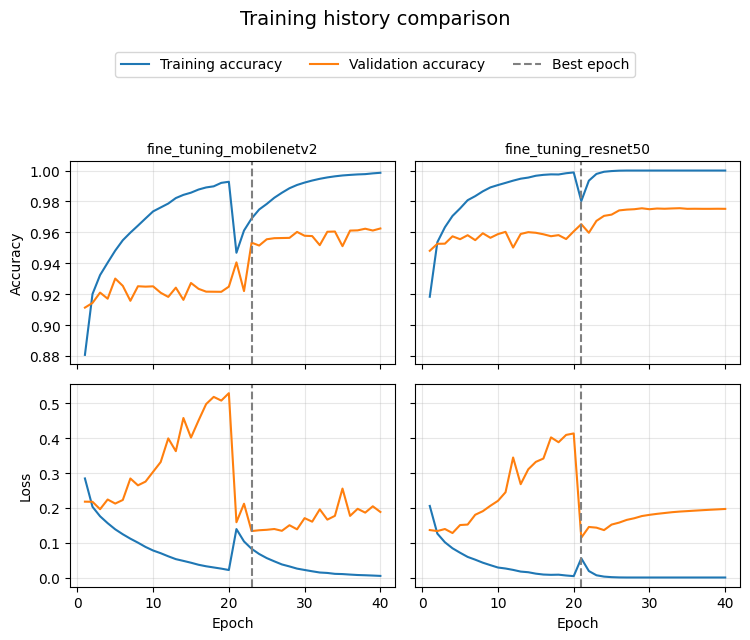

In [80]:
# Evolución de accuracy y loss
plot_training_history(fine_tuning_experiments)

In [82]:
finetuning_results = get_results_table(fine_tuning_experiments)

comparison_columns = [
    "experiment",
    "val_loss",
    "val_accuracy",
    "val_precision",
    "val_recall",
    "val_f1_real",
    "val_macro_f1",
    "best_epoch",
    "parameters",
    "trainable_parameters",
    "training_seconds"
]

display(finetuning_results[comparison_columns])

,experiment,val_loss,val_accuracy,val_precision,val_recall,val_f1_real,val_macro_f1,best_epoch,parameters,trainable_parameters,training_seconds
0,fine_tuning_resnet50,0.114232,0.965299,0.978822,0.9521,0.965276,0.965299,21,23850113,16331521,53704.254898
1,fine_tuning_mobilenetv2,0.133281,0.953343,0.949144,0.9593,0.954195,0.953327,23,2422081,1827457,16435.921568


Los resultados obtenidos tras aplicar Fine-Tuning muestran que ResNet50 alcanza un mejor rendimiento que MobileNetV2, con una accuracy del 96.53 % y un Macro F1 del 96.53 %, frente al 95.33 % y 95.33 % de MobileNetV2. ResNet50 también presenta una menor pérdida de validación (0.1142 frente a 0.1333) y una mayor precisión para la clase REAL (97.88 % frente a 94.91 %). MobileNetV2 obtiene, en cambio, un recall ligeramente superior (95.93 % frente a 95.21 %). El análisis de las curvas muestra que, al comenzar el Fine-Tuning en la época 21, se produce una reducción pronunciada de la pérdida de validación en ambas arquitecturas. Los mejores resultados según este criterio se alcanzan en la época 23 para MobileNetV2 y en la época 21 para ResNet50. Durante las épocas posteriores, la accuracy de entrenamiento continúa aumentando hasta aproximarse al 100 %, mientras que la pérdida de entrenamiento disminuye progresivamente. Sin embargo, la pérdida de validación presenta oscilaciones y una tendencia creciente después de la mejora inicial, lo que evidencia que sigue existiendo cierto sobreajuste. En particular, ResNet50 mantiene una accuracy de validación elevada durante las últimas épocas, aunque su pérdida aumenta progresivamente, lo que indica que una proporción de las predicciones incorrectas puede estar realizándose con mayor confianza. En conjunto, ResNet50 ofrece los mejores resultados de clasificación entre las dos arquitecturas, aunque ambas presentan indicios de sobreajuste moderado durante el entrenamiento prolongado.

## 5.5. Comparación entre transfer learning y fine-tuning

Para finalizar esta sección, se realiza una comparación entre los resultados obtenidos con transfer learning y con fine-tuning.

In [83]:
all_pretrained_experiments = (transfer_learning_experiments + fine_tuning_experiments)

pretrained_results = get_results_table(all_pretrained_experiments)

comparison_columns = [
    "experiment",
    "val_loss",
    "val_accuracy",
    "val_precision",
    "val_recall",
    "val_f1_real",
    "val_macro_f1",
    "best_epoch",
    "parameters",
    "trainable_parameters",
    "training_seconds"
]

display(pretrained_results[comparison_columns])

,experiment,val_loss,val_accuracy,val_precision,val_recall,val_f1_real,val_macro_f1,best_epoch,parameters,trainable_parameters,training_seconds
0,fine_tuning_resnet50,0.114232,0.965299,0.978822,0.9521,0.965276,0.965299,21,23850113,16331521,53704.254898
1,transfer_learning_resnet50,0.127637,0.957447,0.966966,0.9484,0.957593,0.957446,4,23850113,262401,21251.634013
2,fine_tuning_mobilenetv2,0.133281,0.953343,0.949144,0.9593,0.954195,0.953327,23,2422081,1827457,16435.921568
3,transfer_learning_mobilenetv2,0.196055,0.921023,0.902912,0.9458,0.923858,0.920914,3,2422081,164097,6986.085768


La comparación de las dos fases de entrenamiento permite comprobar que el Fine-Tuning mejora el rendimiento de ambas arquitecturas preentrenadas. En MobileNetV2, la accuracy aumenta del 92.10 % al 95.33 % y el Macro F1 pasa del 92.09 % al 95.33 %, mientras que la pérdida de validación disminuye de 0.1961 a 0.1333. Esta mejora es especialmente significativa y demuestra que adaptar las características extraídas por la red al problema de clasificación permite aprovechar mejor los pesos preentrenados. En ResNet50 también se obtiene una mejora, aunque más moderada, puesto que ya partía de unos resultados superiores durante Transfer Learning. La accuracy aumenta del 95.74 % al 96.53 % y el Macro F1 del 95.74 % al 96.53 %, mientras que la pérdida de validación se reduce aproximadamente un 10 %. Por tanto, el Fine-Tuning mejora todas las métricas de clasificación consideradas en ambas arquitecturas, aunque su impacto es mayor en MobileNetV2. Comparando los cuatro experimentos, ResNet50 con Fine-Tuning obtiene los mejores resultados globales, alcanzando una accuracy y un Macro F1 del 96.53 %, además de una precision del 97.88 %. MobileNetV2 con Fine-Tuning constituye una alternativa con resultados próximos y un recall ligeramente superior, pero no alcanza el mismo rendimiento global. Estos resultados ponen de manifiesto la importancia de adaptar parcialmente las características aprendidas sobre ImageNet al dominio del problema. En consecuencia, se selecciona ResNet50 con Fine-Tuning como la configuración candidata más prometedora de esta estrategia, si bien su superioridad deberá confirmarse mediante la evaluación independiente sobre el conjunto de test.

# 6. Evaluación final y comparación de estrategias

## 6.1. Selección de los modelos para evaluación

Una vez completado el diseño y entrenamiento de las dos estrategias, se realiza la evaluación final de los modelos seleccionados utilizando el conjunto de test, que ha permanecido completamente separado durante las fases de entrenamiento y validación.

El objetivo de esta sección es comparar la capacidad de generalización de la CNN entrenada desde cero y de la arquitectura preentrenada mediante Transfer Learning y Fine-Tuning. Para ello, se seleccionan las mejores configuraciones identificadas durante las secciones anteriores: la CNN con Batch Normalization y ResNet50 con Fine-Tuning.

La selección de estos modelos se ha realizado utilizando exclusivamente el conjunto de validación y conservando los pesos correspondientes a la menor pérdida de validación. Por tanto, el conjunto de test se utilizará únicamente para obtener una estimación independiente de su rendimiento, sin realizar ajustes adicionales de arquitectura, hiperparámetros o umbrales de clasificación.

Ambos modelos se evaluarán utilizando las mismas métricas: pérdida, accuracy, precision, recall, F1-score de la clase REAL y Macro F1. También se analizarán sus matrices de confusión para estudiar los errores de clasificación cometidos por cada estrategia.

Finalmente, se compararán los resultados obtenidos con los valores de validación para estudiar posibles diferencias en la capacidad de generalización y determinar qué estrategia proporciona la solución más adecuada para el conjunto de datos seleccionado.

## 6.2. Preparación del conjunto de test y de los modelos

### 6.2.1. Preparación del conjunto de test

Se preparan los datasets de test correspondientes a cada arquitectura, respetando exactamente el preprocesamiento utilizado durante su entrenamiento.

Para la CNN entrenada desde cero se mantienen las dimensiones originales de 32 × 32 píxeles y la normalización integrada en el propio modelo. Para ResNet50, las imágenes se redimensionan a 128 × 128 píxeles y se aplica el preprocesamiento específico de esta arquitectura.

En ambos casos se utiliza el conjunto de test depurado definido durante la preparación de los datos, sin aplicar mezclas aleatorias ni transformaciones de aumento de datos. Finalmente, se agrupan las imágenes en batches y se comprueba la distribución de las clases para verificar que el conjunto utilizado en la evaluación es el esperado.





In [84]:
# Recuperar las etiquetas del conjunto de test
test_labels = np.array([label for _, label in test_records], dtype=int)

test_class_counts = {
    "FAKE": int(np.sum(test_labels == 0)),
    "REAL": int(np.sum(test_labels == 1))
}

print("Número total de imágenes de test:", len(test_records))
print("Distribución de las clases:", test_class_counts)

Número total de imágenes de test: 19962
Distribución de las clases: {'FAKE': 9962, 'REAL': 10000}


In [85]:
test_cnn_dataset = (create_dataset(test_records, shuffle=False).batch(REFERENCE_BATCH_SIZE).prefetch(AUTOTUNE))

Se crea un dataset de test específico para ResNet50, aplicando exactamente el mismo redimensionamiento y preprocesamiento utilizados durante su entrenamiento. De esta forma, se garantiza que las imágenes de evaluación tengan las mismas características de entrada que las utilizadas para entrenar el modelo.

In [86]:
def create_pretrained_test_dataset(
    architecture,
    batch_size=PRETRAINED_BATCH_SIZE
):

    preprocess_input = get_preprocessing_function(architecture)

    def preprocess_image(image, label):

        image = tf.image.resize(
            image,
            PRETRAINED_IMAGE_SIZE,
            method="bilinear",
            antialias=True
        )

        image = preprocess_input(image)

        image = tf.ensure_shape(
            image,
            (
                PRETRAINED_IMAGE_SIZE[0],
                PRETRAINED_IMAGE_SIZE[1],
                3
            )
        )

        return image, label

    test_dataset = create_dataset(
        test_records,
        shuffle=False
    )

    test_dataset = test_dataset.map(
        preprocess_image,
        num_parallel_calls=AUTOTUNE,
        deterministic=True
    )

    test_dataset = (
        test_dataset
        .batch(batch_size)
        .prefetch(AUTOTUNE)
    )

    return test_dataset


test_resnet_dataset = create_pretrained_test_dataset("ResNet50")

### 6.2.2. Reconstrucción de los modelos seleccionados

A continuación se reconstruyen los dos modelos utilizando las mismas arquitecturas y configuraciones empleadas durante el entrenamiento. Se recuperan los pesos almacenados en experiment_best_weights, sin realizar ninguna actualización adicional de sus parámetros.

Para la CNN creada desde cero se utiliza la configuración de referencia modificada para incorporar Batch Normalization.

In [87]:
CNN_FINAL_EXPERIMENT = "regularization_batch_norm"

# Recuperar la configuración de la CNN seleccionada
cnn_final_config = REFERENCE_CONFIG.copy()

cnn_final_config.update({
    "batch_normalization": True,
    "data_augmentation": None,
    "dropout_rate": 0.0,
    "l2_strength": 0.0
})

# Construir la arquitectura
cnn_final_model = build_cnn(**cnn_final_config)

# Recuperar los mejores pesos obtenidos durante el entrenamiento
cnn_final_model.set_weights(experiment_best_weights[CNN_FINAL_EXPERIMENT])

print("CNN desde cero reconstruida correctamente.")
print("Parámetros totales:", cnn_final_model.count_params())

CNN desde cero reconstruida correctamente.
Parámetros totales: 110945


Para ResNet50 se reconstruye el extractor con el mismo porcentaje de capas desbloqueadas empleado durante Fine-Tuning.

In [88]:
RESNET_FINAL_EXPERIMENT = "fine_tuning_resnet50"

# Reconstruir ResNet50 con la configuración de Fine-Tuning
resnet_final_model, resnet_final_backbone = (
    build_pretrained_classifier(
        "ResNet50",
        unfreeze_fraction=UNFREEZE_FRACTION
    )
)

# Recuperar los mejores pesos obtenidos durante Fine-Tuning
resnet_final_model.set_weights(
    experiment_best_weights[RESNET_FINAL_EXPERIMENT]
)

# Compilar para poder calcular las métricas durante la evaluación
compile_pretrained_model(
    resnet_final_model,
    learning_rate=FINE_TUNING_LEARNING_RATE
)

print("ResNet50 con Fine-Tuning reconstruida correctamente.")
print("Parámetros totales:", resnet_final_model.count_params())

ResNet50 con Fine-Tuning reconstruida correctamente.
Parámetros totales: 23850113


## 6.3. Evaluación sobre el conjunto de test

Se implementa una función común para evaluar los modelos seleccionados sobre el conjunto de test, sin realizar ninguna actualización de sus pesos. En primer lugar, se calculan las métricas de Keras (pérdida, accuracy, precision, recall y F1-score de la clase REAL). A continuación, se obtienen las probabilidades predichas y se convierten en etiquetas de clasificación utilizando el umbral de 0.5 establecido anteriormente.

A partir de estas predicciones se calcula el Macro F1 mediante scikit-learn, teniendo en cuenta el rendimiento de ambas clases. Asimismo, se incorpora la métrica ROC AUC, que permite evaluar la capacidad de discriminación del modelo considerando distintos umbrales de clasificación.

Finalmente, la función devuelve tanto las métricas obtenidas como las etiquetas reales, las clases predichas y las probabilidades estimadas. Esta información se utilizará posteriormente para analizar los errores mediante las matrices de confusión y comparar la capacidad de discriminación de los modelos mediante las curvas ROC.

In [89]:
from sklearn.metrics import (
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve
)


def evaluate_final_model(model, test_dataset):

    # Evaluación mediante las métricas de Keras
    keras_results = model.evaluate(
        test_dataset,
        verbose=0,
        return_dict=True
    )

    # Recuperar las etiquetas reales
    y_true = np.concatenate([
        labels.numpy().reshape(-1)
        for _, labels in test_dataset
    ]).astype(int)

    # Obtener probabilidades predichas
    y_prob = model.predict(
        test_dataset,
        verbose=0
    ).reshape(-1)

    # Clasificación utilizando el umbral establecido
    y_pred = (y_prob >= 0.5).astype(int)

    # Calcular Macro F1
    macro_f1 = f1_score(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    )

    # Calcular ROC AUC
    roc_auc = roc_auc_score(
        y_true,
        y_prob
    )

    # Recopilar las métricas
    metrics = {
        "test_loss": float(keras_results["loss"]),
        "test_accuracy": float(keras_results["accuracy"]),
        "test_precision": float(keras_results["precision"]),
        "test_recall": float(keras_results["recall"]),
        "test_f1_real": float(keras_results["f1_real"]),
        "test_macro_f1": float(macro_f1),
        "test_roc_auc": float(roc_auc)
    }

    predictions = {
        "y_true": y_true,
        "y_pred": y_pred,
        "y_prob": y_prob
    }

    return metrics, predictions

### 6.3.1. Ejecución de la evaluación y análisis de resultados

Se realiza la evaluación de los dos modelos seleccionados sobre sus respectivos conjuntos de test, sin modificar sus pesos. Para cada arquitectura se calculan las métricas definidas anteriormente y se almacenan tanto los resultados como las predicciones obtenidas, facilitando su posterior análisis.

Además, se genera un informe de clasificación que muestra la precision, el recall y el F1-score de cada clase por separado, junto con las métricas globales. Esto permite realizar una primera comparación del rendimiento de ambos modelos e identificar posibles diferencias en su capacidad para clasificar imágenes reales y sintéticas.

In [90]:
final_test_metrics = {}
final_test_predictions = {}

# Definir los modelos y datasets correspondientes
models_to_evaluate = {
    "CNN desde cero + Batch Normalization": (
        cnn_final_model,
        test_cnn_dataset
    ),

    "ResNet50 + Fine-Tuning": (
        resnet_final_model,
        test_resnet_dataset
    )
}

# Evaluar ambos modelos
for model_name, (model, test_dataset) in models_to_evaluate.items():

    print(f"\n{'=' * 65}")
    print(f"Evaluación sobre test: {model_name}")
    print(f"{'=' * 65}")

    metrics, predictions = evaluate_final_model(
        model,
        test_dataset
    )

    final_test_metrics[model_name] = metrics
    final_test_predictions[model_name] = predictions

    print("\nResultados:")
    for metric, value in metrics.items():
        print(f"{metric}: {value:.6f}")

    print("\nInforme de clasificación:")

    print(
        classification_report(
            predictions["y_true"],
            predictions["y_pred"],
            labels=[0, 1],
            target_names=["FAKE", "REAL"],
            digits=4,
            zero_division=0
        )
    )


Evaluación sobre test: CNN desde cero + Batch Normalization

Resultados:
test_loss: 0.137235
test_accuracy: 0.959573
test_precision: 0.969750
test_recall: 0.948900
test_f1_real: 0.959211
test_macro_f1: 0.959570
test_roc_auc: 0.992910

Informe de clasificación:
              precision    recall  f1-score   support

        FAKE     0.9498    0.9703    0.9599      9962
        REAL     0.9697    0.9489    0.9592     10000

    accuracy                         0.9596     19962
   macro avg     0.9598    0.9596    0.9596     19962
weighted avg     0.9598    0.9596    0.9596     19962


Evaluación sobre test: ResNet50 + Fine-Tuning

Resultados:
test_loss: 0.112742
test_accuracy: 0.964833
test_precision: 0.979872
test_recall: 0.949300
test_f1_real: 0.964344
test_macro_f1: 0.964827
test_roc_auc: 0.995185

Informe de clasificación:
              precision    recall  f1-score   support

        FAKE     0.9507    0.9804    0.9653      9962
        REAL     0.9799    0.9493    0.9643     10000


In [91]:
test_results_df = pd.DataFrame.from_dict(
    final_test_metrics,
    orient="index"
)

test_results_df.index.name = "Modelo"
display(test_results_df.style.format("{:.4f}"))

,test_loss,test_accuracy,test_precision,test_recall,test_f1_real,test_macro_f1,test_roc_auc
Modelo,,,,,,,
CNN desde cero + Batch Normalization,0.1372,0.9596,0.9697,0.9489,0.9592,0.9596,0.9929
ResNet50 + Fine-Tuning,0.1127,0.9648,0.9799,0.9493,0.9643,0.9648,0.9952


Los resultados obtenidos sobre el conjunto de test muestran un rendimiento elevado para ambos modelos. La CNN entrenada desde cero con Batch Normalization alcanza una accuracy del 95.96 % y un Macro F1 del 95.96 %, mientras que ResNet50 con Fine-Tuning obtiene valores del 96.48 % y 96.48 %, respectivamente. Por tanto, la arquitectura preentrenada consigue una mejora aproximada de 0.53 puntos porcentuales en ambas métricas. Asimismo, presenta una menor pérdida (0.1127 frente a 0.1372) y un ROC AUC ligeramente superior (0.9952 frente a 0.9929), lo que indica una capacidad de discriminación muy elevada entre las dos clases.

El análisis por clases permite observar que ResNet50 obtiene un recall del 98.04 % para FAKE, frente al 97.03 % de la CNN desde cero. Esto indica que identifica correctamente una mayor proporción de imágenes generadas artificialmente. Para la clase REAL, ambos modelos presentan un recall muy similar, próximo al 94.9 %, aunque ResNet50 alcanza una precision superior del 97.99 %, frente al 96.98 % de la CNN. En conjunto, estos resultados muestran que ResNet50 consigue un mejor equilibrio entre la identificación de ambas categorías.

Por otra parte, la comparación entre los resultados de validación y test muestra diferencias muy reducidas. La CNN con Batch Normalization pasa de una accuracy del 96.07 % en validación al 95.96 % en test, mientras que ResNet50 pasa del 96.53 % al 96.48 %. Estas pequeñas variaciones indican que ambos modelos mantienen un rendimiento consistente sobre datos no utilizados durante su entrenamiento ni durante la selección de sus pesos. Por tanto, no se observa una degradación significativa de su capacidad de generalización al evaluar el conjunto de test.

En conclusión, ambos modelos presentan un rendimiento satisfactorio, aunque **ResNet50 con Fine-Tuning obtiene los mejores resultados globales**, superando ligeramente a la CNN entrenada desde cero. La utilización de una arquitectura preentrenada y su posterior adaptación mediante Fine-Tuning permite obtener una mejora moderada, pero consistente, en la clasificación de imágenes reales y sintéticas.

No obstante, la mejora obtenida con ResNet50 debe valorarse teniendo en cuenta su mayor complejidad computacional. Mientras que la CNN entrenada desde cero con Batch Normalization cuenta con aproximadamente 111000 parámetros, ResNet50 dispone de cerca de 23.85 millones, es decir, más de 200 veces el número de parámetros de la primera. Esta diferencia, junto con la mayor resolución de entrada utilizada por ResNet50 (128 × 128 frente a 32 × 32), implica un modelo considerablemente más grande y una mayor demanda de recursos computacionales. Aunque es razonable esperar que esto se traduzca en un mayor coste y tiempo de inferencia, en este proyecto no se ha medido directamente la latencia de ambos modelos. Por tanto, ResNet50 ofrece las mejores métricas de clasificación, mientras que **la CNN diseñada desde cero presenta ventajas en términos de simplicidad y tamaño del modelo**, además de un menor coste computacional esperado. En consecuencia, **la elección entre ambas arquitecturas dependerá de los requisitos de la aplicación**: si se prioriza maximizar el rendimiento predictivo, ResNet50 resulta más adecuada; si se busca una solución más ligera y con menores requisitos computacionales, la CNN desde cero constituye una alternativa competitiva.


## 6.4. Análisis de errores y capacidad de discriminación 

Para profundizar en la evaluación se estudian las matrices de confusión de ambos modelos. Estas permiten identificar el número de clasificaciones correctas e incorrectas para cada clase y determinar si existe una mayor dificultad para reconocer imágenes reales o sintéticas.

Asimismo, se representan las curvas ROC y se calcula el área bajo la curva (AUC), con el objetivo de comparar la capacidad de discriminación de los modelos independientemente de un umbral de clasificación concreto.

Este análisis complementa las métricas globales y permite identificar diferencias en el comportamiento de ambas estrategias que no siempre quedan reflejadas únicamente en la accuracy.

### 6.4.1. Matrices de confusión

A continuación se muestra y analiza la matriz de confusión obtenida para ambos modelos evaluados sobre el conjunto de test.

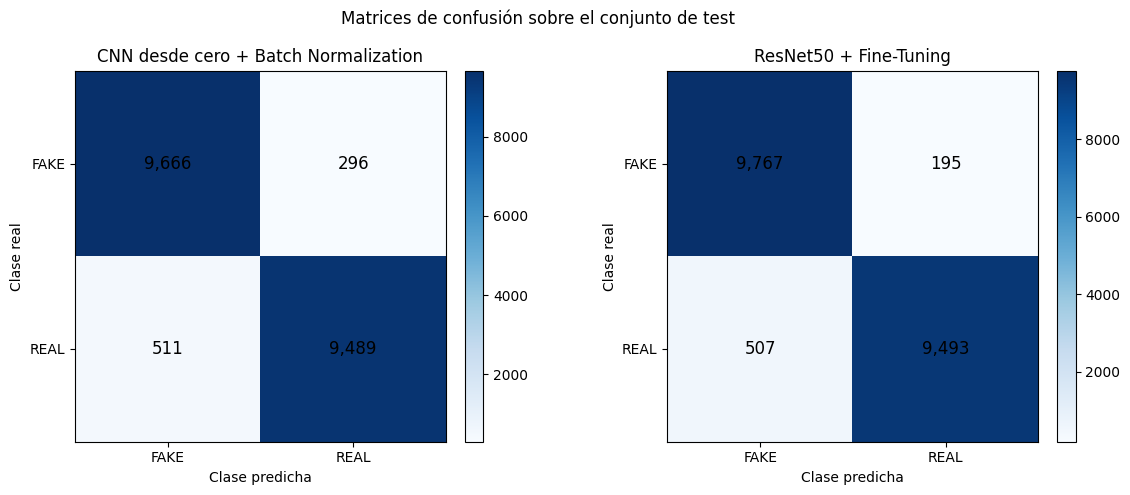

In [92]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, (model_name, predictions) in zip(
    axes,
    final_test_predictions.items()
):

    cm = confusion_matrix(
        predictions["y_true"],
        predictions["y_pred"],
        labels=[0, 1]
    )

    im = ax.imshow(cm, cmap="Blues")

    ax.set_title(model_name)
    ax.set_xlabel("Clase predicha")
    ax.set_ylabel("Clase real")

    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])

    ax.set_xticklabels(["FAKE", "REAL"])
    ax.set_yticklabels(["FAKE", "REAL"])

    # Mostrar el número de imágenes en cada celda
    for i in range(2):
        for j in range(2):

            ax.text(
                j, i,
                f"{cm[i, j]:,}",
                ha="center",
                va="center",
                color="black",
                fontsize=12
            )

    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

plt.suptitle("Matrices de confusión sobre el conjunto de test")
plt.tight_layout()
plt.show()

La matriz de confusión permite analizar con mayor detalle los aciertos y errores de clasificación de ambos modelos. En ambos casos, la mayoría de las imágenes se clasifican correctamente, como muestran los valores de la diagonal principal. Sin embargo, ResNet50 + Fine-Tuning obtiene un resultado ligeramente mejor, con 19260 clasificaciones correctas frente a las 19155 de la CNN desde cero, lo que supone 105 errores menos.

La diferencia más destacable se encuentra en la identificación de imágenes FAKE: ResNet50 clasifica incorrectamente 195 imágenes FAKE como REAL, frente a las 296 de la CNN. Por tanto, el modelo preentrenado reduce en 101 los falsos negativos de esta clase. En cambio, el número de imágenes REAL clasificadas erróneamente como FAKE es muy similar en ambos modelos: 507 en ResNet50 y 511 en la CNN. Esto indica que la mejora de ResNet50 se debe principalmente a una mayor capacidad para identificar correctamente las imágenes FAKE, mientras que el reconocimiento de imágenes REAL se mantiene prácticamente al mismo nivel.

En conjunto, ambas matrices muestran un comportamiento equilibrado, aunque ResNet50 + Fine-Tuning consigue reducir el número total de errores de clasificación y confirma la ligera ventaja observada en las métricas globales de evaluación.

### 6.4.2. Curvas ROC

A continuación se muestran y analizan las curvas ROC obtenidas para ambos modelos evaluados sobre el conjunto de test.

Las curvas ROC permiten evaluar la capacidad de los modelos para distinguir entre las clases FAKE y REAL considerando distintos umbrales de clasificación, sin limitar el análisis al umbral de 0.5 utilizado en la evaluación anterior.

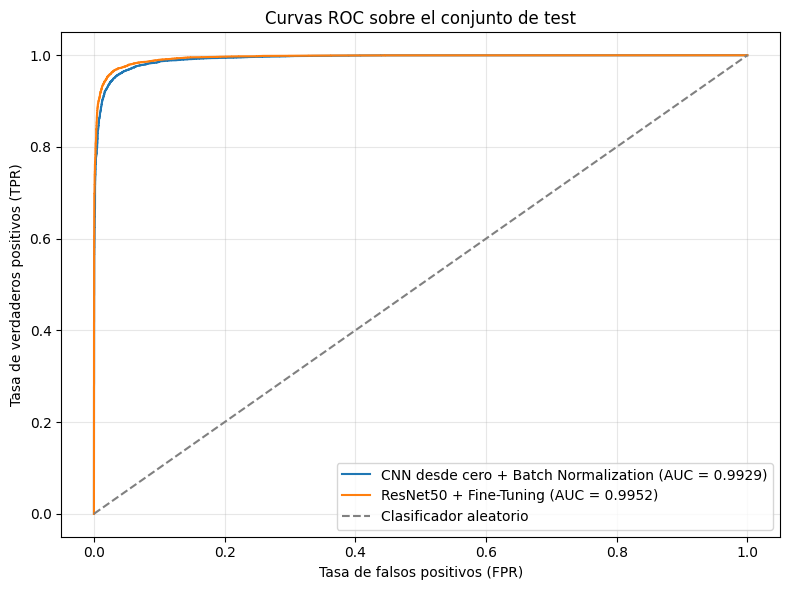

In [93]:
plt.figure(figsize=(8, 6))

for model_name, predictions in final_test_predictions.items():

    fpr, tpr, thresholds = roc_curve(
        predictions["y_true"],
        predictions["y_prob"]
    )

    auc_value = final_test_metrics[model_name]["test_roc_auc"]

    plt.plot(
        fpr,
        tpr,
        label=f"{model_name} (AUC = {auc_value:.4f})"
    )

# Clasificador aleatorio como referencia
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Clasificador aleatorio"
)

plt.xlabel("Tasa de falsos positivos (FPR)")
plt.ylabel("Tasa de verdaderos positivos (TPR)")
plt.title("Curvas ROC sobre el conjunto de test")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

En ambos casos, las curvas se sitúan muy próximas a la esquina superior izquierda y claramente por encima de la diagonal del clasificador aleatorio, lo que indica una elevada capacidad de discriminación.

Los valores del área bajo la curva (AUC) confirman este resultado: 0.9929 para la CNN desde cero y 0.9952 para ResNet50 + Fine-Tuning. Ambos valores son muy próximos a 1, lo que refleja un excelente rendimiento discriminativo. ResNet50 presenta una ligera ventaja, aunque la diferencia entre ambos modelos es pequeña y las curvas ROC son prácticamente coincidentes.

En conjunto, este análisis confirma que los dos modelos distinguen eficazmente entre imágenes FAKE y REAL en el conjunto de test, y vuelve a mostrar una ventaja moderada de ResNet50 + Fine-Tuning, en consonancia con los resultados obtenidos mediante las demás métricas de evaluación.

## 6.5. Comparación de la capacidad de generalización

A continuación se comparan los resultados obtenidos sobre los conjuntos de validación y test para evaluar la capacidad de generalización de ambos modelos.

In [94]:
selected_experiments = {
    "CNN desde cero + Batch Normalization":
        "regularization_batch_norm",

    "ResNet50 + Fine-Tuning":
        "fine_tuning_resnet50"
}

generalization_rows = []

for model_name, experiment_name in selected_experiments.items():

    val_metrics = experiment_metrics[experiment_name]
    test_metrics = final_test_metrics[model_name]

    generalization_rows.append({
        "Modelo": model_name,

        "Val accuracy": val_metrics["val_accuracy"],
        "Test accuracy": test_metrics["test_accuracy"],
        "Diferencia accuracy": (
            test_metrics["test_accuracy"]
            - val_metrics["val_accuracy"]
        ),

        "Val Macro F1": val_metrics["val_macro_f1"],
        "Test Macro F1": test_metrics["test_macro_f1"],
        "Diferencia Macro F1": (
            test_metrics["test_macro_f1"]
            - val_metrics["val_macro_f1"]
        )
    })

generalization_df = pd.DataFrame(
    generalization_rows
).set_index("Modelo")

display(
    generalization_df.style.format("{:.4f}")
)

,Val accuracy,Test accuracy,Diferencia accuracy,Val Macro F1,Test Macro F1,Diferencia Macro F1
Modelo,,,,,,
CNN desde cero + Batch Normalization,0.9607,0.9596,-0.0012,0.9607,0.9596,-0.0012
ResNet50 + Fine-Tuning,0.9653,0.9648,-0.0005,0.9653,0.9648,-0.0005


La tabla permite comparar el rendimiento de ambos modelos sobre los conjuntos de validación y test, con el objetivo de evaluar su capacidad de generalización sobre datos no utilizados durante el entrenamiento. Los resultados muestran que la diferencia entre ambos conjuntos es muy reducida en los dos modelos.

En la CNN desde cero + Batch Normalization, tanto la accuracy como el Macro F1 disminuyen únicamente 0.0012 entre validación y test. En ResNet50 + Fine-Tuning, la diferencia es todavía menor, de 0.0005. Por tanto, ninguno de los modelos experimenta una pérdida de rendimiento relevante al pasar del conjunto de validación al de test.

Estos resultados indican que ambos modelos presentan una buena capacidad de generalización y que no se observa un deterioro significativo del rendimiento sobre datos independientes. Además, ResNet50 + Fine-Tuning mantiene los mejores resultados en ambos conjuntos y presenta una diferencia ligeramente menor entre validación y test. En consecuencia, puede considerarse que ofrece el mejor rendimiento global de los dos modelos evaluados.

## 6.6. Conclusiones de la evaluación final

La evaluación final sobre el conjunto de test confirma el buen rendimiento de los dos modelos seleccionados. Ambos consiguen una elevada capacidad de clasificación, con una accuracy y un Macro F1 superiores al 95 %, así como valores de AUC próximos a 1. Esto demuestra que los dos modelos son capaces de distinguir eficazmente entre las imágenes FAKE y REAL del conjunto de datos.

Entre ellos, **ResNet50 + Fine-Tuning obtiene los mejores resultados globales**, alcanzando una accuracy del 96.48 %, un Macro F1 del 96.48 % y un AUC de 0.9952. La CNN desde cero con Batch Normalization también presenta un rendimiento elevado, con una accuracy del 95.96 %, un Macro F1 del 95.96 % y un AUC de 0.9929. Las matrices de confusión refuerzan esta diferencia: ResNet50 comete 702 errores de clasificación, frente a los 807 de la CNN, principalmente gracias a una mejor identificación de las imágenes FAKE.

La comparación entre validación y test muestra, además, que ambos modelos generalizan correctamente. Las diferencias en accuracy y Macro F1 son inferiores a 0.12 puntos porcentuales en ambos casos, por lo que no se observa una degradación significativa del rendimiento al evaluar los modelos sobre datos independientes.

No obstante, la ventaja de ResNet50 debe valorarse teniendo en cuenta su mayor complejidad computacional. Su arquitectura cuenta con aproximadamente 23.85 millones de parámetros, frente a los 111000 de la CNN desde cero, es decir, más de 200 veces más. Asimismo, su tiempo de inferencia es considerablemente mayor. Por tanto, aunque ResNet50 constituye la mejor alternativa cuando se prioriza la precisión de clasificación, la CNN desde cero representa una opción atractiva cuando se busca reducir el coste computacional y el tiempo de inferencia, manteniendo unas métricas competitivas.

En conclusión, **se selecciona ResNet50 + Fine-Tuning como el modelo con mejor rendimiento predictivo**, mientras que la CNN desde cero demuestra que es posible obtener resultados muy satisfactorios con una arquitectura mucho más sencilla. Finalmente, cabe señalar que las conclusiones están limitadas a las características del dataset CIFAKE utilizado, por lo que los resultados no permiten asegurar que los modelos generalicen de la misma manera ante imágenes sintéticas generadas por otros modelos o distribuciones.

# 7. Conclusiones generales y posibles líneas de mejora

El objetivo de este proyecto ha sido desarrollar y comparar dos estrategias de aprendizaje profundo para abordar un problema de clasificación de imágenes: el entrenamiento de una red neuronal convolucional desde cero y la adaptación de arquitecturas preentrenadas mediante *Transfer Learning* y *Fine-Tuning*. Para ello, se ha utilizado el dataset CIFAKE, que contiene imágenes reales y sintéticas.

En primer lugar, el desarrollo de la CNN desde cero ha permitido analizar experimentalmente cómo afectan las decisiones de arquitectura, configuración y regularización al rendimiento del modelo. La experimentación con diferentes optimizadores, tasas de aprendizaje, tamaños de batch y funciones de activación permitió establecer una configuración de referencia adecuada. Asimismo, se evaluaron distintas técnicas de regularización, entre las que destacó Batch Normalization, que proporcionó los mejores resultados de clasificación. La red final, formada por tres bloques convolucionales y una capa densa, alcanzó una accuracy del 95.96 % sobre el conjunto de test, demostrando que es posible obtener un rendimiento elevado mediante una arquitectura relativamente sencilla y entrenada íntegramente desde cero.

En segundo lugar, se compararon dos arquitecturas preentrenadas sobre ImageNet: MobileNetV2 y ResNet50. Los resultados mostraron que el uso directo de las características preentrenadas mediante Transfer Learning ofrecía un buen punto de partida, aunque ambas arquitecturas presentaban signos de sobreajuste. La aplicación posterior de Fine-Tuning permitió adaptar parte de los pesos de las redes al problema específico y mejorar sustancialmente su rendimiento. Esta mejora fue especialmente significativa en MobileNetV2, aunque ResNet50 mantuvo los mejores resultados globales, por lo que fue seleccionada como la arquitectura preentrenada más adecuada.

La evaluación final sobre el conjunto de test confirmó la ventaja de ResNet50 + Fine-Tuning, que alcanzó una accuracy del 96.48 %, un Macro F1 del 96.48 % y un AUC de 0.9952. La CNN desde cero + Batch Normalization obtuvo, respectivamente, un 95.96 %, un 95.96 % y un AUC de 0.9929. Las matrices de confusión y las curvas ROC respaldan estos resultados y muestran que ambos modelos presentan una elevada capacidad para distinguir entre las dos categorías. Además, la reducida diferencia entre las métricas de validación y test indica que los dos modelos mantienen un rendimiento consistente sobre datos independientes, sin evidencias de una pérdida significativa de capacidad de generalización.

No obstante, la mejora obtenida con ResNet50 debe valorarse teniendo en cuenta su mayor complejidad. Su arquitectura cuenta con aproximadamente 23.85 millones de parámetros, frente a los 111000 de la CNN desde cero, lo que supone más de 200 veces más parámetros. Esta diferencia también se refleja en un coste de inferencia considerablemente superior. Por tanto, la elección entre ambas soluciones depende de los requisitos de la aplicación: ResNet50 + Fine-Tuning es la alternativa preferible cuando se prioriza maximizar el rendimiento predictivo, mientras que la CNN desde cero puede resultar más adecuada cuando se busca una solución más ligera y eficiente, aceptando una pequeña reducción de las métricas de clasificación.

Por último, es importante considerar las limitaciones del conjunto de datos utilizado. CIFAKE contiene imágenes reales procedentes de CIFAR-10 e imágenes sintéticas generadas mediante Stable Diffusion 1.4. Por tanto, los resultados obtenidos demuestran la capacidad de los modelos para distinguir entre las distribuciones de imágenes presentes en este dataset, pero no permiten asegurar que mantengan el mismo rendimiento ante imágenes generadas por otros modelos o mediante técnicas diferentes.

Como posibles líneas de mejora, sería interesante ampliar la diversidad del conjunto de datos incorporando imágenes sintéticas procedentes de distintos generadores y fuentes de imágenes reales, con el objetivo de evaluar la robustez de los modelos frente a distribuciones no conocidas durante el entrenamiento. También sería interesante estudiar técnicas de compresión, cuantización o poda de redes neuronales para reducir el coste computacional de ResNet50 y facilitar su despliegue en entornos con recursos limitados. Finalmente, podría explorarse el uso de arquitecturas más eficientes o estrategias de entrenamiento alternativas que permitan mejorar el equilibrio entre rendimiento predictivo y coste de inferencia.

En conclusión, el proyecto ha permitido comprobar experimentalmente las ventajas y limitaciones de las dos estrategias planteadas. Aunque ResNet50 + Fine-Tuning proporciona el mejor rendimiento global, la CNN entrenada desde cero demuestra que una arquitectura mucho más sencilla puede alcanzar resultados competitivos. De este modo, no existe una solución universalmente superior, sino que la elección del modelo más adecuado debe considerar conjuntamente la precisión de clasificación, la capacidad de generalización y los recursos computacionales disponibles.

## Referencias


*   Krizhevsky, A., & Hinton, G. (2009). Learning multiple layers of features from tiny images.
*   J. J. Bird and A. Lotfi, "CIFAKE: Image Classification and Explainable Identification of AI-Generated Synthetic Images," in IEEE Access, vol. 12, pp. 15642-15650, 2024, doi: 10.1109/ACCESS.2024.3356122
*   Sandler et al. (2018), MobileNetV2: Inverted Residuals and Linear Bottlenecks.
*   He et al. (2016), Deep Residual Learning for Image Recognition.

